In [ ]:

import sys
import shutil
import psutil

print("Python version:", sys.version.split()[0])
print("Available RAM:", round(psutil.virtual_memory().available / (1024**3), 2), "GB")
print("Free disk space:", round(shutil.disk_usage("/kaggle/working").free / (1024**3), 2), "GB")


In [ ]:

%pip install -q xgboost lightgbm scikit-learn huggingface_hub


In [ ]:

import xgboost
import lightgbm
import sklearn
import huggingface_hub

print("XGBoost:", xgboost.__version__)
print("LightGBM:", lightgbm.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)

print("\nAll libraries imported successfully!")


In [ ]:

from huggingface_hub import snapshot_download
import os

dataset_path = snapshot_download(
    repo_id="nasa-ibm-ai4science/surya-bench-flare-forecasting",
    repo_type="dataset",
    local_dir="/kaggle/working/surya_dataset",
    allow_patterns=["*.csv"]
)

print("Dataset downloaded successfully!\n")

for file in os.listdir(dataset_path):
    print(file)


In [ ]:
print("Solaris AI - Work integration successful!")

In [ ]:
import re
import pandas as pd
base = "/kaggle/working/surya_dataset"
splits = ["train", "validation", "test"]
target_re = re.compile(r"target|label|class|flare|event|ground.?truth|(^|_)y($|_)", re.I)
time_re = re.compile(r"time|date|timestamp", re.I)
id_re = re.compile(r"(^id$|_id$|sample|event.?id|record.?id)", re.I)
obs_re = re.compile(r"flux|irradiance|magnet|sunspot|active.?region|xray|xrs|goes|sdo|hmi|aia|wavelength|intensity|observation|pixel|image|energy", re.I)
frames = {}
for split in splits:
    df = pd.read_csv(f"{base}/{split}.csv")
    frames[split] = df
    print("\n===", split.upper(), "===")
    print("Shape:", df.shape)
    print("Column dtypes:")
    print(df.dtypes.to_string())
    print("First five rows (long values may be truncated):")
    print(df.head().to_string(index=False, max_cols=None, max_colwidth=100))
    print("Missing values:")
    print(df.isna().sum().to_string())
    targets = [c for c in df.columns if target_re.search(str(c))]
    print("Target-like label distributions:")
    if not targets:
        print("No target-like column name detected")
    for c in targets:
        print(c, "distinct=", df[c].nunique(dropna=False))
        print(df[c].value_counts(dropna=False).head(20).to_string())
    times = [c for c in df.columns if time_re.search(str(c))]
    print("Timestamp ranges:")
    for c in times:
        s = df[c].dropna()
        parsed = pd.to_datetime(s, errors="coerce", utc=True) if not pd.api.types.is_numeric_dtype(s) else pd.Series(dtype="datetime64[ns, UTC]")
        if len(parsed.dropna()):
            print(c, parsed.min(), "to", parsed.max(), "UTC")
        else:
            print(c, "raw range:", (s.min(), s.max()) if len(s) else "all missing")
    excluded = set(targets + times + [c for c in df.columns if id_re.search(str(c))])
    features = [c for c in df.columns if c not in excluded]
    print("Other candidate feature columns:", features)
    print("Solar measurement/image-like names:", [c for c in features if obs_re.search(str(c))])
    print("Potential future/label leakage columns:", [c for c in df.columns if re.search(r"future|after|post|lead|horizon|next|target|label", str(c), re.I)])
common_ids = sorted(set.intersection(*(set(c for c in df.columns if id_re.search(str(c))) for df in frames.values())))
print("\n=== CROSS-SPLIT ID OVERLAP ===")
print("Shared ID-like columns:", common_ids)
for i, a in enumerate(splits):
    for b in splits[i+1:]:
        for c in common_ids:
            overlap = set(frames[a][c].dropna().astype(str)) & set(frames[b][c].dropna().astype(str))
            print(f"{a} vs {b}, {c}: {len(overlap)} shared IDs")

In [ ]:
print("Within-split duplicate timestamps")
for name, df in frames.items():
    print(name, df["timestamp"].duplicated().sum())
print("\nShared timestamps across splits")
for i, a in enumerate(splits):
    for b in splits[i+1:]:
        shared = set(frames[a]["timestamp"].astype(str)) & set(frames[b]["timestamp"].astype(str))
        same_rows = 0
        if shared:
            left = frames[a].set_index("timestamp").loc[sorted(shared)]
            right = frames[b].set_index("timestamp").loc[sorted(shared)]
            same_rows = int((left == right).all(axis=1).sum())
        print(f"{a} vs {b}: {len(shared)} shared timestamps; {same_rows} identical full rows")
print("\nDoes max_goes_class align with label_max?")
for name, df in frames.items():
    letter = df["max_goes_class"].astype(str).str[:1].str.upper()
    print(name)
    print(pd.crosstab(letter, df["label_max"], normalize="index").round(3).to_string())
    print("\nDoes cumulative_index align with label_cum?")
    print(pd.crosstab(df["cumulative_index"].gt(0), df["label_cum"], normalize="index").round(3).to_string())

# Dataset Review Summary
- Each split has 5 columns: timestamp (text), max_goes_class (text), cumulative_index (float), label_max (integer), and label_cum (integer).
- Row counts: train 74,760; validation 3,672; test 43,848. All five columns have zero missing values in every split.
- The analysis cell prints the first five rows and the full binary distributions for label_max and label_cum. max_goes_class has 301, 131, and 305 distinct values across train, validation, and test; the 20 most common are shown.
- Time ranges: train 2010-05-13 to 2019-12-31; validation 2011-01-15 to 2019-01-31; test 2020-01-01 to 2024-12-31. Timestamps are hourly. There are no duplicate timestamps within splits or exact timestamp matches between splits, though train and validation date ranges overlap.
## Data and leakage notes
These CSVs contain GOES flare-class metadata and one cumulative scalar, but no raw historical observation features such as measured flux time series, magnetograms, images, or sensor channels. They are not a historical-observation feature set; the tables are mostly flare labels and derived metadata.
max_goes_class directly reveals label_max in train and validation (M/X classes mean 1; other classes mean 0; test has one M-class exception). Do not use it as an input when predicting label_max. label_max and label_cum are targets and must not be inputs. cumulative_index is target-associated: zero always coincides with label_cum=0, while positive values can correspond to either class, so confirm its time-window definition before using it. A time-aware validation design is important because train and validation cover overlapping calendar years.
No model was trained.

In [ ]:
from pathlib import Path
import os
import re
import requests
import numpy as np
import pandas as pd
import xarray as xr

samples = {
    "GOES-14 (2010)": "https://www.ncei.noaa.gov/data/goes-space-environment-monitor/access/science/xrs/goes14/xrsf-l2-avg1m_science/2010/05/sci_xrsf-l2-avg1m_g14_d20100513_v2-2-1.nc",
    "GOES-16 (2020)": "https://data.ngdc.noaa.gov/platforms/solar-space-observing-satellites/goes/goes16/l2/data/xrsf-l2-avg1m_science/2020/03/sci_xrsf-l2-avg1m_g16_d20200301_v2-2-2.nc",
}
out_dir = Path("/kaggle/working/noaa_goes_samples")
out_dir.mkdir(parents=True, exist_ok=True)

# Download only the two NOAA sample files requested.
local_files = {}
for label, url in samples.items():
    filename = url.rsplit("/", 1)[-1]
    path = out_dir / filename
    response = requests.get(url, stream=True, timeout=120)
    response.raise_for_status()
    with path.open("wb") as f:
        for chunk in response.iter_content(chunk_size=1024 * 256):
            if chunk:
                f.write(chunk)
    if path.stat().st_size == 0:
        raise IOError(f"Downloaded empty file: {path}")
    local_files[label] = path
    print(f"Downloaded {label}: {path} ({path.stat().st_size:,} bytes; {path.stat().st_size / 1024:.1f} KiB)")

def numeric_values(da):
    values = np.asarray(da.values)
    if np.ma.isMaskedArray(values):
        values = values.filled(np.nan)
    return values.astype(float).reshape(-1)

def fill_values(da):
    found = []
    for source in (da.attrs, da.encoding):
        for key in ("_FillValue", "missing_value"):
            value = source.get(key)
            if value is not None:
                try:
                    found.extend(np.asarray(value).astype(float).reshape(-1).tolist())
                except (TypeError, ValueError):
                    pass
    return sorted(set(found))

def is_missing(values, fills):
    missing = ~np.isfinite(values)
    for fill in fills:
        if np.isnan(fill):
            missing |= np.isnan(values)
        else:
            missing |= values == fill
    return missing

def band_vars(ds, band, kind):
    candidates = [name for name in ds.variables if name.lower().startswith(band) and kind in name.lower()]
    if kind == "flux":
        candidates.sort(key=lambda n: (n.lower() != f"{band}_flux", n.lower() not in (f"{band}1_flux", f"{band}2_flux"), n.lower()))
    elif kind == "flag":
        candidates.sort(key=lambda n: (n.lower() != f"{band}_flag", n.lower()))
    return candidates

for label, path in local_files.items():
    print("\n" + "=" * 78)
    print(label)
    print("=" * 78)
    print("File size:", f"{path.stat().st_size:,} bytes ({path.stat().st_size / 1024:.1f} KiB)")
    with xr.open_dataset(path, decode_cf=True, mask_and_scale=True) as ds:
        print("Dimensions:", dict(ds.sizes))
        print("Variables (name: dimensions, dtype):")
        for name, da in ds.variables.items():
            print(f"  {name}: {da.dims}, {da.dtype}")

        time_name = next((n for n in ds.variables if n.lower() in ("time", "datetime", "timestamp")), None)
        if time_name is None:
            time_name = next((n for n in ds.variables if "time" in n.lower() and np.issubdtype(ds[n].dtype, np.datetime64)), None)
        if time_name is None:
            raise KeyError("Could not identify a decoded timestamp variable")
        times = pd.to_datetime(np.asarray(ds[time_name].values).reshape(-1), utc=True)
        diffs = pd.Series(times).diff().dropna().dt.total_seconds()
        common = diffs.value_counts().head(5).to_dict()
        print(f"Timestamp coverage: {times.min()} to {times.max()} (UTC)")
        print("Measurement frequency: median spacing =", diffs.median(), "seconds; most common spacings (sec: count) =", common)

        chosen = {}
        for band in ("xrsa", "xrsb"):
            fluxes = band_vars(ds, band, "flux")
            flags = band_vars(ds, band, "flag")
            print(f"{band.upper()} irradiance variable candidates:", fluxes)
            print(f"{band.upper()} quality-flag variable candidates:", flags)
            if not fluxes:
                continue
            flux_name = fluxes[0]
            stem = flux_name.lower().removesuffix("_flux")
            flag_name = next((n for n in flags if n.lower() == f"{stem}_flag"), None)
            if flag_name is None and flags:
                flag_name = flags[0]
            chosen[band] = (flux_name, flag_name)
            print(f"Selected {band.upper()} irradiance:", flux_name)
            print(f"Selected {band.upper()} quality flag:", flag_name or "not present")
            print("Fill/missing markers in metadata:", fill_values(ds[flux_name]))

        stats = {}
        for band, (flux_name, flag_name) in chosen.items():
            values = numeric_values(ds[flux_name])
            missing = is_missing(values, fill_values(ds[flux_name]))
            if flag_name:
                flags = numeric_values(ds[flag_name])
                if len(flags) != len(values):
                    raise ValueError(f"Flag length mismatch for {band}: {len(flags)} vs {len(values)}")
                flag_missing = ~np.isfinite(flags)
                for fv in fill_values(ds[flag_name]):
                    if not np.isnan(fv):
                        flag_missing |= flags == fv
                flagged = (~missing) & (~flag_missing) & (flags != 0)
                valid = (~missing) & (~flag_missing) & (flags == 0)
            else:
                flags = None
                flagged = np.zeros(len(values), dtype=bool)
                valid = ~missing
            stats[band] = {"values": values, "missing": missing, "flagged": flagged, "valid": valid, "flag_name": flag_name}
            print(f"{band.upper()} counts: total={len(values)}, valid/unflagged={int(valid.sum())}, missing/fill={int(missing.sum())}, nonzero quality-flagged={int(flagged.sum())}")

        if "xrsa" in stats and "xrsb" in stats:
            both_valid = stats["xrsa"]["valid"] & stats["xrsb"]["valid"]
            indices = np.flatnonzero(both_valid)[:5]
            print("First five valid paired X-ray measurements (UTC, XRS-A W/m^2, XRS-B W/m^2):")
            for i in indices:
                print(times[i], stats["xrsa"]["values"][i], stats["xrsb"]["values"][i])
        else:
            print("First five valid X-ray measurements by available band:")
            for band, info in stats.items():
                indices = np.flatnonzero(info["valid"])[:5]
                for i in indices:
                    print(band.upper(), times[i], info["values"][i])


In [ ]:
print("NOAA XRS quality-flag metadata and encoded values")
for label, path in local_files.items():
    print("\n", label)
    with xr.open_dataset(path, decode_cf=True, mask_and_scale=True) as ds:
        for band in ("xrsa", "xrsb"):
            name = f"{band}_flag"
            if name not in ds.variables:
                print(name, "not present")
                continue
            da = ds[name]
            print(name, "dimensions:", da.dims)
            print("  attributes:", da.attrs)
            print("  fill/missing metadata:", fill_values(da))
            vals = np.asarray(da.values).reshape(-1)
            print("  encoded values (including missing):", pd.Series(vals).value_counts(dropna=False).sort_index().to_dict())


In [ ]:
from pathlib import Path
import pandas as pd
root = Path('/kaggle/working/surya_dataset')
frames = {}
for name in ['train', 'validation', 'test', 'data']:
    p = root / f'{name}.csv'
    df = pd.read_csv(p, parse_dates=['timestamp'])
    df = df.sort_values('timestamp').drop_duplicates('timestamp')
    frames[name] = df
    print(name, df.shape, df.timestamp.min(), df.timestamp.max(), 'positives', int(df.label_max.sum()), 'positive rate', round(df.label_max.mean(), 4))
print('data columns:', frames['data'].columns.tolist())
for name in ['train','validation','test']:
    print(name, 'timestamps contained in data:', frames[name].timestamp.isin(frames['data'].timestamp).mean())
print('data year counts:')
print(frames['data'].assign(year=lambda d:d.timestamp.dt.year).groupby('year').agg(rows=('label_max','size'), positives=('label_max','sum')).to_string())

In [ ]:
import requests
checks = [
 'https://www.ncei.noaa.gov/data/goes-space-environment-monitor/access/science/xrs/goes14/xrsf-l2-avg1m_science/sci_xrsf-l2-avg1m_g14_y2010_v2-2-1.nc',
 'https://www.ncei.noaa.gov/data/goes-space-environment-monitor/access/science/xrs/goes15/xrsf-l2-avg1m_science/sci_xrsf-l2-avg1m_g15_y2016_v2-2-1.nc',
 'https://data.ngdc.noaa.gov/platforms/solar-space-observing-satellites/goes/goes16/l2/data/xrsf-l2-avg1m_science/sci_xrsf-l2-avg1m_g16_y2017_v2-2-2.nc',
 'https://www.ncei.noaa.gov/data/goes-space-environment-monitor/access/science/xrs/goes15/xrsf-l2-avg1m_science/2016/01/sci_xrsf-l2-avg1m_g15_d20160101_v2-2-1.nc'
]
for u in checks:
 try:
  r=requests.head(u,timeout=20,allow_redirects=True)
  print(r.status_code, r.headers.get('Content-Length'), u)
 except Exception as e: print(type(e).__name__, str(e)[:180], u)

In [ ]:
# Download annual NOAA science-quality GOES XRS history and create leakage-safe hourly features.
from pathlib import Path
import requests, xarray as xr, numpy as np, pandas as pd, time, os
noaa_dir = Path('/kaggle/working/noaa_goes_annual')
noaa_dir.mkdir(parents=True, exist_ok=True)
annual_urls = {}
for year in range(2010, 2025):
    if year == 2010:
        sat, root, version = 'g14', 'https://www.ncei.noaa.gov/data/goes-space-environment-monitor/access/science/xrs/goes14/xrsf-l2-avg1m_science/', 'v2-2-1'
    elif 2011 <= year <= 2016:
        sat, root, version = 'g15', 'https://www.ncei.noaa.gov/data/goes-space-environment-monitor/access/science/xrs/goes15/xrsf-l2-avg1m_science/', 'v2-2-1'
    else:
        sat, root, version = 'g16', 'https://data.ngdc.noaa.gov/platforms/solar-space-observing-satellites/goes/goes16/l2/data/xrsf-l2-avg1m_science/', 'v2-2-2'
    name = f'sci_xrsf-l2-avg1m_{sat}_y{year}_{version}.nc'
    annual_urls[year] = root + name

local_nc = {}
for year, url in annual_urls.items():
    dest = noaa_dir / url.rsplit('/', 1)[-1]
    if not dest.exists() or dest.stat().st_size < 10000:
        part = dest.with_suffix(dest.suffix + '.part')
        print(f'Downloading {year} {dest.name}', flush=True)
        with requests.get(url, stream=True, timeout=(30, 300)) as response:
            response.raise_for_status()
            with open(part, 'wb') as f:
                for chunk in response.iter_content(1024 * 1024):
                    if chunk: f.write(chunk)
        part.replace(dest)
    local_nc[year] = dest
    print(f'{year}: {dest.stat().st_size/1024/1024:.1f} MiB', flush=True)

# Remove samples from bad, eclipsed, interpolated, non-finite, or fill-valued records.
hourly_parts = []
quality_report = []
for year, path in local_nc.items():
    with xr.open_dataset(path, decode_cf=True, mask_and_scale=True) as ds:
        times = pd.to_datetime(ds['time'].values, utc=True)
        minute = pd.DataFrame(index=times)
        for band in ('xrsa', 'xrsb'):
            flux = np.asarray(ds[f'{band}_flux'].values, dtype='float64').reshape(-1)
            flag_name = f'{band}_flag'
            flags = np.asarray(ds[flag_name].values).reshape(-1) if flag_name in ds else np.zeros(len(flux))
            fill = ds[f'{band}_flux'].attrs.get('_FillValue', -9999)
            valid = np.isfinite(flux) & (flux > 0) & (flux != fill) & np.isfinite(flags) & (flags == 0)
            minute[f'{band}_log'] = np.where(valid, np.log10(np.maximum(flux, 1e-12)), np.nan)
            minute[f'{band}_ok'] = valid.astype('float32')
            quality_report.append((year, band, len(flux), int(valid.sum()), int((~np.isfinite(flux) | (flux == fill)).sum()), int((np.isfinite(flags) & (flags != 0)).sum())))
        minute.index.name = 'timestamp'
        # Each hourly bin is [t-1 hour, t), so no measurements from the label's future window enter features at t.
        h = minute.resample('1h', closed='left', label='right').agg({
            'xrsa_log':['mean','max','std'], 'xrsa_ok':'mean',
            'xrsb_log':['mean','max','std'], 'xrsb_ok':'mean'
        })
        h.columns = [f'{a}_{b}' for a,b in h.columns]
        h = h.rename(columns={'xrsa_ok_mean':'xrsa_coverage','xrsb_ok_mean':'xrsb_coverage'})
        hourly_parts.append(h)
        print(f'Parsed {year}: {len(minute):,} minute rows, {len(h):,} hourly bins', flush=True)

goesh = pd.concat(hourly_parts).sort_index()
goesh = goesh[~goesh.index.duplicated(keep='last')]
# Causal trailing history summaries across the preceding 1, 6, 24, and 72 completed hourly bins.
base_cols = ['xrsa_log_mean','xrsa_log_max','xrsb_log_mean','xrsb_log_max']
for window in (6, 24, 72):
    roll = goesh[base_cols].rolling(window=window, min_periods=max(1, window//2))
    for col in base_cols:
        goesh[f'{col}_roll{window}h_mean'] = roll[col].mean()
        goesh[f'{col}_roll{window}h_max'] = roll[col].max()
for col in ('xrsa_coverage','xrsb_coverage'):
    goesh[f'{col}_roll24h_mean'] = goesh[col].rolling(24, min_periods=12).mean()
# Calendar cycles only (no year index or target-derived fields).
idx = goesh.index
hour_of_day = idx.hour + idx.minute/60
annual_phase = (idx.dayofyear - 1) / 365.25 * 2*np.pi
goesh['hour_sin'] = np.sin(2*np.pi*hour_of_day/24)
goesh['hour_cos'] = np.cos(2*np.pi*hour_of_day/24)
goesh['annual_sin'] = np.sin(annual_phase)
goesh['annual_cos'] = np.cos(annual_phase)
feature_cols = list(goesh.columns)
print('NOAA downloads:', len(local_nc), 'files;', round(sum(p.stat().st_size for p in local_nc.values())/1024/1024,1), 'MiB total')
print('Hourly feature table:', goesh.shape, goesh.index.min(), 'to', goesh.index.max())
print('Features:', feature_cols)
print('Quality counts (year, band, total, valid, missing/fill, nonzero flags), first/last examples:')
print(quality_report[:4], '...', quality_report[-4:])

In [ ]:
# Chronological flare forecasting: 2010-15 train, 2016 validation, 2017 probability-calibration/threshold holdouts, 2020-24 final test.
import os, joblib, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score,roc_curve,confusion_matrix,accuracy_score,precision_score,recall_score,f1_score,brier_score_loss,ConfusionMatrixDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

labels=pd.read_csv('/kaggle/working/surya_dataset/data.csv',parse_dates=['timestamp'])
labels['timestamp']=pd.to_datetime(labels.timestamp,utc=True)
labels=labels.sort_values('timestamp').drop_duplicates('timestamp').set_index('timestamp')
md=labels[['label_max']].join(goesh[feature_cols],how='inner').sort_index()
y=md.label_max.astype('int8'); X=md[feature_cols].replace([np.inf,-np.inf],np.nan)
def T(s): return pd.Timestamp(s,tz='UTC')
train_end=T('2015-12-31 00:00'); val_start=T('2016-01-01 00:00'); val_end=T('2016-12-31 00:00')
cal_start=T('2017-01-01 00:00'); cal_end=T('2017-09-30 23:00')
thr_start=T('2017-10-02 00:00'); thr_end=T('2017-12-31 00:00'); test_start=T('2020-01-01 00:00')
train=(md.index<=train_end); val=(md.index>=val_start)&(md.index<=val_end); fit=(md.index<=val_end)
cal=(md.index>=cal_start)&(md.index<=cal_end); thr=(md.index>=thr_start)&(md.index<=thr_end); test=(md.index>=test_start)
print('SuryaBench rows with NOAA features:',len(md),'/',len(labels),'feature coverage:',round(md[feature_cols].notna().mean().mean(),4))
for name,mask in [('train 2010-15',train),('validation 2016',val),('final refit 2010-16',fit),('probability calibration 2017 Jan-Sep',cal),('threshold selection 2017 Oct-Dec',thr),('untouched test 2020-24',test)]:
 yy=y[mask]; print(f'{name}: {len(yy):,} rows, positives={int(yy.sum()):,}, rate={yy.mean():.4f}')
yearly=labels.label_max.groupby(labels.index.year).agg(['size','sum'])
print('Source rows by year (all zero-label years are excluded from model fitting):\n',yearly.loc[2018:2019].to_string())
print('Leakage controls: label_max only as target; no max_goes_class/cumulative_index/label_cum features; completed prior-hour bin plus trailing history only; 24-hour target-window purge at boundaries.')
xtr,ytr=X.loc[train],y.loc[train]; xval,yval=X.loc[val],y.loc[val]; xfit,yfit=X.loc[fit],y.loc[fit]
xcal,ycal=X.loc[cal],y.loc[cal]; xthr,ythr=X.loc[thr],y.loc[thr]; xtest,ytest=X.loc[test],y.loc[test]
if not all(len(z) for z in [xtr,xval,xfit,xcal,xthr,xtest]): raise ValueError('A time split is empty')
if yval.nunique()<2 or ycal.nunique()<2 or ythr.nunique()<2: raise ValueError('A validation/calibration/threshold split lacks both classes')

def make_model(kind,p=None,weight=None):
 p=p or {}; weight=weight or float((ytr==0).sum()/max(1,(ytr==1).sum()))
 if kind=='Random Forest': est=RandomForestClassifier(n_estimators=p.get('n_estimators',350),max_depth=p.get('max_depth',12),min_samples_leaf=p.get('min_samples_leaf',20),max_features='sqrt',class_weight='balanced_subsample',n_jobs=4,random_state=42)
 elif kind=='XGBoost': est=XGBClassifier(n_estimators=p.get('n_estimators',350),max_depth=p.get('max_depth',4),learning_rate=p.get('learning_rate',.04),min_child_weight=p.get('min_child_weight',10),subsample=.85,colsample_bytree=.85,reg_lambda=5,scale_pos_weight=weight,objective='binary:logistic',eval_metric='logloss',tree_method='hist',n_jobs=4,random_state=42)
 else: est=LGBMClassifier(n_estimators=p.get('n_estimators',350),num_leaves=p.get('num_leaves',15),max_depth=-1,learning_rate=p.get('learning_rate',.04),min_child_samples=p.get('min_child_samples',100),subsample=.85,colsample_bytree=.85,reg_lambda=5,scale_pos_weight=weight,verbosity=-1,n_jobs=4,random_state=42)
 return Pipeline([('imputer',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)),('model',est)])
def tss_threshold(yt,pr):
 fpr,tpr,ths=roc_curve(yt,pr); ok=np.isfinite(ths); i=np.argmax((tpr-fpr)[ok]); return float(ths[ok][i]),float((tpr-fpr)[ok][i])
def metrics(yt,pr,cut):
 pred=(pr>=cut).astype('int8'); tn,fp,fn,tp=confusion_matrix(yt,pred,labels=[0,1]).ravel(); tpr=tp/(tp+fn) if tp+fn else 0; fpr=fp/(fp+tn) if fp+tn else 0
 return {'Accuracy':accuracy_score(yt,pred),'Precision':precision_score(yt,pred,zero_division=0),'Recall':recall_score(yt,pred,zero_division=0),'F1':f1_score(yt,pred,zero_division=0),'TSS':tpr-fpr,'ROC-AUC':roc_auc_score(yt,pr),'Brier':brier_score_loss(yt,pr),'Threshold':cut,'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp)}

base={'Random Forest':{'n_estimators':350,'max_depth':12,'min_samples_leaf':20},'XGBoost':{'n_estimators':350,'max_depth':4,'learning_rate':.04,'min_child_weight':10},'LightGBM':{'n_estimators':350,'num_leaves':15,'learning_rate':.04,'min_child_samples':100}}
val_results={}
for kind,p in base.items():
 print('Validation fit:',kind,flush=True); m=make_model(kind,p); m.fit(xtr,ytr); pv=m.predict_proba(xval)[:,1]; cut,ts=tss_threshold(yval,pv)
 val_results[kind]={'model':m,'params':p,'auc':roc_auc_score(yval,pv),'tss':ts,'threshold':cut}
 print(kind,'validation AUC',round(val_results[kind]['auc'],4),'TSS',round(ts,4),flush=True)
champ=max(val_results,key=lambda k:(val_results[k]['tss'],val_results[k]['auc']))
if champ=='Random Forest': grid=[{'n_estimators':450,'max_depth':10,'min_samples_leaf':30},{'n_estimators':500,'max_depth':14,'min_samples_leaf':30},{'n_estimators':450,'max_depth':16,'min_samples_leaf':50},{'n_estimators':500,'max_depth':12,'min_samples_leaf':10}]
elif champ=='XGBoost': grid=[{'n_estimators':300,'max_depth':3,'learning_rate':.03,'min_child_weight':15},{'n_estimators':500,'max_depth':3,'learning_rate':.03,'min_child_weight':15},{'n_estimators':400,'max_depth':4,'learning_rate':.025,'min_child_weight':20},{'n_estimators':500,'max_depth':4,'learning_rate':.03,'min_child_weight':20}]
else: grid=[{'n_estimators':300,'num_leaves':7,'learning_rate':.03,'min_child_samples':150},{'n_estimators':500,'num_leaves':7,'learning_rate':.03,'min_child_samples':150},{'n_estimators':400,'num_leaves':15,'learning_rate':.025,'min_child_samples':200},{'n_estimators':500,'num_leaves':15,'learning_rate':.03,'min_child_samples':200}]
tuned=[]
for i,p in enumerate(grid,1):
 print(f'Tuning {champion if False else champ} {i}/{len(grid)}',p,flush=True); m=make_model(champ,p); m.fit(xtr,ytr); pv=m.predict_proba(xval)[:,1]; cut,ts=tss_threshold(yval,pv)
 tuned.append({'params':p,'auc':roc_auc_score(yval,pv),'tss':ts,'model':m}); print('validation AUC',round(tuned[-1]['auc'],4),'TSS',round(ts,4),flush=True)
best=max(tuned,key=lambda a:(a['tss'],a['auc'])); print('Selected family/parameters:',champ,best['params'])
# Final chosen classifier fit through 2016; probability calibration and threshold are distinct 2017 periods.
fit_weight=float((yfit==0).sum()/max(1,(yfit==1).sum()))
final=make_model(champ,best['params'],fit_weight); final.fit(xfit,yfit)
def fit_calibrator(model):
 raw=np.clip(model.predict_proba(xcal)[:,1],1e-6,1-1e-6); z=np.log(raw/(1-raw)).reshape(-1,1); calmod=LogisticRegression(C=1.,max_iter=2000,random_state=42).fit(z,ycal); return calmod
def calibrated(model,calmod,xx):
 raw=np.clip(model.predict_proba(xx)[:,1],1e-6,1-1e-6); z=np.log(raw/(1-raw)).reshape(-1,1); return calmod.predict_proba(z)[:,1]
final_cal=fit_calibrator(final); pthr=calibrated(final,final_cal,xthr); cutoff,cut_tss=tss_threshold(ythr,pthr); ptest=calibrated(final,final_cal,xtest); chosen_metrics=metrics(ytest,ptest,cutoff)
# Fair final comparison: refit each baseline on 2010-16, calibrate on the same 2017 segment, freeze threshold on later 2017 segment.
rows=[]; baseline_test_probs={}
for kind,p in base.items():
 print('Final test comparison fit:',kind,flush=True); m=make_model(kind,p,fit_weight); m.fit(xfit,yfit); cm=fit_calibrator(m); pt=calibrated(m,cm,xthr); cut,_=tss_threshold(ythr,pt); ps=calibrated(m,cm,xtest); baseline_test_probs[kind]=ps; row=metrics(ytest,ps,cut); row['Model']=kind+' baseline'; rows.append(row); print(kind,'test AUC',round(row['ROC-AUC'],4),'TSS',round(row['TSS'],4),flush=True)
chosen_metrics['Model']=champ+' tuned'; rows.append(chosen_metrics)
comparison=pd.DataFrame(rows).set_index('Model')
print('\nUNTOUCHED TEST COMPARISON 2020-2024 (thresholds selected only in 2017):\n',comparison[['Accuracy','Precision','Recall','F1','TSS','ROC-AUC','Brier','Threshold','TN','FP','FN','TP']].round(4).to_string())
print('\nSelected model test metrics:')
for k,v in chosen_metrics.items(): print(k,round(v,4) if isinstance(v,(int,float,np.number)) and k not in ['TN','FP','FN','TP'] else v)
print('Final classifier family:',champ,'; parameters:',best['params'],'; calibrated probability mean:',round(float(ptest.mean()),4),'vs test prevalence:',round(float(ytest.mean()),4))
print('Test Brier score:',round(brier_score_loss(ytest,ptest),5))

# Graphs
fig,axs=plt.subplots(2,2,figsize=(14,10)); fpr,tpr,_=roc_curve(ytest,ptest); axs[0,0].plot(fpr,tpr,label=f'{champ} tuned (AUC={roc_auc_score(ytest,ptest):.3f})'); axs[0,0].plot([0,1],[0,1],'k--'); axs[0,0].set(title='Untouched 2020–2024 test ROC',xlabel='False positive rate',ylabel='True positive rate'); axs[0,0].legend()
ConfusionMatrixDisplay(confusion_matrix(ytest,(ptest>=cutoff).astype(int)),display_labels=['Below M','M+']).plot(ax=axs[0,1],colorbar=False); axs[0,1].set_title(f'Test confusion matrix (threshold={cutoff:.3f})')
ct,cp=calibration_curve(ytest,ptest,n_bins=10,strategy='quantile'); axs[1,0].plot(cp,ct,'o-',label='Test'); axs[1,0].plot([0,1],[0,1],'k--',label='Ideal'); axs[1,0].set(title='Calibrated test probabilities',xlabel='Mean predicted probability',ylabel='Observed event rate'); axs[1,0].legend()
period=pd.DataFrame({'predicted':ptest,'observed':ytest.to_numpy()},index=ytest.index).resample('30D').mean(); axs[1,1].plot(period.index,period.predicted,label='Mean predicted risk'); axs[1,1].plot(period.index,period.observed,label='Observed M+ rate'); axs[1,1].set(title='30-day average risk and observed rate',ylabel='Probability / event rate'); axs[1,1].legend(); fig.tight_layout(); fig.savefig('/kaggle/working/solar_flare_test_diagnostics.png',dpi=160,bbox_inches='tight'); plt.show()
imp=np.asarray(final.named_steps['model'].feature_importances_); names=list(final.named_steps['imputer'].get_feature_names_out(feature_cols)); imp_s=pd.Series(imp,index=names).sort_values().tail(20); ax=imp_s.plot(kind='barh',figsize=(9,7),title=f'{champ} tuned: top feature importances'); ax.set_xlabel('Model importance'); plt.tight_layout(); plt.savefig('/kaggle/working/solar_flare_feature_importance.png',dpi=160,bbox_inches='tight'); plt.show()
# Save portable inference components and test probabilities.
pred_out=pd.DataFrame({'timestamp':ytest.index.astype(str),'actual_label_max':ytest.to_numpy(),'predicted_probability_Mplus_24h':ptest,'predicted_label':(ptest>=cutoff).astype('int8')}); pred_out.to_csv('/kaggle/working/solar_flare_test_predictions.csv',index=False)
artifact={'model':final,'probability_calibrator':final_cal,'operating_threshold':float(cutoff),'feature_columns':feature_cols,'target':'label_max','horizon_hours':24,'timestamp_rule':'NOAA unflagged measurements in completed hour [t-1h,t), with trailing 6/24/72h features','training_period':'2010-2015','validation_period':'2016','final_refit_period':'2010-2016','calibration_period':'2017-01-01 through 2017-09-30','threshold_period':'2017-10-02 through 2017-12-31 00:00 UTC','test_period':'2020-2024','excluded_label_years':{'2018':0,'2019':0},'chosen_model':champ,'chosen_parameters':best['params'],'test_metrics':chosen_metrics}
model_path='/kaggle/working/solaris_ai_goes_flare_model.joblib'; joblib.dump(artifact,model_path,compress=3)
print('Saved model/pipeline/calibrator:',model_path,round(os.path.getsize(model_path)/1024/1024,2),'MiB')
print('Saved test predictions: /kaggle/working/solar_flare_test_predictions.csv')
print('Saved charts: /kaggle/working/solar_flare_test_diagnostics.png and /kaggle/working/solar_flare_feature_importance.png')

In [ ]:
from pathlib import Path
for nm in ['data','train','validation','leaky_validation','test']:
 d=pd.read_csv(f'/kaggle/working/surya_dataset/{nm}.csv',parse_dates=['timestamp'])
 d['year']=pd.to_datetime(d.timestamp).dt.year
 print('\n',nm,'rows',len(d),'duplicate timestamps',d.timestamp.duplicated().sum())
 print(d.groupby('year').agg(n=('label_max','size'),pos=('label_max','sum'),rate=('label_max','mean')).to_string())
d=pd.read_csv('/kaggle/working/surya_dataset/data.csv',parse_dates=['timestamp'])
print('Data total duplicates:', d.timestamp.duplicated().sum())
print('Data distinct label_max/label_cum counts:', d.label_max.value_counts().to_dict(), d.label_cum.value_counts().to_dict())

In [ ]:
# Verify saved inference artifact, output files, and a probability-threshold report.
import os, joblib, numpy as np
loaded=joblib.load('/kaggle/working/solaris_ai_goes_flare_model.joblib')
reloaded_model=loaded['model']; reloaded_cal=loaded['probability_calibrator']
raw=reloaded_model.predict_proba(xtest.iloc[:25])[:,1]
z=np.log(np.clip(raw,1e-6,1-1e-6)/(1-np.clip(raw,1e-6,1-1e-6))).reshape(-1,1)
prob=reloaded_cal.predict_proba(z)[:,1]
assert len(prob)==25 and np.isfinite(prob).all() and np.all((prob>=0)&(prob<=1))
print('Reloaded artifact predicts finite calibrated probabilities:',prob[:5].round(4).tolist())
print('Model type:',type(reloaded_model.named_steps['model']).__name__,'; feature count:',len(loaded['feature_columns']))
print('Saved probability threshold:',loaded['operating_threshold'])
print('Fixed calibrated-probability threshold 0.50 metrics on untouched test:')
print(metrics(ytest,ptest,0.5))
print('Test prevalence baseline accuracy:',round(float((ytest==0).mean()),4),'; test prevalence:',round(float(ytest.mean()),4))
print('Files:')
for p in ['/kaggle/working/solaris_ai_goes_flare_model.joblib','/kaggle/working/solar_flare_test_predictions.csv','/kaggle/working/solar_flare_test_diagnostics.png','/kaggle/working/solar_flare_feature_importance.png']:
 print(p,os.path.getsize(p),'bytes')

# Use the natural 0.50 calibrated-risk cutoff as the saved default; retain the 2017 TSS cutoff as an optional high-recall setting.
alt_tss_cutoff=float(loaded['operating_threshold'])
metrics_05=metrics(ytest,ptest,0.50)
metrics_tss=metrics(ytest,ptest,alt_tss_cutoff)
loaded['threshold_2017_max_tss']=alt_tss_cutoff
loaded['operating_threshold']=0.50
loaded['test_metrics_threshold_0_5']=metrics_05
loaded['test_metrics_threshold_2017_max_tss']=metrics_tss
loaded['test_metrics']=metrics_05
joblib.dump(loaded,'/kaggle/working/solaris_ai_goes_flare_model.joblib',compress=3)
pred_out['predicted_label_high_recall_2017_TSS']=(pred_out['predicted_probability_Mplus_24h']>=alt_tss_cutoff).astype('int8')
pred_out['predicted_label']=(pred_out['predicted_probability_Mplus_24h']>=0.50).astype('int8')
pred_out.to_csv('/kaggle/working/solar_flare_test_predictions.csv',index=False)
print('FIXED 0.50 probability cutoff test metrics:',metrics_05)
print('2017 maximum-TSS cutoff:',round(alt_tss_cutoff,6),'test metrics:',metrics_tss)
print('All-model test comparison at the same fixed 0.50 probability cutoff:')
prob_sets={**baseline_test_probs,'LightGBM tuned':ptest}
print(pd.DataFrame({name:metrics(ytest,pv,0.50) for name,pv in prob_sets.items()}).T[['Accuracy','Precision','Recall','F1','TSS','ROC-AUC','Brier','TN','FP','FN','TP']].round(4).to_string())
# Refresh the diagnostics confusion matrix at the saved default threshold and save updated PNG.
fig,axs=plt.subplots(2,2,figsize=(14,10)); fpr,tpr,_=roc_curve(ytest,ptest); axs[0,0].plot(fpr,tpr,label=f'{champ} tuned (AUC={roc_auc_score(ytest,ptest):.3f})'); axs[0,0].plot([0,1],[0,1],'k--'); axs[0,0].set(title='Untouched 2020–2024 test ROC',xlabel='False positive rate',ylabel='True positive rate'); axs[0,0].legend()
ConfusionMatrixDisplay(confusion_matrix(ytest,(ptest>=0.5).astype(int)),display_labels=['Below M','M+']).plot(ax=axs[0,1],colorbar=False); axs[0,1].set_title('Test confusion matrix (default probability cutoff = 0.50)')
ct,cp=calibration_curve(ytest,ptest,n_bins=10,strategy='quantile'); axs[1,0].plot(cp,ct,'o-',label='Test'); axs[1,0].plot([0,1],[0,1],'k--',label='Ideal'); axs[1,0].set(title='Calibrated test probabilities',xlabel='Mean predicted probability',ylabel='Observed event rate'); axs[1,0].legend()
period=pd.DataFrame({'predicted':ptest,'observed':ytest.to_numpy()},index=ytest.index).resample('30D').mean(); axs[1,1].plot(period.index,period.predicted,label='Mean predicted risk'); axs[1,1].plot(period.index,period.observed,label='Observed M+ rate'); axs[1,1].set(title='30-day average risk and observed rate',ylabel='Probability / event rate'); axs[1,1].legend(); fig.tight_layout(); fig.savefig('/kaggle/working/solar_flare_test_diagnostics.png',dpi=160,bbox_inches='tight'); plt.show()
loaded_check=joblib.load('/kaggle/working/solaris_ai_goes_flare_model.joblib')
assert loaded_check['operating_threshold']==0.5 and np.isfinite(prob).all()
print('Updated default threshold in saved model:',loaded_check['operating_threshold'])
print('Final artifacts refreshed.');

In [21]:
import os, numpy as np, pandas as pd

print("KERNEL/FEATURE INVENTORY (read only)")
for _name in ["goesh", "feature_cols", "md", "X", "y", "xtr", "ytr", "xval", "yval", "xfit", "yfit", "xcal", "ycal", "xthr", "ythr", "xtest", "ytest", "baseline_test_probs", "val_probs", "probs_val", "fitted_models", "baseline_models", "champ"]:
    _obj = globals().get(_name, None)
    if _obj is None:
        print(_name, "MISSING")
    else:
        _shape = getattr(_obj, "shape", None)
        print(_name, type(_obj).__name__, "shape=", _shape)
        if _name == "feature_cols": print("  feature names:", list(_obj))
        if _name == "goesh" and _shape is not None: print("  columns:", list(_obj.columns), "index range:", _obj.index.min(), "to", _obj.index.max())
        if _name in ("md", "X") and _shape is not None: print("  columns:", list(_obj.columns))
        if isinstance(_obj, dict): print("  keys:", list(_obj.keys())[:20])
print("FITTED PREDICTOR GLOBALS")
for _name, _obj in list(globals().items()):
    if hasattr(_obj, "predict_proba") and hasattr(_obj, "fit"):
        print(_name, type(_obj).__name__)


KERNEL/FEATURE INVENTORY (read only)
goesh DataFrame shape= (129216, 38)
  columns: ['xrsa_log_mean', 'xrsa_log_max', 'xrsa_log_std', 'xrsa_coverage', 'xrsb_log_mean', 'xrsb_log_max', 'xrsb_log_std', 'xrsb_coverage', 'xrsa_log_mean_roll6h_mean', 'xrsa_log_mean_roll6h_max', 'xrsa_log_max_roll6h_mean', 'xrsa_log_max_roll6h_max', 'xrsb_log_mean_roll6h_mean', 'xrsb_log_mean_roll6h_max', 'xrsb_log_max_roll6h_mean', 'xrsb_log_max_roll6h_max', 'xrsa_log_mean_roll24h_mean', 'xrsa_log_mean_roll24h_max', 'xrsa_log_max_roll24h_mean', 'xrsa_log_max_roll24h_max', 'xrsb_log_mean_roll24h_mean', 'xrsb_log_mean_roll24h_max', 'xrsb_log_max_roll24h_mean', 'xrsb_log_max_roll24h_max', 'xrsa_log_mean_roll72h_mean', 'xrsa_log_mean_roll72h_max', 'xrsa_log_max_roll72h_mean', 'xrsa_log_max_roll72h_max', 'xrsb_log_mean_roll72h_mean', 'xrsb_log_mean_roll72h_max', 'xrsb_log_max_roll72h_mean', 'xrsb_log_max_roll72h_max', 'xrsa_coverage_roll24h_mean', 'xrsb_coverage_roll24h_mean', 'hour_sin', 'hour_cos', 'annual_sin

In [22]:
import inspect
print("MODEL BUILDER")
try:
    print(inspect.getsource(make_model))
except Exception as _e:
    print(type(_e).__name__, _e)
print("RELEVANT GLOBAL OBJECTS")
for _name, _obj in list(globals().items()):
    if _name.startswith("_"): continue
    _t = type(_obj).__name__
    if _t in ("Pipeline", "RandomForestClassifier", "XGBClassifier", "LGBMClassifier", "LogisticRegression"):
        try: print(_name, _t, _obj.get_params(deep=False))
        except Exception: print(_name, _t)
    elif isinstance(_obj, dict) and _name not in ("__builtins__",):
        if any(k in str(_obj.keys()).lower() for k in ("random forest", "xgboost", "lightgbm")):
            print(_name, {k:type(v).__name__ for k,v in _obj.items()})


MODEL BUILDER
def make_model(kind,p=None,weight=None):
 p=p or {}; weight=weight or float((ytr==0).sum()/max(1,(ytr==1).sum()))
 if kind=='Random Forest': est=RandomForestClassifier(n_estimators=p.get('n_estimators',350),max_depth=p.get('max_depth',12),min_samples_leaf=p.get('min_samples_leaf',20),max_features='sqrt',class_weight='balanced_subsample',n_jobs=4,random_state=42)
 elif kind=='XGBoost': est=XGBClassifier(n_estimators=p.get('n_estimators',350),max_depth=p.get('max_depth',4),learning_rate=p.get('learning_rate',.04),min_child_weight=p.get('min_child_weight',10),subsample=.85,colsample_bytree=.85,reg_lambda=5,scale_pos_weight=weight,objective='binary:logistic',eval_metric='logloss',tree_method='hist',n_jobs=4,random_state=42)
 else: est=LGBMClassifier(n_estimators=p.get('n_estimators',350),num_leaves=p.get('num_leaves',15),max_depth=-1,learning_rate=p.get('learning_rate',.04),min_child_samples=p.get('min_child_samples',100),subsample=.85,colsample_bytree=.85,reg_lambda=5,scale_

In [24]:
# Solaris AI: temporally separated Random Forest tuning, calibration, and threshold selection.
# Test rows are not used in this cell.
import os, joblib, numpy as np, pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, confusion_matrix

# Feature audit: inputs are NOAA measurements/statistics and known calendar cycles only.
rfopt_feature_cols = list(feature_cols)
rfopt_forbidden = ("label", "target", "class", "flare", "cumulative", "timestamp", "future", "lead", "next")
rfopt_bad = [c for c in rfopt_feature_cols if any(token in str(c).lower() for token in rfopt_forbidden)]
assert not rfopt_bad, f"Forbidden target/metadata columns: {rfopt_bad}"
assert set(rfopt_feature_cols).issubset(set(goesh.columns))
assert all(pd.api.types.is_numeric_dtype(goesh[c]) for c in rfopt_feature_cols)
assert not set(rfopt_feature_cols).intersection({"label_max","label_cum","max_goes_class","cumulative_index"})
print("Feature audit passed:",len(rfopt_feature_cols),"numeric NOAA history/statistics and calendar features; no target or flare-class metadata.")
print("Feature timing verified from Version 4 preprocessing: completed prior-hour bins and trailing 6/24/72-hour windows only; 24-hour boundary purges applied.")

# Tune on 2015, fit through 2015, calibrate on 2016, select threshold on 2017.
rfopt_tune_start = pd.Timestamp("2015-01-01 00:00",tz="UTC")
rfopt_cal_start = pd.Timestamp("2016-01-01 00:00",tz="UTC")
rfopt_thr_start = pd.Timestamp("2017-01-01 00:00",tz="UTC")
rfopt_2018_start = pd.Timestamp("2018-01-01 00:00",tz="UTC")
rfopt_test_start = pd.Timestamp("2020-01-01 00:00",tz="UTC")
rfopt_tune_train = md.index < (rfopt_tune_start-pd.Timedelta(hours=24))
rfopt_tune_val = (md.index>=rfopt_tune_start)&(md.index<rfopt_cal_start)
rfopt_fit = md.index < (rfopt_cal_start-pd.Timedelta(hours=24))
rfopt_cal = (md.index>=rfopt_cal_start)&(md.index<(rfopt_thr_start-pd.Timedelta(hours=24)))
rfopt_thr = (md.index>=rfopt_thr_start)&(md.index<(rfopt_2018_start-pd.Timedelta(hours=24)))
rfopt_x_tune,rfopt_y_tune=X.loc[rfopt_tune_train],y.loc[rfopt_tune_train]
rfopt_x_val,rfopt_y_val=X.loc[rfopt_tune_val],y.loc[rfopt_tune_val]
rfopt_x_fit,rfopt_y_fit=X.loc[rfopt_fit],y.loc[rfopt_fit]
rfopt_x_cal,rfopt_y_cal=X.loc[rfopt_cal],y.loc[rfopt_cal]
rfopt_x_thr,rfopt_y_thr=X.loc[rfopt_thr],y.loc[rfopt_thr]
for _name,_yy in [("tuning fit",rfopt_y_tune),("2015 tune validation",rfopt_y_val),("final RF fit",rfopt_y_fit),("2016 calibration",rfopt_y_cal),("2017 threshold validation",rfopt_y_thr)]:
    assert len(_yy)>0 and _yy.nunique()==2,f"Invalid split: {_name}"
print("Chronological splits (24-hour purge):")
for _name,_xx,_yy in [("tuning fit",rfopt_x_tune,rfopt_y_tune),("hyperparameter validation 2015",rfopt_x_val,rfopt_y_val),("final RF fit through 2015",rfopt_x_fit,rfopt_y_fit),("probability calibration 2016",rfopt_x_cal,rfopt_y_cal),("threshold selection 2017",rfopt_x_thr,rfopt_y_thr)]:
    print(f"  {_name}: {_xx.index.min()} to {_xx.index.max()}, rows={len(_yy):,}, positives={int(_yy.sum()):,}")
assert rfopt_x_tune.index.max()<rfopt_x_val.index.min()<rfopt_x_cal.index.min()<rfopt_x_thr.index.min()<rfopt_test_start
assert rfopt_x_thr.index.max()<rfopt_2018_start

# Compact predeclared grid; Version 4 Random Forest is included as the baseline.
rfopt_grid=[
 {"n_estimators":350,"max_depth":12,"min_samples_leaf":20,"max_features":"sqrt"},
 {"n_estimators":200,"max_depth":12,"min_samples_leaf":10,"max_features":"sqrt"},
 {"n_estimators":200,"max_depth":16,"min_samples_leaf":5,"max_features":"sqrt"},
 {"n_estimators":200,"max_depth":20,"min_samples_leaf":10,"max_features":0.7},
]
rfopt_tune_rows=[]; rfopt_candidates=[]
for _i,_params in enumerate(rfopt_grid,1):
    _pipe=Pipeline([
      ("imputer",SimpleImputer(strategy="median",add_indicator=True,keep_empty_features=True)),
      ("model",RandomForestClassifier(**_params,class_weight="balanced_subsample",n_jobs=4,random_state=42)),
    ])
    _pipe.fit(rfopt_x_tune,rfopt_y_tune)
    _p=_pipe.predict_proba(rfopt_x_val)[:,1]
    _auc=roc_auc_score(rfopt_y_val,_p); _ap=average_precision_score(rfopt_y_val,_p); _brier=brier_score_loss(rfopt_y_val,_p)
    _score=0.70*_ap+0.30*_auc
    rfopt_tune_rows.append({"candidate":_i,"PR_AUC":_ap,"ROC_AUC":_auc,"Brier_raw":_brier,"selection_score_0_7_PR_0_3_ROC":_score,**_params})
    rfopt_candidates.append((_score,dict(_params)))
    print(f"Candidate {_i}/{len(rfopt_grid)}: PR-AUC={_ap:.4f}, ROC-AUC={_auc:.4f}, Brier={_brier:.4f}, selection={_score:.4f}, params={_params}")
rfopt_tuning_table=pd.DataFrame(rfopt_tune_rows).sort_values("selection_score_0_7_PR_0_3_ROC",ascending=False).reset_index(drop=True)
rfopt_best_params=dict(rfopt_tuning_table.iloc[0][["n_estimators","max_depth","min_samples_leaf","max_features"]].to_dict())
rfopt_best_params=next(p for s,p in rfopt_candidates if np.isclose(s,rfopt_tuning_table.iloc[0]["selection_score_0_7_PR_0_3_ROC"]))
print("Selected by 2015 PR-AUC/ROC-AUC only:",rfopt_best_params)

# Final selected Random Forest and complete preprocessing pipeline; probability calibration uses 2016 only.
rfopt_pipeline=Pipeline([
 ("imputer",SimpleImputer(strategy="median",add_indicator=True,keep_empty_features=True)),
 ("model",RandomForestClassifier(**rfopt_best_params,class_weight="balanced_subsample",n_jobs=4,random_state=42)),
])
rfopt_pipeline.fit(rfopt_x_fit,rfopt_y_fit)
def rfopt_logit(p):
    p=np.clip(np.asarray(p,dtype=float),1e-6,1-1e-6)
    return np.log(p/(1-p)).reshape(-1,1)
rfopt_p_cal_raw=rfopt_pipeline.predict_proba(rfopt_x_cal)[:,1]
rfopt_calibrator=LogisticRegression(max_iter=2000,random_state=42)
rfopt_calibrator.fit(rfopt_logit(rfopt_p_cal_raw),rfopt_y_cal)
rfopt_p_cal=rfopt_calibrator.predict_proba(rfopt_logit(rfopt_p_cal_raw))[:,1]
print("2016 calibration: prevalence=%.4f, raw Brier=%.4f, calibrated Brier=%.4f"%(rfopt_y_cal.mean(),brier_score_loss(rfopt_y_cal,rfopt_p_cal_raw),brier_score_loss(rfopt_y_cal,rfopt_p_cal)))

# 2017 only: choose the calibrated threshold by a validation objective that rewards recall/TSS and precision.
rfopt_p_thr_raw=rfopt_pipeline.predict_proba(rfopt_x_thr)[:,1]
rfopt_p_thr=rfopt_calibrator.predict_proba(rfopt_logit(rfopt_p_thr_raw))[:,1]
rfopt_threshold_rows=[]
for _t in np.unique(np.r_[0.0,np.quantile(rfopt_p_thr,np.linspace(0,1,301)),0.5,1.0]):
    _pred=(rfopt_p_thr>=_t).astype("int8")
    _tn,_fp,_fn,_tp=confusion_matrix(rfopt_y_thr,_pred,labels=[0,1]).ravel()
    _rec=_tp/(_tp+_fn) if _tp+_fn else 0.0
    _spec=_tn/(_tn+_fp) if _tn+_fp else 0.0
    _prec=_tp/(_tp+_fp) if _tp+_fp else 0.0
    _tss=_rec+_spec-1.0
    _utility=0.40*_rec+0.40*_tss+0.20*_prec
    rfopt_threshold_rows.append({"threshold":float(_t),"Recall":_rec,"TSS":_tss,"Precision":_prec,"FPR":1-_spec,"False_alarms":int(_fp),"TP":int(_tp),"utility":_utility})
rfopt_threshold_table=pd.DataFrame(rfopt_threshold_rows).sort_values(["utility","TSS","Recall","Precision"],ascending=False).reset_index(drop=True)
rfopt_operating_threshold=float(rfopt_threshold_table.iloc[0]["threshold"])
rfopt_validation_metrics=rfopt_threshold_table.iloc[0].to_dict()
print("Threshold selected on 2017 validation only:",round(rfopt_operating_threshold,6))
print("2017 threshold metrics:",{k:round(float(v),4) if isinstance(v,(int,float,np.number)) else v for k,v in rfopt_validation_metrics.items()})
print("Selection rule: 0.40*Recall + 0.40*TSS + 0.20*Precision; false alarms/FPR reported explicitly.")

# Save to a new path; Version 4 artifacts remain untouched.
rfopt_model_path="/kaggle/working/solaris_ai_random_forest_optimized.joblib"
rfopt_bundle={"model":rfopt_pipeline,"preprocessing_pipeline":rfopt_pipeline,"probability_calibrator":rfopt_calibrator,"feature_columns":rfopt_feature_cols,"operating_threshold":rfopt_operating_threshold,"threshold_validation_metrics":rfopt_validation_metrics,"hyperparameters":rfopt_best_params,"tuning_validation":rfopt_tuning_table,"calibration_period":"2016 (24-hour boundary purge)","threshold_selection_period":"2017 only (24-hour boundary purge)","training_period":"2010-2015 (24-hour boundary purges)","target":"label_max; M/X-class flare within 24 hours","random_state":42,"threshold_objective":"0.40*Recall + 0.40*TSS + 0.20*Precision"}
joblib.dump(rfopt_bundle,rfopt_model_path,compress=3)
print("Saved validated RF pipeline + calibrator:",rfopt_model_path,"bytes=",os.path.getsize(rfopt_model_path))


Feature audit passed: 38 numeric NOAA history/statistics and calendar features; no target or flare-class metadata.
Feature timing verified from Version 4 preprocessing: completed prior-hour bins and trailing 6/24/72-hour windows only; 24-hour boundary purges applied.
Chronological splits (24-hour purge):
  tuning fit: 2010-05-13 00:00:00+00:00 to 2014-12-30 23:00:00+00:00, rows=39,240, positives=7,953
  hyperparameter validation 2015: 2015-01-01 00:00:00+00:00 to 2015-12-31 23:00:00+00:00, rows=8,760, positives=1,699
  final RF fit through 2015: 2010-05-13 00:00:00+00:00 to 2015-12-30 23:00:00+00:00, rows=48,000, positives=9,652
  probability calibration 2016: 2016-01-01 00:00:00+00:00 to 2016-12-30 23:00:00+00:00, rows=8,760, positives=277
  threshold selection 2017: 2017-01-01 00:00:00+00:00 to 2017-12-30 23:00:00+00:00, rows=7,848, positives=363
Candidate 1/4: PR-AUC=0.5270, ROC-AUC=0.8134, Brier=0.1448, selection=0.6129, params={'n_estimators': 350, 'max_depth': 12, 'min_samples_le

FINAL TEST COMPARISON — 2020-2024 only; model/calibrator/threshold finalized before test access
Rows: 43848 positives: 12903 rate: 0.2943
                                        Threshold  Accuracy  Precision  Recall      F1     TSS     FPR  ROC_AUC  PR_AUC   Brier  False_alarms_FP     TN    FP    FN     TP
Model                                                                                                                                                                     
Random Forest (Version 4)                  0.5000    0.8328     0.7338  0.6776  0.7046  0.5751  0.1025   0.9025  0.7820  0.1165             3171  27774  3171  4160   8743
XGBoost (Version 4)                        0.5000    0.8128     0.7380  0.5640  0.6394  0.4805  0.0835   0.8939  0.7562  0.1235             2583  28362  2583  5626   7277
LightGBM (Version 4)                       0.5000    0.8140     0.7329  0.5790  0.6469  0.4910  0.0880   0.8919  0.7548  0.1239             2723  28222  2723  5432   7471
Random 

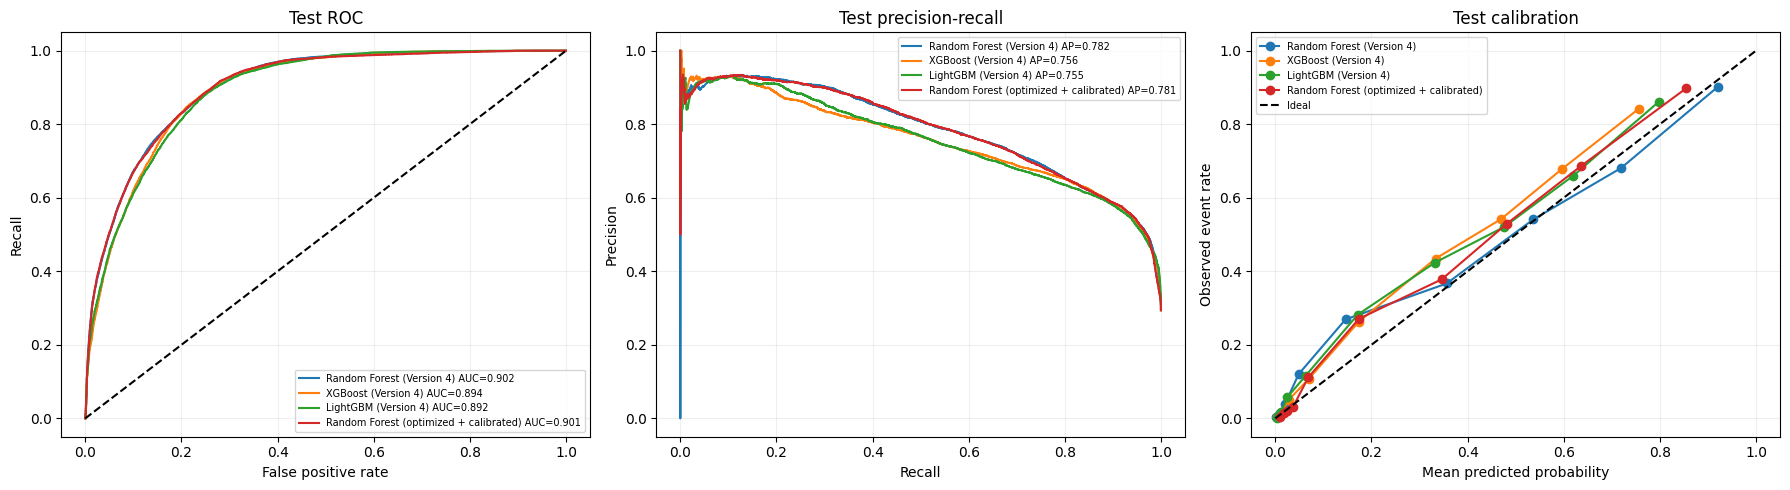

In [25]:
# Final evaluation after the model, calibration, and threshold were fixed on validation data.
import os, joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, precision_recall_curve)
from sklearn.calibration import calibration_curve
rfopt_loaded = joblib.load(rfopt_model_path)
assert rfopt_loaded["feature_columns"] == rfopt_feature_cols
assert rfopt_loaded["operating_threshold"] == rfopt_operating_threshold
rfopt_test_X = xtest.loc[:, rfopt_loaded["feature_columns"]]
rfopt_test_y = ytest.astype("int8")
assert rfopt_test_X.index.min() >= pd.Timestamp("2020-01-01", tz="UTC")
assert len(rfopt_test_X) == len(rfopt_test_y) == 43848
rfopt_test_raw = rfopt_loaded["model"].predict_proba(rfopt_test_X)[:, 1]
rfopt_test_probability = rfopt_loaded["probability_calibrator"].predict_proba(rfopt_logit(rfopt_test_raw))[:, 1]
assert np.isfinite(rfopt_test_probability).all()
def rfopt_test_metrics(y_true, probability, threshold):
    y_true=np.asarray(y_true,dtype="int8"); probability=np.asarray(probability,dtype=float)
    pred=(probability>=threshold).astype("int8"); tn,fp,fn,tp=confusion_matrix(y_true,pred,labels=[0,1]).ravel()
    spec=tn/(tn+fp) if tn+fp else 0.0; rec=recall_score(y_true,pred,zero_division=0)
    return {"Threshold":float(threshold),"Accuracy":accuracy_score(y_true,pred),"Precision":precision_score(y_true,pred,zero_division=0),"Recall":rec,"F1":f1_score(y_true,pred,zero_division=0),"TSS":rec+spec-1,"FPR":1-spec,"ROC_AUC":roc_auc_score(y_true,probability),"PR_AUC":average_precision_score(y_true,probability),"Brier":brier_score_loss(y_true,probability),"False_alarms_FP":int(fp),"TN":int(tn),"FP":int(fp),"FN":int(fn),"TP":int(tp)}
rfopt_compare_probs={}
for _name in ["Random Forest","XGBoost","LightGBM"]:
    _prob=np.asarray(baseline_test_probs[_name],dtype=float); assert len(_prob)==len(rfopt_test_y)
    rfopt_compare_probs[_name+" (Version 4)"]=_prob
rfopt_compare_probs["Random Forest (optimized + calibrated)"]=rfopt_test_probability
rfopt_test_rows=[]; rfopt_test_classifications={}
for _name,_prob in rfopt_compare_probs.items():
    _t=rfopt_operating_threshold if _name=="Random Forest (optimized + calibrated)" else 0.50
    rfopt_test_rows.append({"Model":_name,**rfopt_test_metrics(rfopt_test_y,_prob,_t)})
    rfopt_test_classifications[_name]=(_prob>=_t).astype("int8")
rfopt_test_rows.append({"Model":"Random Forest optimized (0.50)",**rfopt_test_metrics(rfopt_test_y,rfopt_test_probability,0.50)})
rfopt_test_classifications["Random Forest optimized (0.50)"]=(rfopt_test_probability>=0.50).astype("int8")
rfopt_test_results=pd.DataFrame(rfopt_test_rows).set_index("Model")
print("FINAL TEST COMPARISON — 2020-2024 only; model/calibrator/threshold finalized before test access")
print("Rows:",len(rfopt_test_y),"positives:",int(rfopt_test_y.sum()),"rate:",round(float(rfopt_test_y.mean()),4))
print(rfopt_test_results.round(4).to_string())
rfopt_test_metrics_path="/kaggle/working/solaris_ai_rf_optimized_test_metrics.csv"; rfopt_test_results.to_csv(rfopt_test_metrics_path)
fig,axs=plt.subplots(1,3,figsize=(18,5))
for _name,_prob in rfopt_compare_probs.items():
    _fpr,_tpr,_=roc_curve(rfopt_test_y,_prob); _pr,_rc,_=precision_recall_curve(rfopt_test_y,_prob); _frac,_mean=calibration_curve(rfopt_test_y,_prob,n_bins=10,strategy="quantile")
    axs[0].plot(_fpr,_tpr,label=f"{_name} AUC={roc_auc_score(rfopt_test_y,_prob):.3f}")
    axs[1].plot(_rc,_pr,label=f"{_name} AP={average_precision_score(rfopt_test_y,_prob):.3f}")
    axs[2].plot(_mean,_frac,marker="o",label=_name)
axs[0].plot([0,1],[0,1],"k--"); axs[0].set(title="Test ROC",xlabel="False positive rate",ylabel="Recall")
axs[1].set(title="Test precision-recall",xlabel="Recall",ylabel="Precision")
axs[2].plot([0,1],[0,1],"k--",label="Ideal"); axs[2].set(title="Test calibration",xlabel="Mean predicted probability",ylabel="Observed event rate")
for _ax in axs: _ax.legend(fontsize=7); _ax.grid(alpha=.2)
fig.tight_layout(); rfopt_performance_plot="/kaggle/working/solaris_ai_rf_optimized_test_performance.png"; fig.savefig(rfopt_performance_plot,dpi=160,bbox_inches="tight"); plt.show()

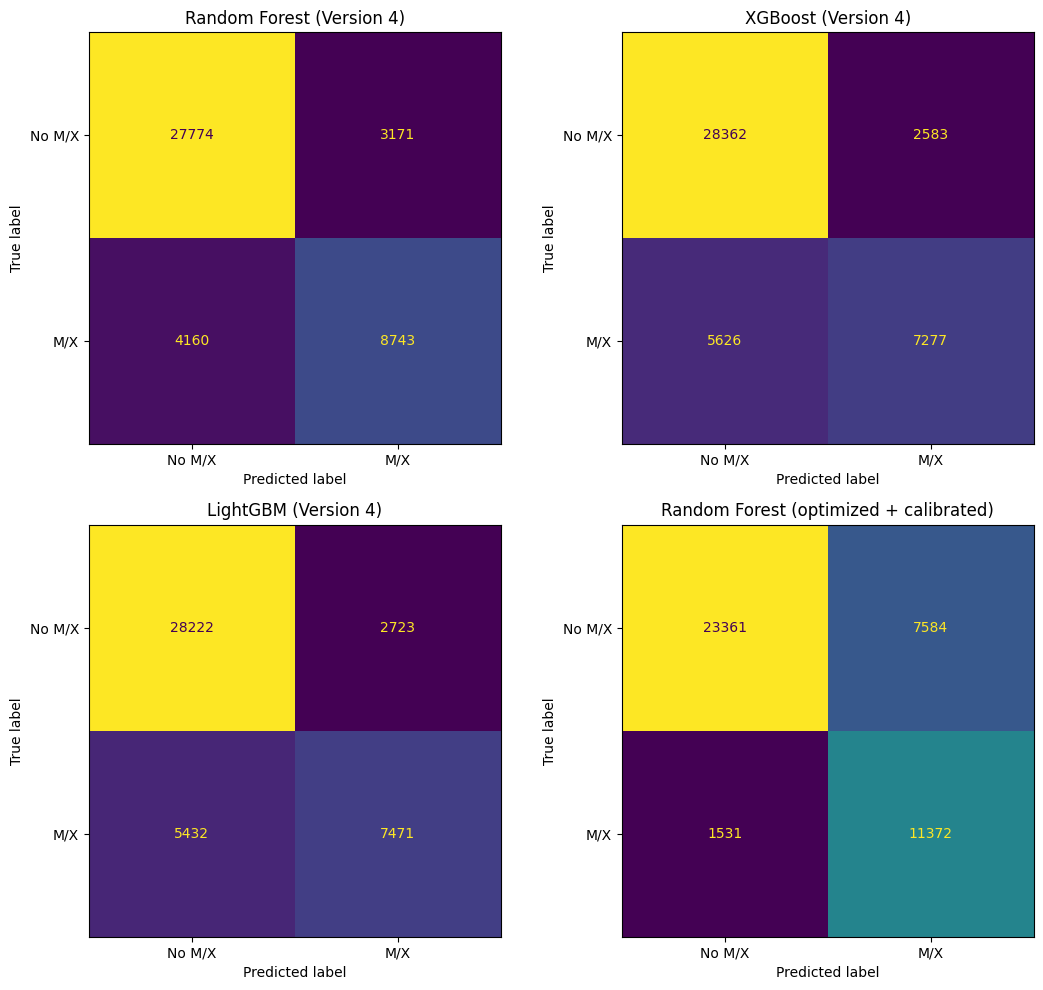

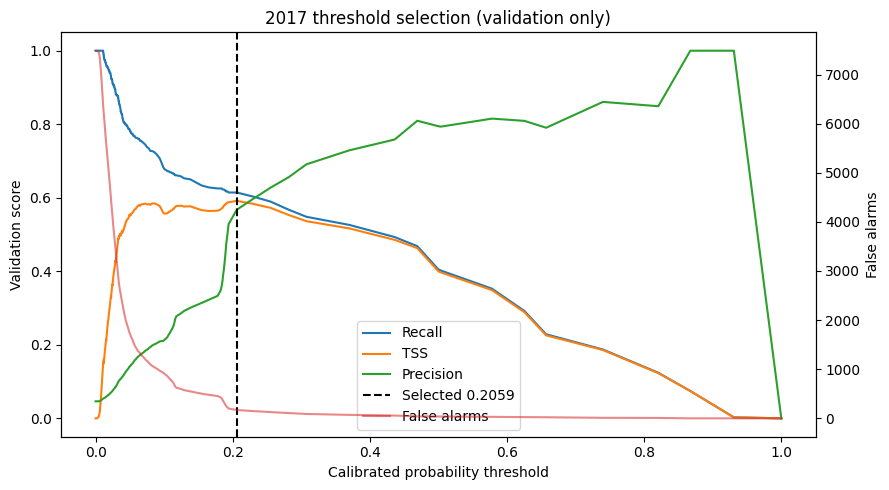

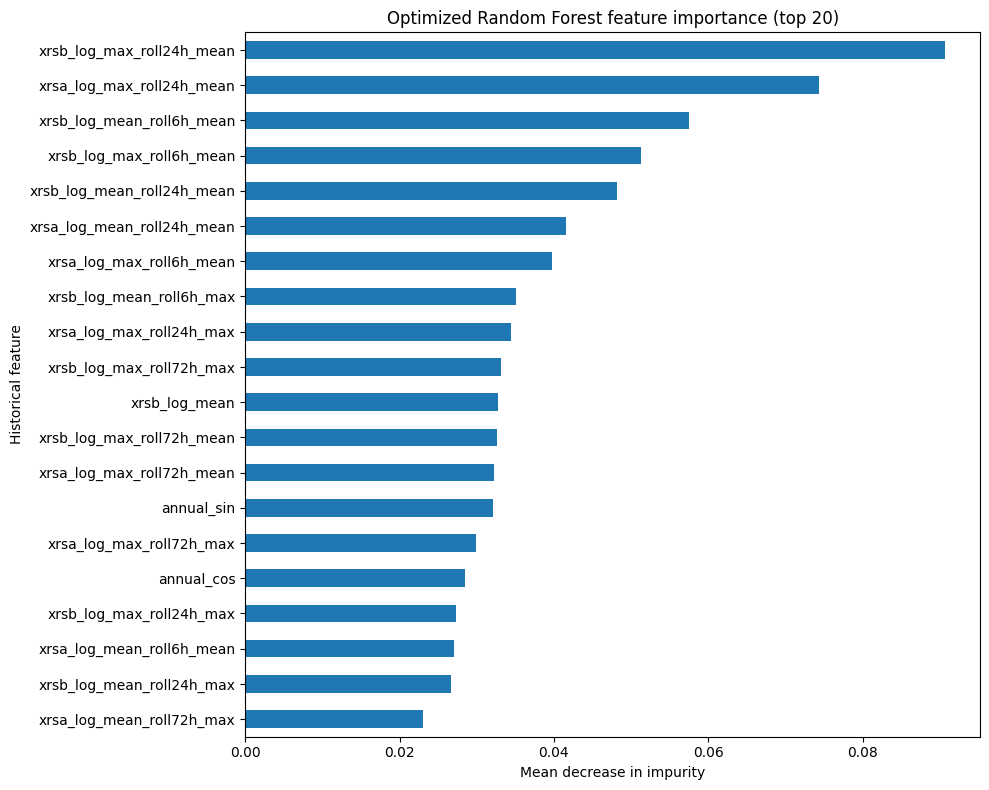

Verified bundle: /kaggle/working/solaris_ai_random_forest_optimized.joblib bytes= 11942212
Metrics CSV: /kaggle/working/solaris_ai_rf_optimized_test_metrics.csv
Plots: /kaggle/working/solaris_ai_rf_optimized_test_performance.png /kaggle/working/solaris_ai_rf_optimized_test_confusion.png /kaggle/working/solaris_ai_rf_optimized_validation_threshold.png /kaggle/working/solaris_ai_rf_optimized_feature_importance.png
Top feature importances:
 xrsb_log_max_roll24h_mean     0.09069
xrsa_log_max_roll24h_mean     0.07435
xrsb_log_mean_roll6h_mean     0.05754
xrsb_log_max_roll6h_mean      0.05125
xrsb_log_mean_roll24h_mean    0.04812
xrsa_log_mean_roll24h_mean    0.04158
xrsa_log_max_roll6h_mean      0.03980
xrsb_log_mean_roll6h_max      0.03514
xrsa_log_max_roll24h_max      0.03438
xrsb_log_max_roll72h_max      0.03308


In [26]:
# Confusion matrices, validation threshold tradeoff, and feature importance.
import joblib, os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
rfopt_cm_names=["Random Forest (Version 4)","XGBoost (Version 4)","LightGBM (Version 4)","Random Forest (optimized + calibrated)"]
fig,axs=plt.subplots(2,2,figsize=(11,10))
for _ax,_name in zip(axs.flat,rfopt_cm_names):
    ConfusionMatrixDisplay(confusion_matrix(rfopt_test_y,rfopt_test_classifications[_name],labels=[0,1]),display_labels=["No M/X","M/X"]).plot(ax=_ax,colorbar=False,values_format="d")
    _ax.set_title(_name)
fig.tight_layout(); rfopt_confusion_plot="/kaggle/working/solaris_ai_rf_optimized_test_confusion.png"; fig.savefig(rfopt_confusion_plot,dpi=160,bbox_inches="tight"); plt.show()
rfopt_thr_plot_data=rfopt_threshold_table.sort_values("threshold")
fig,ax1=plt.subplots(figsize=(9,5))
for _m in ["Recall","TSS","Precision"]: ax1.plot(rfopt_thr_plot_data.threshold,rfopt_thr_plot_data[_m],label=_m)
ax1.axvline(rfopt_operating_threshold,color="black",linestyle="--",label=f"Selected {rfopt_operating_threshold:.4f}")
ax1.set(xlabel="Calibrated probability threshold",ylabel="Validation score",title="2017 threshold selection (validation only)")
ax2=ax1.twinx(); ax2.plot(rfopt_thr_plot_data.threshold,rfopt_thr_plot_data.False_alarms,color="tab:red",alpha=.55,label="False alarms"); ax2.set_ylabel("False alarms")
a,b=ax1.get_legend_handles_labels(); c,d=ax2.get_legend_handles_labels(); ax1.legend(a+c,b+d,loc="best")
fig.tight_layout(); rfopt_threshold_plot="/kaggle/working/solaris_ai_rf_optimized_validation_threshold.png"; fig.savefig(rfopt_threshold_plot,dpi=160,bbox_inches="tight"); plt.show()
rfopt_rf=rfopt_loaded["model"].named_steps["model"]
rfopt_names=rfopt_loaded["model"].named_steps["imputer"].get_feature_names_out(rfopt_loaded["feature_columns"])
assert len(rfopt_names)==len(rfopt_rf.feature_importances_)
rfopt_importance=pd.Series(rfopt_rf.feature_importances_,index=rfopt_names).sort_values(ascending=False)
fig,ax=plt.subplots(figsize=(10,8)); rfopt_importance.head(20).sort_values().plot(kind="barh",ax=ax,color="tab:blue")
ax.set(title="Optimized Random Forest feature importance (top 20)",xlabel="Mean decrease in impurity",ylabel="Historical feature")
fig.tight_layout(); rfopt_importance_plot="/kaggle/working/solaris_ai_rf_optimized_feature_importance.png"; fig.savefig(rfopt_importance_plot,dpi=160,bbox_inches="tight"); plt.show()
rfopt_reload=joblib.load(rfopt_model_path)
assert rfopt_reload["model"].named_steps["imputer"] is not None and rfopt_reload["probability_calibrator"] is not None
assert rfopt_reload["feature_columns"]==rfopt_feature_cols and rfopt_reload["operating_threshold"]==rfopt_operating_threshold
print("Verified bundle:",rfopt_model_path,"bytes=",os.path.getsize(rfopt_model_path))
print("Metrics CSV:",rfopt_test_metrics_path)
print("Plots:",rfopt_performance_plot,rfopt_confusion_plot,rfopt_threshold_plot,rfopt_importance_plot)
print("Top feature importances:\n",rfopt_importance.head(10).round(5).to_string())

In [27]:
# Phase 2.1 — annual and solar-cycle-period-proxy reliability; test metrics are descriptive only.
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
rfopt_phase2_threshold = float(rfopt_operating_threshold)
def rfopt_phase2_episode_count(mask, idx, max_gap_hours=24):
    times = pd.DatetimeIndex(idx[np.asarray(mask, dtype=bool)]).sort_values()
    if len(times) == 0: return 0
    return int(1 + np.sum(np.diff(times.asi8) > pd.Timedelta(hours=max_gap_hours).value))
def rfopt_phase2_row(y_true, prob, idx, threshold, segment):
    m = rfopt_test_metrics(y_true, prob, threshold)
    pred = np.asarray(prob) >= threshold
    yv = np.asarray(y_true, dtype=int)
    tn, fp, fn, tp = confusion_matrix(yv, pred.astype(int), labels=[0,1]).ravel()
    false_mask = pred & (yv == 0)
    return {"Period": segment, "Rows": len(yv), "Prevalence": float(yv.mean()), **m,
            "False_alarm_hours_FP": int(fp), "Missed_positive_forecast_hours_FN": int(fn),
            "Alert_episodes_gap_le_24h": rfopt_phase2_episode_count(pred, idx),
            "False_alarm_episodes_gap_le_24h": rfopt_phase2_episode_count(false_mask, idx)}
rfopt_phase2_year_rows=[]; rfopt_phase2_phase_rows=[]; rfopt_phase2_cms={}
for yr in range(2020, 2025):
    mask = np.asarray(rfopt_test_y.index.year == yr)
    yy = rfopt_test_y.iloc[np.flatnonzero(mask)]; pp = rfopt_test_probability[mask]
    ix = yy.index; row = rfopt_phase2_row(yy, pp, ix, rfopt_phase2_threshold, str(yr))
    rfopt_phase2_year_rows.append(row)
    rfopt_phase2_cms[str(yr)] = confusion_matrix(yy, (pp >= rfopt_phase2_threshold).astype(int), labels=[0,1])
for name, years in [("early-rise period proxy (2020-2021)",[2020,2021]), ("ascending-period proxy (2022-2023)",[2022,2023]), ("high-activity period proxy (2024)",[2024])]:
    mask = rfopt_test_y.index.year.isin(years)
    yy = rfopt_test_y.loc[mask]; pp = rfopt_test_probability[np.asarray(mask)]
    rfopt_phase2_phase_rows.append(rfopt_phase2_row(yy, pp, yy.index, rfopt_phase2_threshold, name))
    rfopt_phase2_cms[name] = confusion_matrix(yy, (pp >= rfopt_phase2_threshold).astype(int), labels=[0,1])
rfopt_phase2_year_metrics = pd.DataFrame(rfopt_phase2_year_rows).set_index("Period")
rfopt_phase2_phase_metrics = pd.DataFrame(rfopt_phase2_phase_rows).set_index("Period")
print("Frozen validation threshold:", round(rfopt_phase2_threshold,6), "(selected on 2017 only)")
print("Annual 2020-2024 metrics; FP/FN are hourly forecast windows, not distinct flare events:")
print(rfopt_phase2_year_metrics[["Rows","Prevalence","Accuracy","Precision","Recall","F1","TSS","ROC_AUC","PR_AUC","Brier","False_alarm_hours_FP","Missed_positive_forecast_hours_FN","Alert_episodes_gap_le_24h","False_alarm_episodes_gap_le_24h"]].round(4).to_string())
print("Grouped calendar proxies for Solar Cycle 25 activity phases (descriptive; no independent phase labels in dataset):")
print(rfopt_phase2_phase_metrics[["Rows","Prevalence","Accuracy","Precision","Recall","F1","TSS","ROC_AUC","PR_AUC","Brier","False_alarm_hours_FP","Missed_positive_forecast_hours_FN","Alert_episodes_gap_le_24h","False_alarm_episodes_gap_le_24h"]].round(4).to_string())
print("Confusion matrix labels order: rows=true [no flare, M/X], columns=predicted [no alert, alert].")
for key, cm in rfopt_phase2_cms.items(): print(key, cm.tolist())
rfopt_phase2_year_metrics.to_csv('/kaggle/working/solaris_ai_phase2_annual_metrics_descriptive_test.csv')
rfopt_phase2_phase_metrics.to_csv('/kaggle/working/solaris_ai_phase2_cycle_period_metrics_descriptive_test.csv')
rfopt_phase2_existing_comparison = rfopt_test_results.copy()
rfopt_phase2_existing_comparison.to_csv('/kaggle/working/solaris_ai_phase2_model_comparison_descriptive_test.csv')

Frozen validation threshold: 0.205944 (selected on 2017 only)
Annual 2020-2024 metrics; FP/FN are hourly forecast windows, not distinct flare events:
        Rows  Prevalence  Accuracy  Precision  Recall      F1     TSS  ROC_AUC  PR_AUC   Brier  False_alarm_hours_FP  Missed_positive_forecast_hours_FN  Alert_episodes_gap_le_24h  False_alarm_episodes_gap_le_24h
Period                                                                                                                                                                                                             
2020    8784      0.0055    0.9945     0.0000  0.0000  0.0000  0.0000   0.7252  0.0199  0.0057                     0                                 48                          0                                0
2021    8760      0.0613    0.9309     0.3867  0.2160  0.2772  0.1936   0.8047  0.2973  0.0510                   184                                421                         10                               11
20

In [29]:
# Phase 2.2 — feature timing/leakage audit and event-timestamp availability.
import re, pandas as pd, numpy as np
rfopt_phase2_forbidden = ("label","target","class","flare","event","cumulative","timestamp","future","lead","next","post")
rfopt_phase2_bad = [c for c in rfopt_feature_cols if any(x in str(c).lower() for x in rfopt_phase2_forbidden)]
rfopt_phase2_allowed = [c for c in rfopt_feature_cols if str(c).startswith(("xrsa_","xrsb_")) or str(c) in {"hour_sin","hour_cos","year_sin","year_cos","annual_sin","annual_cos"}]
assert len(rfopt_feature_cols) == 38 and len(set(rfopt_feature_cols)) == 38
assert not rfopt_phase2_bad, rfopt_phase2_bad
assert len(rfopt_phase2_allowed) == len(rfopt_feature_cols), [c for c in rfopt_feature_cols if c not in rfopt_phase2_allowed]
assert rfopt_feature_cols == rfopt_loaded["feature_columns"]
assert all(pd.api.types.is_numeric_dtype(goesh[c]) for c in rfopt_feature_cols)
print("Leakage audit passed: exactly 38 ordered numeric features; only GOES XRS measurement aggregates/coverage and calendar sin/cos.")
print("Timing basis from the existing feature builder and Version 4 notes: science-quality GOES data, completed prior-hour bins, and trailing 6/24/72-hour summaries; no current/future target metadata.")
print("24-hour boundary purges used for the 2015 tuning, 2016 calibration and 2017 threshold periods; 2020-2024 never enters fitting/calibration/threshold selection.")
print("Ordered model input schema:", rfopt_feature_cols)
rfopt_phase2_label_source = pd.read_csv('/kaggle/working/surya_dataset/data.csv', nrows=5)
rfopt_phase2_label_columns = list(rfopt_phase2_label_source.columns)
rfopt_phase2_event_fields = [c for c in rfopt_phase2_label_columns if re.search(r"event.*(start|time|onset)|flare.*(start|time|onset)|onset|peak_time", str(c), re.I)]
print("Label-table fields:", rfopt_phase2_label_columns)
print("Explicit flare onset/peak timestamp fields:", rfopt_phase2_event_fields)
print("Event limitation: the hourly timestamp indexes a forecast/label row; max_goes_class is outcome metadata, not a distinct event onset. No event-level lead-time or event-matched false-alert score will be claimed.")
print("Alarm-episode proxy limitation: grouping positive forecast windows separated by at most 24h is only a clustering proxy, not independent flare-event matching.")

Leakage audit passed: exactly 38 ordered numeric features; only GOES XRS measurement aggregates/coverage and calendar sin/cos.
Timing basis from the existing feature builder and Version 4 notes: science-quality GOES data, completed prior-hour bins, and trailing 6/24/72-hour summaries; no current/future target metadata.
24-hour boundary purges used for the 2015 tuning, 2016 calibration and 2017 threshold periods; 2020-2024 never enters fitting/calibration/threshold selection.
Ordered model input schema: ['xrsa_log_mean', 'xrsa_log_max', 'xrsa_log_std', 'xrsa_coverage', 'xrsb_log_mean', 'xrsb_log_max', 'xrsb_log_std', 'xrsb_coverage', 'xrsa_log_mean_roll6h_mean', 'xrsa_log_mean_roll6h_max', 'xrsa_log_max_roll6h_mean', 'xrsa_log_max_roll6h_max', 'xrsb_log_mean_roll6h_mean', 'xrsb_log_mean_roll6h_max', 'xrsb_log_max_roll6h_mean', 'xrsb_log_max_roll6h_max', 'xrsa_log_mean_roll24h_mean', 'xrsa_log_mean_roll24h_max', 'xrsa_log_max_roll24h_mean', 'xrsa_log_max_roll24h_max', 'xrsb_log_mean_roll

Calibration metrics (lower Brier/log-loss/ECE is better; 2016 fitted-period scores are optimistic):
                                 Period              Probability_set  Rows  Observed_rate  Mean_probability  Brier  Log_loss  ECE_quantile_10
2016 calibration-fit period (in-sample)                          raw  8760         0.0316            0.1025 0.0367    0.1509           0.0709
2016 calibration-fit period (in-sample) 2016-calibrated (fit period)  8760         0.0316            0.0316 0.0281    0.1079           0.0072
     2017 independent calibration check                          raw  7848         0.0463            0.1731 0.0507    0.2139           0.1269
     2017 independent calibration check              2016-calibrated  7848         0.0463            0.0646 0.0284    0.1225           0.0184
           2020 test (descriptive only)       frozen 2016 calibrator  8784         0.0055            0.0192 0.0057    0.0390           0.0137
           2021 test (descriptive only)       fr

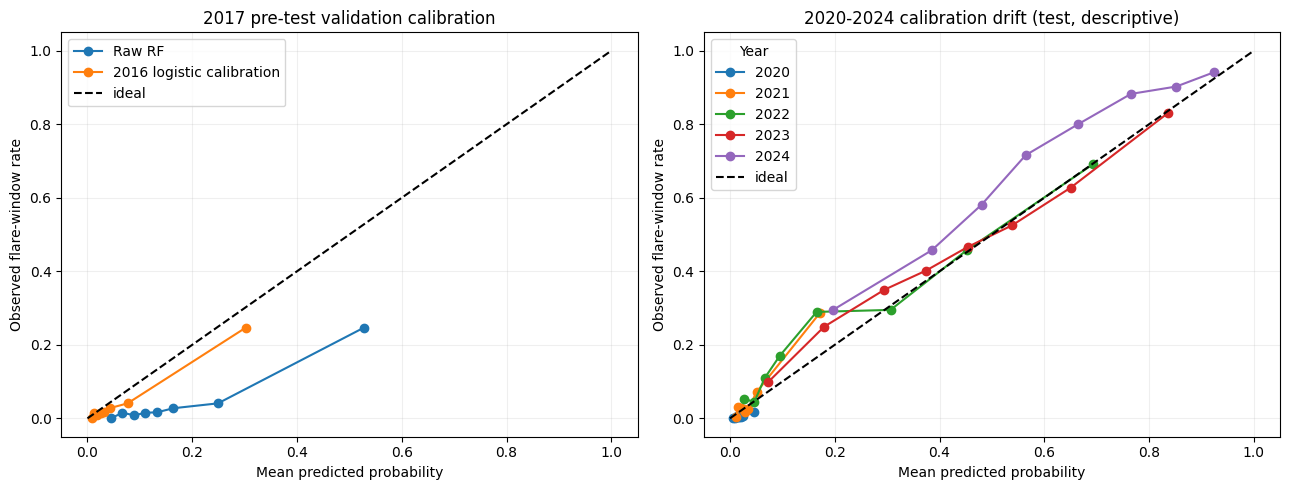

Calibration plot: /kaggle/working/solaris_ai_phase2_calibration_validation_and_drift.png
Decision: retain the existing 2016 logistic calibrator; assess 2017 independently and do not fit/recalibrate on 2020-2024 test labels.


In [30]:
# Phase 2.3 — calibration checks; fit calibration only on 2016, validation on 2017, later years descriptive.
from sklearn.metrics import brier_score_loss, log_loss
from sklearn.calibration import calibration_curve

def rfopt_phase2_ece(yv, pv, bins=10):
    yv=np.asarray(yv,dtype=float); pv=np.asarray(pv,dtype=float)
    order=np.argsort(pv); chunks=np.array_split(order, min(bins,len(order)))
    return float(sum(len(ix)/len(order)*abs(yv[ix].mean()-pv[ix].mean()) for ix in chunks if len(ix)))
def rfopt_phase2_calrow(period, yv, pv, label):
    yv=np.asarray(yv,dtype=int); pv=np.asarray(pv,dtype=float)
    return {"Period":period,"Probability_set":label,"Rows":len(yv),"Observed_rate":float(yv.mean()),"Mean_probability":float(pv.mean()),"Brier":brier_score_loss(yv,pv),"Log_loss":log_loss(yv,pv,labels=[0,1]),"ECE_quantile_10":rfopt_phase2_ece(yv,pv)}
rfopt_phase2_cal_rows=[]
for label,pv in [("raw",rfopt_p_cal_raw),("2016-calibrated (fit period)",rfopt_p_cal)]:
    rfopt_phase2_cal_rows.append(rfopt_phase2_calrow("2016 calibration-fit period (in-sample)",rfopt_y_cal,pv,label))
for label,pv in [("raw",rfopt_p_thr_raw),("2016-calibrated",rfopt_p_thr)]:
    rfopt_phase2_cal_rows.append(rfopt_phase2_calrow("2017 independent calibration check",rfopt_y_thr,pv,label))
for yr in range(2020,2025):
    mask=np.asarray(rfopt_test_y.index.year==yr); yy=rfopt_test_y.iloc[np.flatnonzero(mask)]; pp=rfopt_test_probability[mask]
    rfopt_phase2_cal_rows.append(rfopt_phase2_calrow(str(yr)+" test (descriptive only)",yy,pp,"frozen 2016 calibrator"))
rfopt_phase2_calibration_metrics=pd.DataFrame(rfopt_phase2_cal_rows)
print("Calibration metrics (lower Brier/log-loss/ECE is better; 2016 fitted-period scores are optimistic):")
print(rfopt_phase2_calibration_metrics.round(4).to_string(index=False))
fig,axs=plt.subplots(1,2,figsize=(13,5))
for label,pv in [("Raw RF",rfopt_p_thr_raw),("2016 logistic calibration",rfopt_p_thr)]:
    obs,mean=calibration_curve(rfopt_y_thr,pv,n_bins=8,strategy="quantile")
    axs[0].plot(mean,obs,marker="o",label=label)
axs[0].plot([0,1],[0,1],"k--",label="ideal"); axs[0].set(title="2017 pre-test validation calibration",xlabel="Mean predicted probability",ylabel="Observed flare-window rate"); axs[0].legend(); axs[0].grid(alpha=.2)
for yr in range(2020,2025):
    mask=np.asarray(rfopt_test_y.index.year==yr); yy=rfopt_test_y.iloc[np.flatnonzero(mask)]; pp=rfopt_test_probability[mask]
    obs,mean=calibration_curve(yy,pp,n_bins=8,strategy="quantile")
    axs[1].plot(mean,obs,marker="o",label=str(yr))
axs[1].plot([0,1],[0,1],"k--",label="ideal"); axs[1].set(title="2020-2024 calibration drift (test, descriptive)",xlabel="Mean predicted probability",ylabel="Observed flare-window rate"); axs[1].legend(title="Year"); axs[1].grid(alpha=.2)
fig.tight_layout(); rfopt_phase2_calibration_plot='/kaggle/working/solaris_ai_phase2_calibration_validation_and_drift.png'; fig.savefig(rfopt_phase2_calibration_plot,dpi=160,bbox_inches="tight"); plt.show()
rfopt_phase2_calibration_metrics.to_csv('/kaggle/working/solaris_ai_phase2_calibration_metrics.csv',index=False)
print("Calibration plot:",rfopt_phase2_calibration_plot)
print("Decision: retain the existing 2016 logistic calibrator; assess 2017 independently and do not fit/recalibrate on 2020-2024 test labels.")

2017 validation threshold trade-offs only (no test rows used):
 Threshold  Accuracy  Precision  Recall     F1    TSS    FPR  False_alarms_FP   TN   FP  FN  TP
    0.0276    0.5271     0.0817  0.9008 0.1498 0.4098 0.4910             3675 3810 3675  36 327
    0.0500    0.7698     0.1412  0.7824 0.2392 0.5515 0.2309             1728 5757 1728  79 284
    0.1000    0.8688     0.2123  0.6777 0.3233 0.5557 0.1220              913 6572  913 117 246
    0.2059    0.9605     0.5674  0.6143 0.5899 0.5916 0.0227              170 7315  170 140 223
    0.3000    0.9671     0.6792  0.5482 0.6067 0.5357 0.0126               94 7391   94 164 199
    0.3700    0.9690     0.7290  0.5262 0.6112 0.5167 0.0095               71 7414   71 172 191
    0.5000    0.9676     0.7946  0.4050 0.5365 0.3999 0.0051               38 7447   38 216 147
Frozen default warning threshold from validation: 0.205944
Risk cutoffs: Low/Moderate boundary 0.027568 (max cutoff with recall >= 0.90); Moderate/High boundary 0.369991

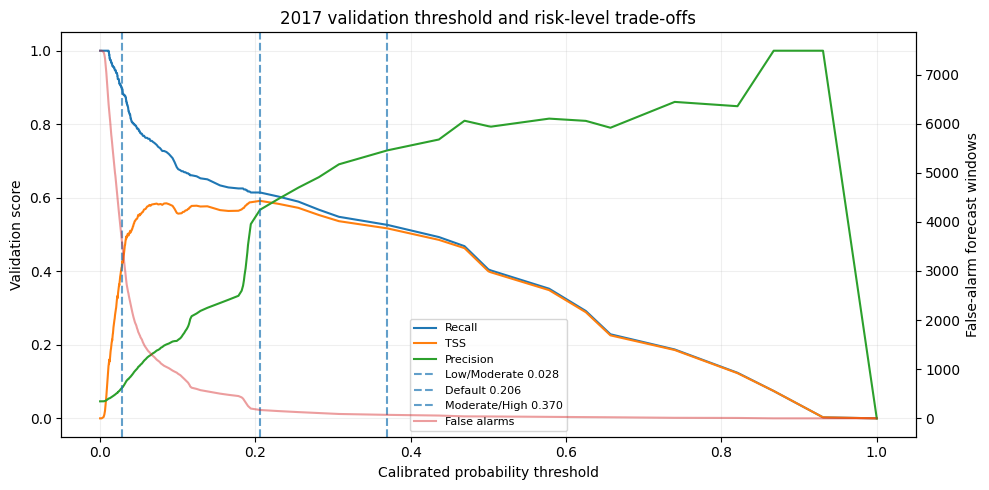

Threshold graph: /kaggle/working/solaris_ai_phase2_validation_risk_thresholds.png


In [31]:
# Phase 2.4 — freeze operating/risk thresholds using 2017 validation only.
rfopt_phase2_recall_low_target=0.90; rfopt_phase2_recall_high_target=0.50
rfopt_phase2_t_low=float(rfopt_threshold_table.loc[rfopt_threshold_table.Recall>=rfopt_phase2_recall_low_target,"threshold"].max())
rfopt_phase2_t_high=float(rfopt_threshold_table.loc[rfopt_threshold_table.Recall>=rfopt_phase2_recall_high_target,"threshold"].max())
assert 0 <= rfopt_phase2_t_low < rfopt_phase2_t_high <= 1
rfopt_phase2_risk_levels={"Low":{"range":f"p < {rfopt_phase2_t_low:.8f}","meaning":"below the 2017 threshold maintaining at least 90% recall"},"Moderate":{"range":f"{rfopt_phase2_t_low:.8f} <= p < {rfopt_phase2_t_high:.8f}","meaning":"intermediate validation risk"},"High":{"range":f"p >= {rfopt_phase2_t_high:.8f}","meaning":"at least 50% validation recall at the upper cutoff"}}
rfopt_phase2_compare_thresholds=sorted(set([0.05,0.10,rfopt_operating_threshold,0.30,0.50,rfopt_phase2_t_low,rfopt_phase2_t_high]))
rfopt_phase2_threshold_rows=[]
for t in rfopt_phase2_compare_thresholds:
    row=rfopt_test_metrics(rfopt_y_thr,rfopt_p_thr,t); row["Validation_period"]="2017"; rfopt_phase2_threshold_rows.append(row)
rfopt_phase2_threshold_comparison=pd.DataFrame(rfopt_phase2_threshold_rows).sort_values("Threshold")
print("2017 validation threshold trade-offs only (no test rows used):")
print(rfopt_phase2_threshold_comparison[["Threshold","Accuracy","Precision","Recall","F1","TSS","FPR","False_alarms_FP","TN","FP","FN","TP"]].round(4).to_string(index=False))
print("Frozen default warning threshold from validation:",round(rfopt_operating_threshold,6))
print("Risk cutoffs: Low/Moderate boundary",round(rfopt_phase2_t_low,6),"(max cutoff with recall >= 0.90); Moderate/High boundary",round(rfopt_phase2_t_high,6),"(max cutoff with recall >= 0.50).")
rfopt_phase2_val_bands=pd.cut(rfopt_p_thr,bins=[-np.inf,rfopt_phase2_t_low,rfopt_phase2_t_high,np.inf],labels=["Low","Moderate","High"],right=False)
rfopt_phase2_band_rows=[]
for band in ["Low","Moderate","High"]:
    m=np.asarray(rfopt_phase2_val_bands==band); yy=np.asarray(rfopt_y_thr)[m]
    rfopt_phase2_band_rows.append({"Risk_level":band,"Rows":int(m.sum()),"Positive_windows":int(yy.sum()),"Observed_rate":float(yy.mean()) if len(yy) else np.nan})
rfopt_phase2_validation_bands=pd.DataFrame(rfopt_phase2_band_rows)
print("Validation-only observed rates by band:"); print(rfopt_phase2_validation_bands.round(4).to_string(index=False))
rfopt_phase2_threshold_comparison.to_csv('/kaggle/working/solaris_ai_phase2_threshold_comparison_validation.csv',index=False)
rfopt_phase2_validation_bands.to_csv('/kaggle/working/solaris_ai_phase2_risk_levels_validation.csv',index=False)
fig,ax1=plt.subplots(figsize=(10,5)); q=rfopt_threshold_table.sort_values("threshold")
for col in ["Recall","TSS","Precision"]: ax1.plot(q.threshold,q[col],label=col)
for t,label in [(rfopt_phase2_t_low,"Low/Moderate"),(rfopt_operating_threshold,"Default"),(rfopt_phase2_t_high,"Moderate/High")]: ax1.axvline(t,linestyle="--",alpha=.7,label=f"{label} {t:.3f}")
ax1.set(xlabel="Calibrated probability threshold",ylabel="Validation score",title="2017 validation threshold and risk-level trade-offs"); ax2=ax1.twinx(); ax2.plot(q.threshold,q.False_alarms,color="tab:red",alpha=.45,label="False alarms"); ax2.set_ylabel("False-alarm forecast windows"); a,b=ax1.get_legend_handles_labels(); c,d=ax2.get_legend_handles_labels(); ax1.legend(a+c,b+d,fontsize=8); ax1.grid(alpha=.2); fig.tight_layout(); rfopt_phase2_threshold_plot='/kaggle/working/solaris_ai_phase2_validation_risk_thresholds.png'; fig.savefig(rfopt_phase2_threshold_plot,dpi=160,bbox_inches="tight"); plt.show()
print("Threshold graph:",rfopt_phase2_threshold_plot)

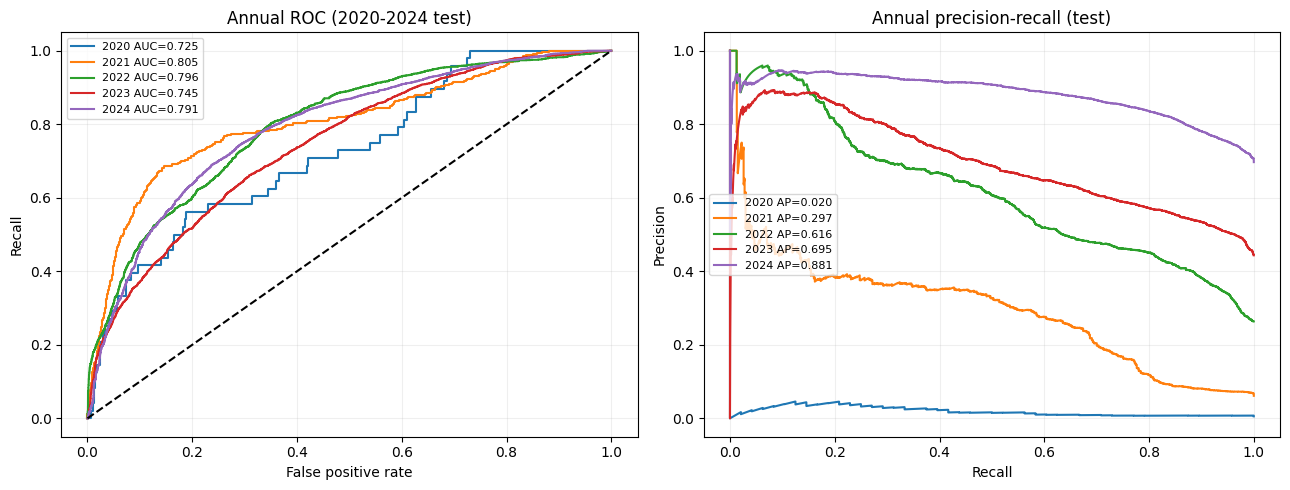

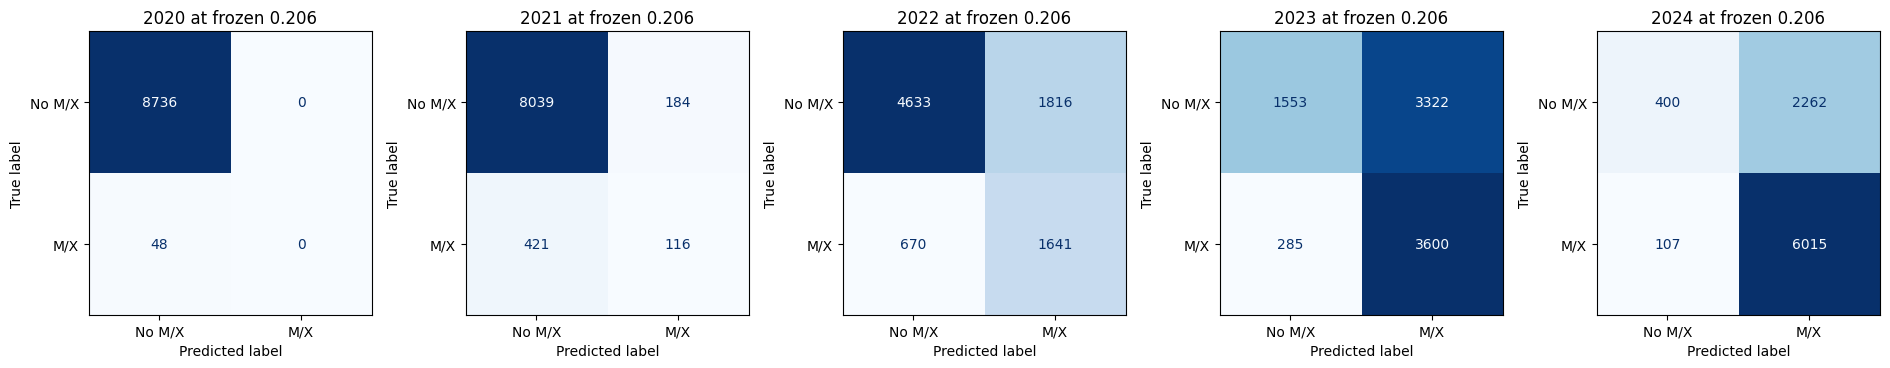

Saved annual ROC/PR: /kaggle/working/solaris_ai_phase2_annual_test_roc_pr.png
Saved annual confusion matrices: /kaggle/working/solaris_ai_phase2_annual_test_confusion.png
Confusion matrix counts:
                             Period    TN   FP  FN   TP
                               2020  8736    0  48    0
                               2021  8039  184 421  116
                               2022  4633 1816 670 1641
                               2023  1553 3322 285 3600
                               2024   400 2262 107 6015
early-rise period proxy (2020-2021) 16775  184 469  116
 ascending-period proxy (2022-2023)  6186 5138 955 5241
  high-activity period proxy (2024)   400 2262 107 6015
Threshold frozen from 2017 validation; plots summarize already-observed test outcomes only.


In [32]:
# Phase 2.5 — test-period annual ROC/PR and confusion-matrix figures (descriptive only).
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score, ConfusionMatrixDisplay, confusion_matrix
fig,axs=plt.subplots(1,2,figsize=(13,5))
for yr in range(2020,2025):
    m=np.asarray(rfopt_test_y.index.year==yr); yy=np.asarray(rfopt_test_y)[m]; pp=rfopt_test_probability[m]
    fpr,tpr,_=roc_curve(yy,pp); prec,rec,_=precision_recall_curve(yy,pp)
    axs[0].plot(fpr,tpr,label=f"{yr} AUC={roc_auc_score(yy,pp):.3f}")
    axs[1].plot(rec,prec,label=f"{yr} AP={average_precision_score(yy,pp):.3f}")
axs[0].plot([0,1],[0,1],"k--"); axs[0].set(title="Annual ROC (2020-2024 test)",xlabel="False positive rate",ylabel="Recall")
axs[1].set(title="Annual precision-recall (test)",xlabel="Recall",ylabel="Precision")
for ax in axs: ax.legend(fontsize=8); ax.grid(alpha=.2)
fig.tight_layout(); rfopt_phase2_annual_roc_pr_plot='/kaggle/working/solaris_ai_phase2_annual_test_roc_pr.png'; fig.savefig(rfopt_phase2_annual_roc_pr_plot,dpi=160,bbox_inches="tight"); plt.show()
fig,axs=plt.subplots(1,5,figsize=(19,4))
for ax,yr in zip(axs,range(2020,2025)):
    m=np.asarray(rfopt_test_y.index.year==yr); yy=np.asarray(rfopt_test_y)[m]; pp=rfopt_test_probability[m]
    cm=confusion_matrix(yy,(pp>=rfopt_phase2_threshold).astype(int),labels=[0,1])
    ConfusionMatrixDisplay(cm,display_labels=["No M/X","M/X"]).plot(ax=ax,colorbar=False,values_format="d",cmap="Blues")
    ax.set_title(f"{yr} at frozen {rfopt_phase2_threshold:.3f}")
fig.tight_layout(); rfopt_phase2_annual_cm_plot='/kaggle/working/solaris_ai_phase2_annual_test_confusion.png'; fig.savefig(rfopt_phase2_annual_cm_plot,dpi=160,bbox_inches="tight"); plt.show()
rfopt_phase2_cm_rows=[]
for key,cm in rfopt_phase2_cms.items():
    tn,fp,fn,tp=cm.ravel(); rfopt_phase2_cm_rows.append({"Period":key,"TN":int(tn),"FP":int(fp),"FN":int(fn),"TP":int(tp)})
rfopt_phase2_confusion_table=pd.DataFrame(rfopt_phase2_cm_rows)
rfopt_phase2_confusion_table.to_csv('/kaggle/working/solaris_ai_phase2_confusion_counts_descriptive_test.csv',index=False)
print("Saved annual ROC/PR:",rfopt_phase2_annual_roc_pr_plot)
print("Saved annual confusion matrices:",rfopt_phase2_annual_cm_plot)
print("Confusion matrix counts:"); print(rfopt_phase2_confusion_table.to_string(index=False))
print("Threshold frozen from 2017 validation; plots summarize already-observed test outcomes only.")

In [33]:
# Phase 2.6 — schema, deployment bundle, reload, and inference input checks (pre-test samples only).
import json, joblib, numpy as np, pandas as pd, os
rfopt_phase2_features=list(rfopt_feature_cols)
rfopt_phase2_schema_features=[]
for i,c in enumerate(rfopt_phase2_features):
    if "coverage" in c: unit="fraction [0,1]"
    elif c in {"hour_sin","hour_cos","annual_sin","annual_cos"}: unit="dimensionless sine/cosine"
    else: unit="statistics of log-scaled GOES XRS flux; underlying flux input W m^-2; reproduce V5 transform exactly"
    if "roll6h" in c: window="trailing 6 completed hours"
    elif "roll24h" in c: window="trailing 24 completed hours"
    elif "roll72h" in c: window="trailing 72 completed hours"
    elif c in {"hour_sin","hour_cos","annual_sin","annual_cos"}: window="forecast timestamp calendar encoding"
    else: window="completed prior-hour GOES bin"
    rfopt_phase2_schema_features.append({"index":i,"name":c,"dtype":"numeric","unit":unit,"window":window,"missing_values_allowed":True})
rfopt_phase2_schema={"schema_version":"1.0","feature_count":38,"feature_order":"exact list order","forecast_horizon":"24 hours","target":"M/X-class flare occurrence in the labeled 24-hour forecast window","features":rfopt_phase2_schema_features,"time_rule":"Only completed prior-hour science-quality GOES XRS observations and trailing history; time encodings use forecast timestamp.","important":"Apply the exact Version 5 NOAA quality filtering, UTC binning, log transform and feature construction. Do not pass labels, flare classes, cumulative metadata, or future observations."}
rfopt_phase2_pretest=pd.concat([rfopt_x_fit,rfopt_x_cal,rfopt_x_thr],axis=0).loc[:,rfopt_phase2_features].replace([np.inf,-np.inf],np.nan)
rfopt_phase2_bounds={"lower":rfopt_phase2_pretest.quantile(.001).to_dict(),"upper":rfopt_phase2_pretest.quantile(.999).to_dict()}
rfopt_phase2_bundle=dict(joblib.load(rfopt_model_path))
rfopt_phase2_bundle.update({"phase":"Phase 2 deployment readiness","feature_schema":rfopt_phase2_schema,"risk_levels":rfopt_phase2_risk_levels,"risk_cutoffs":{"low_moderate":rfopt_phase2_t_low,"moderate_high":rfopt_phase2_t_high},"feature_value_monitoring_bounds_0_1pct":rfopt_phase2_bounds,"test_data_used_for_threshold_or_calibration":False})
rfopt_phase2_model_path='/kaggle/working/solaris_ai_random_forest_phase2.joblib'
joblib.dump(rfopt_phase2_bundle,rfopt_phase2_model_path,compress=3)
rfopt_phase2_schema_path='/kaggle/working/solaris_ai_feature_schema.json'
with open(rfopt_phase2_schema_path,'w') as f: json.dump(rfopt_phase2_schema,f,indent=2)
rfopt_phase2_loaded=joblib.load(rfopt_phase2_model_path)
assert rfopt_phase2_loaded["feature_columns"]==rfopt_phase2_features and len(rfopt_phase2_loaded["feature_columns"])==38

def rfopt_phase2_predict(frame,bundle):
    expected=bundle["feature_columns"]
    if not isinstance(frame,pd.DataFrame): raise TypeError("Input must be a pandas DataFrame")
    if list(frame.columns)!=expected: raise ValueError("Input columns must match the exact 38-feature schema and order")
    if len(frame)==0: raise ValueError("Input batch must not be empty")
    bad=[c for c in expected if not pd.api.types.is_numeric_dtype(frame[c])]
    if bad: raise TypeError("Non-numeric feature columns: "+str(bad))
    vals=frame.to_numpy(dtype=float)
    if np.isinf(vals).any(): raise ValueError("Infinite values are invalid; use NaN for missing observations")
    raw=bundle["model"].predict_proba(frame)[:,1]
    z=np.log(np.clip(raw,1e-6,1-1e-6)/(1-np.clip(raw,1e-6,1-1e-6))).reshape(-1,1)
    prob=bundle["probability_calibrator"].predict_proba(z)[:,1]
    if (not np.isfinite(prob).all()) or (prob.min()<0) or (prob.max()>1): raise ValueError("Invalid calibrated probability")
    lo=pd.Series(bundle["feature_value_monitoring_bounds_0_1pct"]["lower"]).reindex(expected).to_numpy(float)
    hi=pd.Series(bundle["feature_value_monitoring_bounds_0_1pct"]["upper"]).reindex(expected).to_numpy(float)
    out=((vals<lo)|(vals>hi)) & np.isfinite(vals)
    cut=bundle["risk_cutoffs"]
    band=np.where(prob<cut["low_moderate"],"Low",np.where(prob<cut["moderate_high"],"Moderate","High"))
    return pd.DataFrame({"probability":prob,"forecast_alert":(prob>=bundle["operating_threshold"]).astype(int),"risk_level":band,"missing_feature_values":np.isnan(vals).sum(axis=1),"out_of_validation_range_features":out.sum(axis=1)},index=frame.index)
rfopt_phase2_sample=rfopt_x_thr.sample(n=min(32,len(rfopt_x_thr)),random_state=42).loc[:,rfopt_phase2_features]
rfopt_phase2_sample_output=rfopt_phase2_predict(rfopt_phase2_sample,rfopt_phase2_loaded)
assert len(rfopt_phase2_sample_output)==len(rfopt_phase2_sample) and rfopt_phase2_sample_output.probability.between(0,1).all()
rfopt_phase2_nan=rfopt_phase2_sample.iloc[:1].copy(); rfopt_phase2_nan.iloc[0,0]=np.nan
rfopt_phase2_nan_output=rfopt_phase2_predict(rfopt_phase2_nan,rfopt_phase2_loaded)
assert rfopt_phase2_nan_output.missing_feature_values.iloc[0]==1 and np.isfinite(rfopt_phase2_nan_output.probability.iloc[0])
for name,bad in [("missing column",rfopt_phase2_sample.drop(columns=[rfopt_phase2_features[0]])),("extra column",rfopt_phase2_sample.assign(unexpected=1)),("wrong order",rfopt_phase2_sample[rfopt_phase2_features[::-1]])]:
    try: rfopt_phase2_predict(bad,rfopt_phase2_loaded)
    except ValueError: print(name,"rejected as expected")
    else: raise AssertionError(name+" was accepted")
rfopt_phase2_badtype=rfopt_phase2_sample.iloc[:1].copy(); rfopt_phase2_badtype[rfopt_phase2_features[0]]="bad"
try: rfopt_phase2_predict(rfopt_phase2_badtype,rfopt_phase2_loaded)
except TypeError: print("nonnumeric feature rejected as expected")
else: raise AssertionError("nonnumeric feature was accepted")
rfopt_phase2_inf=rfopt_phase2_sample.iloc[:1].copy(); rfopt_phase2_inf.iloc[0,0]=np.inf
try: rfopt_phase2_predict(rfopt_phase2_inf,rfopt_phase2_loaded)
except ValueError: print("infinite feature rejected as expected")
else: raise AssertionError("infinite feature was accepted")
rfopt_phase2_extreme=rfopt_phase2_sample.iloc[:1].copy(); _col=rfopt_phase2_features[0]; rfopt_phase2_extreme.iloc[0,0]=rfopt_phase2_bounds["upper"][_col]+100*max(1,abs(rfopt_phase2_bounds["upper"][_col]-rfopt_phase2_bounds["lower"][_col]))
rfopt_phase2_extreme_output=rfopt_phase2_predict(rfopt_phase2_extreme,rfopt_phase2_loaded)
assert rfopt_phase2_extreme_output.out_of_validation_range_features.iloc[0]>0
print("Reloaded deployment bundle:",rfopt_phase2_model_path,"bytes",os.path.getsize(rfopt_phase2_model_path))
print("Validated",len(rfopt_phase2_sample),"historical 2017 rows; exact 38-feature order; output probability min/max",round(rfopt_phase2_sample_output.probability.min(),6),round(rfopt_phase2_sample_output.probability.max(),6))
print("NaN input accepted through median imputer; bad schema/types/infinity rejected; extreme numeric value accepted with range-monitor flag.")
print("Schema:",rfopt_phase2_schema_path,"features",len(rfopt_phase2_schema_features))

missing column rejected as expected
extra column rejected as expected
wrong order rejected as expected
nonnumeric feature rejected as expected
infinite feature rejected as expected
Reloaded deployment bundle: /kaggle/working/solaris_ai_random_forest_phase2.joblib bytes 12888817
Validated 32 historical 2017 rows; exact 38-feature order; output probability min/max 0.006258 0.222433
NaN input accepted through median imputer; bad schema/types/infinity rejected; extreme numeric value accepted with range-monitor flag.
Schema: /kaggle/working/solaris_ai_feature_schema.json features 38


In [34]:
# Phase 2.7 — deployment guide, threshold config, combined metrics, and artifact verification.
from pathlib import Path
import json, os, shutil, pandas as pd, joblib, numpy as np
rfopt_phase2_proxy_rename={"Alert_episodes_gap_le_24h":"Predicted_alert_window_clusters_gap_le_24h_proxy","False_alarm_episodes_gap_le_24h":"FP_window_clusters_gap_le_24h_proxy"}
rfopt_phase2_year_metrics=rfopt_phase2_year_metrics.rename(columns=rfopt_phase2_proxy_rename)
rfopt_phase2_phase_metrics=rfopt_phase2_phase_metrics.rename(columns=rfopt_phase2_proxy_rename)
rfopt_phase2_year_metrics.to_csv('/kaggle/working/solaris_ai_phase2_annual_metrics_descriptive_test.csv')
rfopt_phase2_phase_metrics.to_csv('/kaggle/working/solaris_ai_phase2_cycle_period_metrics_descriptive_test.csv')
rfopt_phase2_threshold_config={"target":"M/X-class flare occurrence in the 24-hour forecast window","calibrator_fit_period":"2016 (24-hour purge)","threshold_selection_period":"2017 (24-hour purge)","default_warning_threshold":float(rfopt_operating_threshold),"default_threshold_validation_metrics":rfopt_validation_metrics,"risk_cutoffs":{"low_moderate":float(rfopt_phase2_t_low),"moderate_high":float(rfopt_phase2_t_high)},"risk_levels":rfopt_phase2_risk_levels,"selection_rule":"2017 threshold maximized 0.40*recall + 0.40*TSS + 0.20*precision; Low/Moderate cutoff is max threshold with recall >=0.90; Moderate/High is max threshold with recall >=0.50.","event_evaluation":"No event onset/peak timestamps are present in the label table; hourly-window scores and 24h proximity clusters are not distinct flare-event scores.","test_policy":"2020-2024 test results were previously observed and are descriptive only; never used for tuning, calibration, or threshold selection."}
rfopt_phase2_threshold_path='/kaggle/working/solaris_ai_phase2_thresholds.json'
with open(rfopt_phase2_threshold_path,'w') as f: json.dump(rfopt_phase2_threshold_config,f,indent=2,default=lambda x:float(x) if isinstance(x,(np.floating,np.integer)) else str(x))
rfopt_phase2_feature_plot='/kaggle/working/solaris_ai_phase2_feature_importance.png'
rfopt_phase2_model_plot='/kaggle/working/solaris_ai_phase2_model_comparison_roc_pr_test.png'
rfopt_phase2_existing_cm='/kaggle/working/solaris_ai_phase2_existing_model_confusion_test.png'
shutil.copy2(rfopt_importance_plot,rfopt_phase2_feature_plot); shutil.copy2(rfopt_performance_plot,rfopt_phase2_model_plot); shutil.copy2(rfopt_confusion_plot,rfopt_phase2_existing_cm)
_parts=[]
for scope,df in [("annual_test_descriptive",rfopt_phase2_year_metrics),("cycle_period_test_descriptive",rfopt_phase2_phase_metrics),("model_comparison_test_descriptive",rfopt_phase2_existing_comparison)]:
    q=df.reset_index(); q.insert(0,"Metric_scope",scope); _parts.append(q)
rfopt_phase2_combined_metrics=pd.concat(_parts,ignore_index=True,sort=False)
rfopt_phase2_combined_path='/kaggle/working/solaris_ai_phase2_evaluation_metrics.csv'; rfopt_phase2_combined_metrics.to_csv(rfopt_phase2_combined_path,index=False)
rfopt_phase2_guide_path='/kaggle/working/solaris_ai_phase2_fastapi_deployment_guide.md'
rfopt_phase2_guide='''# Solaris AI Phase 2 deployment guide

## Artifacts and contract
Load solaris_ai_random_forest_phase2.joblib. It contains the fitted median imputer + Random Forest sklearn pipeline, frozen logistic probability calibrator, exact ordered 38-feature schema, default warning threshold, risk cutoffs, and historical range-monitor bounds. solaris_ai_feature_schema.json is the machine-readable input contract; solaris_ai_phase2_thresholds.json is the threshold config.

Use the frozen 0.205944 cutoff for the default binary warning. Risk bands were selected on 2017 validation only. They are operational tiers, not guaranteed calibrated probabilities under later solar-cycle drift.

## Generate the required features
1. Read NOAA GOES XRS-A/XRS-B one-minute science-quality flux (underlying units W m^-2); reject flagged, fill-valued, non-finite, eclipse/interpolated/bad-quality measurements using the same V5 rules.
2. Convert timestamps to UTC. For forecast time t, use only completed hourly bins ending before t; never include an hour still in progress or any post-t observation.
3. Reproduce the V5 log transform exactly. Per band, calculate hourly log-flux mean, maximum, standard deviation, and observation coverage.
4. Reproduce the V5 trailing 6h/24h/72h means and maxima for log-flux statistics, plus trailing 24h mean coverage. Use only past completed bins.
5. Add hour_sin, hour_cos, annual_sin, and annual_cos from the UTC forecast timestamp. Keep exact feature names and order in the JSON schema. Flux-derived values must follow the V5 transform; coverage is a fraction and calendar encodings are dimensionless.
6. Build one numeric row with exactly 38 features in schema order. NaN measurements are permitted and handled by the fitted median imputer; reject absent/extra/reordered fields, nonnumeric values, and infinities. Monitor values outside the bundled historical 0.1%-99.9% range.

## FastAPI inference pattern
The following is the core inference function; place it behind a POST endpoint and map validation errors to HTTP 422.

    from pathlib import Path
    import joblib, numpy as np, pandas as pd
    from fastapi import FastAPI, HTTPException

    app = FastAPI()
    bundle = joblib.load(Path('/models/solaris_ai_random_forest_phase2.joblib'))
    features = bundle['feature_columns']

    def infer(payload: dict):
        if list(payload.keys()) != features:
            raise ValueError('Expected exactly 38 features in schema order')
        row = pd.DataFrame([[payload[k] for k in features]], columns=features)
        if any(not pd.api.types.is_numeric_dtype(row[c]) for c in features):
            raise ValueError('Features must be numeric')
        x = row.to_numpy(dtype=float)
        if np.isinf(x).any():
            raise ValueError('Infinite features are invalid')
        raw = bundle['model'].predict_proba(row)[:, 1]
        raw = np.clip(raw, 1e-6, 1 - 1e-6)
        logit = np.log(raw / (1 - raw)).reshape(-1, 1)
        p = float(bundle['probability_calibrator'].predict_proba(logit)[0, 1])
        low = bundle['risk_cutoffs']['low_moderate']
        high = bundle['risk_cutoffs']['moderate_high']
        risk = 'Low' if p < low else ('Moderate' if p < high else 'High')
        return {'probability': p, 'forecast_alert': p >= bundle['operating_threshold'], 'risk_level': risk}

    @app.post('/forecast')
    def forecast(payload: dict):
        try:
            return infer(payload)
        except (TypeError, ValueError) as exc:
            raise HTTPException(status_code=422, detail=str(exc))

Keep feature construction in a tested UTC feature service and pass its output to inference. The joblib pipeline handles missing-value imputation and Random Forest prediction; the bundled calibrator maps raw RF scores to the deployment probability.

## Monitoring and limits
Record probability, input coverage, range-monitor flags, model version, and forecast timestamp. Review calibration and alert volume on a new chronologically held-out period before changing calibration or thresholds. Do not use the already-observed 2020-2024 results to retune. The provided labels have hourly forecast timestamps but no flare onset/peak catalog; event lead times and event-matched false-alert episodes are not computed.
'''
Path(rfopt_phase2_guide_path).write_text(rfopt_phase2_guide,encoding='utf-8')
rfopt_phase2_loaded['artifact_paths']={"feature_schema":rfopt_phase2_schema_path,"thresholds":rfopt_phase2_threshold_path,"deployment_guide":rfopt_phase2_guide_path,"evaluation_metrics":rfopt_phase2_combined_path}
joblib.dump(rfopt_phase2_loaded,rfopt_phase2_model_path,compress=3)
rfopt_phase2_required=[rfopt_phase2_model_path,rfopt_phase2_schema_path,rfopt_phase2_threshold_path,rfopt_phase2_guide_path,rfopt_phase2_combined_path,'/kaggle/working/solaris_ai_phase2_calibration_metrics.csv','/kaggle/working/solaris_ai_phase2_annual_metrics_descriptive_test.csv','/kaggle/working/solaris_ai_phase2_cycle_period_metrics_descriptive_test.csv','/kaggle/working/solaris_ai_phase2_threshold_comparison_validation.csv','/kaggle/working/solaris_ai_phase2_risk_levels_validation.csv','/kaggle/working/solaris_ai_phase2_confusion_counts_descriptive_test.csv',rfopt_phase2_calibration_plot,rfopt_phase2_threshold_plot,rfopt_phase2_annual_roc_pr_plot,rfopt_phase2_annual_cm_plot,rfopt_phase2_feature_plot,rfopt_phase2_model_plot,rfopt_phase2_existing_cm]
rfopt_phase2_manifest=pd.DataFrame([{"path":p,"exists":Path(p).is_file(),"bytes":Path(p).stat().st_size if Path(p).is_file() else 0} for p in rfopt_phase2_required])
assert rfopt_phase2_manifest.exists.all() and (rfopt_phase2_manifest.bytes>0).all(),rfopt_phase2_manifest.to_string(index=False)
rfopt_phase2_check=joblib.load(rfopt_phase2_model_path)
assert rfopt_phase2_check['feature_columns']==rfopt_phase2_features and rfopt_phase2_check['operating_threshold']==rfopt_operating_threshold
assert rfopt_phase2_check['artifact_paths']['feature_schema']==rfopt_phase2_schema_path
assert Path('/kaggle/working/solaris_ai_random_forest_optimized.joblib').is_file()
rfopt_phase2_manifest_path='/kaggle/working/solaris_ai_phase2_artifact_manifest.csv'; rfopt_phase2_manifest.to_csv(rfopt_phase2_manifest_path,index=False)
print("Verified Phase 2 artifact manifest:"); print(rfopt_phase2_manifest.to_string(index=False))
print("Preserved Version 5 model:",rfopt_model_path,"bytes",os.path.getsize(rfopt_model_path))
print("Phase 2 model reloaded successfully:",rfopt_phase2_model_path,"features",len(rfopt_phase2_check['feature_columns']),"default threshold",rfopt_phase2_check['operating_threshold'])
print("Deployment guide:",rfopt_phase2_guide_path)
print("Threshold config:",rfopt_phase2_threshold_path)
print("Combined metrics:",rfopt_phase2_combined_path)
print("Manifest:",rfopt_phase2_manifest_path)

Verified Phase 2 artifact manifest:
                                                                       path  exists    bytes
                     /kaggle/working/solaris_ai_random_forest_phase2.joblib    True 12971077
                             /kaggle/working/solaris_ai_feature_schema.json    True    11304
                          /kaggle/working/solaris_ai_phase2_thresholds.json    True     1560
              /kaggle/working/solaris_ai_phase2_fastapi_deployment_guide.md    True     4259
                   /kaggle/working/solaris_ai_phase2_evaluation_metrics.csv    True     4030
                  /kaggle/working/solaris_ai_phase2_calibration_metrics.csv    True     1493
      /kaggle/working/solaris_ai_phase2_annual_metrics_descriptive_test.csv    True     1473
/kaggle/working/solaris_ai_phase2_cycle_period_metrics_descriptive_test.csv    True     1136
      /kaggle/working/solaris_ai_phase2_threshold_comparison_validation.csv    True     1576
               /kaggle/working/sol

In [35]:
# Phase 2.8 — final post-write reload and inference smoke check.
rfopt_phase2_final_reload=joblib.load(rfopt_phase2_model_path)
rfopt_phase2_final_output=rfopt_phase2_predict(rfopt_phase2_sample.iloc[:4].loc[:,rfopt_phase2_features],rfopt_phase2_final_reload)
assert rfopt_phase2_final_reload['preprocessing_pipeline'] is not None
assert rfopt_phase2_final_reload['probability_calibrator'] is not None
assert rfopt_phase2_final_output['probability'].between(0,1).all()
assert list(rfopt_phase2_final_reload['feature_columns'])==rfopt_phase2_features and len(rfopt_phase2_final_reload['feature_columns'])==38
assert Path(rfopt_phase2_manifest_path).is_file() and Path(rfopt_phase2_guide_path).is_file()
print("Final joblib reload + preprocessing + calibrator + prediction passed on 4 historical 2017 rows.")
print("Predictions:",rfopt_phase2_final_output.round(6).to_dict(orient='records'))
print("Final artifact count:",len(rfopt_phase2_manifest),"all present:",bool(rfopt_phase2_manifest.exists.all()))
print("Model path:",rfopt_phase2_model_path,"bytes:",os.path.getsize(rfopt_phase2_model_path))
print("Frozen thresholds:",{"default":rfopt_operating_threshold,"low_moderate":rfopt_phase2_t_low,"moderate_high":rfopt_phase2_t_high})

Final joblib reload + preprocessing + calibrator + prediction passed on 4 historical 2017 rows.
Predictions: [{'probability': 0.027133, 'forecast_alert': 0, 'risk_level': 'Low', 'missing_feature_values': 0, 'out_of_validation_range_features': 0}, {'probability': 0.018441, 'forecast_alert': 0, 'risk_level': 'Low', 'missing_feature_values': 0, 'out_of_validation_range_features': 0}, {'probability': 0.02662, 'forecast_alert': 0, 'risk_level': 'Low', 'missing_feature_values': 0, 'out_of_validation_range_features': 0}, {'probability': 0.115552, 'forecast_alert': 0, 'risk_level': 'Moderate', 'missing_feature_values': 30, 'out_of_validation_range_features': 0}]
Final artifact count: 18 all present: True
Model path: /kaggle/working/solaris_ai_random_forest_phase2.joblib bytes: 12971077
Frozen thresholds: {'default': 0.20594365951619514, 'low_moderate': 0.02756797277329328, 'moderate_high': 0.3699910824372183}


# Solaris AI — Version 7: GOES + SHARP + NOAA active-region forecasting

This version preserves the 31 Version 6 cells and their saved outputs above. It adds SHARP numerical keywords (no FITS/image downloads), an optional NOAA Solar Region Summary text pipeline, NOAA GOES flare-event history, and the existing SuryaBench 24-hour M/X target. SHARP is included only after finite-value, record-count, and multi-year coverage checks pass. SRS network work is capped at 60 seconds, retried once per date, and ignored unless both cached-file and parsed-report coverage reach 80%.

**Chronology:** feature ranking uses 2010–2012, feature-subset choice uses 2013, Optuna uses 2014–2015 rolling-origin folds, the final model fits through 2015, probability calibration uses 2016, and operating thresholds are selected on 2017. Each boundary has a 24-hour label-overlap purge; observed active-region IDs are also purged across development boundaries. Source features are delayed (SHARP 12 h, SRS 40 min, flare events 24 h after peak).

2018–2019 has no positive SuryaBench M/X labels in the preserved dataset, so it is only a negative-only false-alarm diagnostic. Version 6 examined 2020–2024. Version 7 freezes model, feature, calibration, and threshold choices before opening those labels; results are **post-hoc descriptive comparisons, not an independent test**. No 95% result is promised. Retrospective flare-catalog latency is approximated by a conservative 24-hour delay and is not live-validated.

Artifacts are saved under `/kaggle/working/solaris_ai_v7/`.


Local SHARP source verification: a numeric-only JSOC query for 2014-01-01 through 2014-01-07 returned 438 actual historical hmi.sharp_720s records. USFLUX, TOTUSJH, TOTPOT, R_VALUE, TOTUSJZ, and SAVNCPP each had 438 finite measurements. The full Kaggle query still applies its multi-year coverage gate before using magnetic predictors.

Fresh Kaggle runtime run order (to avoid repeating Version 6 model training): run the Version 7 dependency cell, SuryaBench download cell, and NOAA GOES feature cell; then run the Version 7 cells in order. Do not use Run All for this targeted run because it would retrain preserved Version 6 models. The Version 7 baseline-recovery cell reuses a valid Phase 2 artifact and regenerates only the small Phase 2 Random Forest reference when that artifact is absent or unusable. All downloads and model artifacts remain in Kaggle's /kaggle/working storage when run there.


In [ ]:
# Version 7 dependencies. Version 6 cells and their saved results remain unchanged.
%pip install -q optuna catboost shap drms astropy pyarrow xgboost lightgbm huggingface_hub
print("Version 7 dependencies installed.")


In [ ]:
# Version 7 inputs: NOAA GOES event history plus Version 6 GOES features and labels.
from pathlib import Path
import os, re, json, time, warnings, requests
import numpy as np
import pandas as pd

V7_ROOT = Path("/kaggle/working/solaris_ai_v7")
V7_ROOT.mkdir(parents=True, exist_ok=True)
V7_CACHE = V7_ROOT / "cache"
V7_CACHE.mkdir(exist_ok=True)
V7_START = pd.Timestamp("2010-01-01", tz="UTC")
V7_END_EXCLUSIVE = pd.Timestamp("2025-01-01", tz="UTC")
V7_SHARP_DELAY_HOURS = 12
V7_EVENT_DELAY_HOURS = 24
V7_RANDOM_SEED = 42
V7_SOURCE_LIMITATIONS = []

assert "goesh" in globals() and "feature_cols" in globals(), "Run Version 6 GOES feature cell first."
assert len(feature_cols) == 38, f"Expected Version 6's 38 GOES features; found {len(feature_cols)}."
assert all(pd.api.types.is_numeric_dtype(goesh[c]) for c in feature_cols)
v7_goes = goesh.loc[(goesh.index >= V7_START) & (goesh.index < V7_END_EXCLUSIVE), feature_cols].copy()
v7_goes = v7_goes.replace([np.inf, -np.inf], np.nan)
v7_label_csv = Path("/kaggle/working/surya_dataset/data.csv")
# Read timestamps first; target values are loaded only for development rows before 2020.
v7_label_time_frame = pd.read_csv(v7_label_csv, usecols=["timestamp"])
v7_label_row_times = pd.to_datetime(v7_label_time_frame["timestamp"], utc=True, errors="coerce")
assert v7_label_row_times.notna().all(), "SuryaBench contains an unparseable timestamp."
v7_pretest_limit = pd.Timestamp("2020-01-01", tz="UTC")
v7_pretest_row_ids = np.flatnonzero(v7_label_row_times < v7_pretest_limit)
v7_pretest_row_id_set = set(map(int, v7_pretest_row_ids))
v7_pretest_label_frame = pd.read_csv(
    v7_label_csv, usecols=["timestamp", "label_max"],
    skiprows=lambda row: row > 0 and (row - 1) not in v7_pretest_row_id_set,
    parse_dates=["timestamp"],
)
assert len(v7_pretest_label_frame) == len(v7_pretest_row_ids), "Pre-2020 label row selection did not match the timestamp index."
v7_pretest_label_frame["timestamp"] = pd.to_datetime(v7_pretest_label_frame["timestamp"], utc=True)
v7_labels = v7_pretest_label_frame[["timestamp", "label_max"]].drop_duplicates("timestamp").set_index("timestamp").sort_index()
v7_labels = v7_labels.loc[(v7_labels.index >= V7_START) & (v7_labels.index < v7_pretest_limit)]
v7_pretest_labels = v7_labels.loc[v7_labels.index < pd.Timestamp("2018-01-01", tz="UTC"), "label_max"]
assert v7_pretest_labels.dropna().nunique() == 2
print("GOES:", v7_goes.shape, "| pre-2020 development labels:", v7_labels.shape)
print("Evaluation outcome values for 2020–2024 remain unread until the final evaluation cell.")

# Official mission-length NOAA composite; one numerical row per flare, no images.
v7_flare_url = "https://data.ngdc.noaa.gov/platforms/solar-space-observing-satellites/goes/multi/l2/data/xrsf-l2-flrpt_science/csv/"
v7_flare_csv = V7_CACHE / "noaa_goes_flare_report.csv"
v7_flare_source_ok = False
try:
    if not v7_flare_csv.exists():
        v7_html = requests.get(v7_flare_url, timeout=60)
        v7_html.raise_for_status()
        v7_matches = re.findall(r"(?:href=[\"']?)([^\"' >]*sci_xrsf-l2-flrpt_geo_s\d+_e\d+_v[\d-]+\.csv)", v7_html.text, flags=re.I)
        if not v7_matches:
            v7_matches = re.findall(r"sci_xrsf-l2-flrpt_geo_s\d+_e\d+_v[\d-]+\.csv", v7_html.text, flags=re.I)
        if not v7_matches:
            raise RuntimeError("NOAA Flare Report index did not expose its composite CSV.")
        v7_name = v7_matches[0].split("/")[-1]
        with requests.get(v7_flare_url + v7_name, stream=True, timeout=(30, 300)) as v7_response:
            v7_response.raise_for_status()
            with open(v7_flare_csv.with_suffix(".part"), "wb") as v7_out:
                for v7_chunk in v7_response.iter_content(1024 * 1024):
                    if v7_chunk:
                        v7_out.write(v7_chunk)
        v7_flare_csv.with_suffix(".part").replace(v7_flare_csv)
    v7_flare = pd.read_csv(v7_flare_csv, low_memory=False)
    assert {"time", "flare_class"}.issubset(v7_flare.columns), f"Unexpected NOAA Flare Report schema: {v7_flare.columns.tolist()}"
    v7_flare["peak_time"] = pd.to_datetime(v7_flare["time"], utc=True, errors="coerce")
    v7_flare["class_letter"] = v7_flare["flare_class"].astype(str).str.extract(r"^\s*([A-Z])", expand=False)
    v7_flare = v7_flare.loc[v7_flare["class_letter"].isin(["M", "X"]) & v7_flare["peak_time"].notna()].copy()
    v7_flare["available_at"] = v7_flare["peak_time"] + pd.Timedelta(hours=V7_EVENT_DELAY_HOURS)
    v7_flare["available_hour"] = v7_flare["available_at"].dt.ceil("h")
    v7_flare = v7_flare.drop_duplicates(["peak_time", "flare_class"]).sort_values("available_hour")
    v7_flare_source_ok = True
except Exception as v7_error:
    V7_SOURCE_LIMITATIONS.append(f"NOAA Flare Report unavailable: {type(v7_error).__name__}: {v7_error}")
    v7_flare = pd.DataFrame(columns=["peak_time", "class_letter", "available_at", "available_hour"])
    print("LIMITATION:", V7_SOURCE_LIMITATIONS[-1])
print("NOAA flare report M/X events:", len(v7_flare), "| source available:", v7_flare_source_ok, "| availability delay:", V7_EVENT_DELAY_HOURS, "h")

In [ ]:
# Reuse a valid Version 6 Phase 2 model; rebuild only its compact RF reference if no usable artifact exists.
from pathlib import Path
import joblib
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, confusion_matrix

v7_v6_candidates = [
    Path("/kaggle/working/solaris_ai_random_forest_phase2.joblib"),
    Path("/kaggle/working/solaris_ai_random_forest_optimized.joblib"),
]
v7_v6_bundle, v7_v6_artifact_used, v7_v6_load_errors = None, None, []
for v7_candidate_path in v7_v6_candidates:
    if not v7_candidate_path.is_file():
        continue
    try:
        v7_candidate = joblib.load(v7_candidate_path)
        v7_required = {"model", "probability_calibrator", "feature_columns", "operating_threshold"}
        if not v7_required.issubset(v7_candidate):
            raise ValueError(f"missing bundle fields: {sorted(v7_required-set(v7_candidate))}")
        if list(v7_candidate["feature_columns"]) != list(feature_cols):
            raise ValueError("artifact feature order differs from the preserved Version 6 GOES schema")
        v7_probe = goesh.loc[goesh.index < pd.Timestamp("2018-01-01", tz="UTC"), feature_cols].iloc[:4]
        if len(v7_probe) == 0 or v7_candidate["model"].predict_proba(v7_probe).shape != (len(v7_probe), 2):
            raise ValueError("artifact did not produce two-class probabilities on Version 6 features")
        v7_v6_bundle, v7_v6_artifact_used = v7_candidate, str(v7_candidate_path)
        print("Reusing verified Version 6 Phase 2 artifact:", v7_v6_artifact_used)
        break
    except Exception as v7_error:
        v7_v6_load_errors.append(f"{v7_candidate_path}: {type(v7_error).__name__}: {v7_error}")
        print("Version 6 artifact unusable; checking next path:", v7_v6_load_errors[-1])

if v7_v6_bundle is None and all(k in globals() for k in ["rfopt_pipeline","rfopt_calibrator","rfopt_feature_cols","rfopt_operating_threshold"]):
    if list(rfopt_feature_cols) != list(feature_cols):
        raise ValueError("In-memory Version 6 Phase 2 feature order differs from the preserved GOES schema.")
    v7_v6_bundle={"model":rfopt_pipeline,"preprocessing_pipeline":rfopt_pipeline,"probability_calibrator":rfopt_calibrator,"feature_columns":list(rfopt_feature_cols),"operating_threshold":float(rfopt_operating_threshold)}
    v7_v6_copy_path=V7_ROOT/"v6_phase2_reference_reused.joblib"
    joblib.dump(v7_v6_bundle,v7_v6_copy_path,compress=3)
    v7_v6_bundle=joblib.load(v7_v6_copy_path)
    v7_v6_artifact_used=str(v7_v6_copy_path)
    print("Reused and copied the verified in-memory Version 6 Phase 2 artifact:",v7_v6_artifact_used)

if v7_v6_bundle is None:
    print("No usable saved Phase 2 artifact; regenerating the compact Version 6 RF reference from pre-test data only.")
    v7_v6_md = v7_labels[["label_max"]].join(goesh[feature_cols], how="inner").sort_index()
    v7_v6_md = v7_v6_md.loc[v7_v6_md.index < pd.Timestamp("2018-01-01", tz="UTC")]
    v7_v6_y = v7_v6_md["label_max"].astype("int8")
    v7_v6_X = v7_v6_md[feature_cols].replace([np.inf, -np.inf], np.nan)
    v7_2015 = pd.Timestamp("2015-01-01", tz="UTC")
    v7_2016 = pd.Timestamp("2016-01-01", tz="UTC")
    v7_2017 = pd.Timestamp("2017-01-01", tz="UTC")
    v7_2018 = pd.Timestamp("2018-01-01", tz="UTC")
    v7_purge = pd.Timedelta(hours=24)
    v7_rf_tune_fit = v7_v6_md.index < v7_2015-v7_purge
    v7_rf_tune_val = (v7_v6_md.index >= v7_2015) & (v7_v6_md.index < v7_2016-v7_purge)
    v7_rf_fit = v7_v6_md.index < v7_2016-v7_purge
    v7_rf_cal = (v7_v6_md.index >= v7_2016) & (v7_v6_md.index < v7_2017-v7_purge)
    v7_rf_thr = (v7_v6_md.index >= v7_2017) & (v7_v6_md.index < v7_2018-v7_purge)
    for v7_name, v7_mask in [("2010-2014 fit",v7_rf_tune_fit),("2015 tuning",v7_rf_tune_val),("final fit",v7_rf_fit),("2016 calibration",v7_rf_cal),("2017 threshold",v7_rf_thr)]:
        if int(v7_mask.sum()) == 0 or v7_v6_y.loc[v7_mask].nunique() < 2:
            raise ValueError(f"Cannot regenerate Version 6 Phase 2 reference: invalid {v7_name} split.")
    v7_rf_grid = [
        {"n_estimators":350,"max_depth":12,"min_samples_leaf":20,"max_features":"sqrt"},
        {"n_estimators":200,"max_depth":12,"min_samples_leaf":10,"max_features":"sqrt"},
        {"n_estimators":200,"max_depth":16,"min_samples_leaf":5,"max_features":"sqrt"},
        {"n_estimators":200,"max_depth":20,"min_samples_leaf":10,"max_features":0.7},
    ]
    v7_rf_rows, v7_rf_candidates = [], []
    for v7_i, v7_params in enumerate(v7_rf_grid, 1):
        v7_model = Pipeline([
            ("imputer", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)),
            ("model", RandomForestClassifier(**v7_params, class_weight="balanced_subsample", n_jobs=4, random_state=42)),
        ])
        v7_model.fit(v7_v6_X.loc[v7_rf_tune_fit], v7_v6_y.loc[v7_rf_tune_fit])
        v7_p = v7_model.predict_proba(v7_v6_X.loc[v7_rf_tune_val])[:, 1]
        v7_ap = average_precision_score(v7_v6_y.loc[v7_rf_tune_val], v7_p)
        v7_auc = roc_auc_score(v7_v6_y.loc[v7_rf_tune_val], v7_p)
        v7_score = 0.70*v7_ap + 0.30*v7_auc
        v7_rf_rows.append({"candidate":v7_i,"PR_AUC":v7_ap,"ROC_AUC":v7_auc,"Brier_raw":brier_score_loss(v7_v6_y.loc[v7_rf_tune_val],v7_p),"selection_score":v7_score,**v7_params})
        v7_rf_candidates.append((v7_score, v7_params))
        print(f"V6 RF recovery candidate {v7_i}/{len(v7_rf_grid)}: AP={v7_ap:.4f}, ROC-AUC={v7_auc:.4f}", flush=True)
    v7_rf_tuning = pd.DataFrame(v7_rf_rows).sort_values(["selection_score","ROC_AUC"], ascending=False).reset_index(drop=True)
    v7_rf_best = dict(next(params for score,params in v7_rf_candidates if np.isclose(score,v7_rf_tuning.iloc[0]["selection_score"])))
    v7_rf_model = Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)),
        ("model", RandomForestClassifier(**v7_rf_best, class_weight="balanced_subsample", n_jobs=4, random_state=42)),
    ]).fit(v7_v6_X.loc[v7_rf_fit], v7_v6_y.loc[v7_rf_fit])
    def v7_v6_logit(v7_p):
        v7_p=np.clip(np.asarray(v7_p,dtype=float),1e-6,1-1e-6)
        return np.log(v7_p/(1-v7_p)).reshape(-1,1)
    v7_rf_cal_raw=v7_rf_model.predict_proba(v7_v6_X.loc[v7_rf_cal])[:,1]
    v7_rf_calibrator=LogisticRegression(max_iter=2000,random_state=42).fit(v7_v6_logit(v7_rf_cal_raw),v7_v6_y.loc[v7_rf_cal])
    v7_rf_thr_raw=v7_rf_model.predict_proba(v7_v6_X.loc[v7_rf_thr])[:,1]
    v7_rf_thr_prob=v7_rf_calibrator.predict_proba(v7_v6_logit(v7_rf_thr_raw))[:,1]
    v7_rf_cut_rows=[]
    for v7_cut in np.unique(np.r_[0.0,np.quantile(v7_rf_thr_prob,np.linspace(0,1,301)),0.5,1.0]):
        v7_pred=(v7_rf_thr_prob>=v7_cut).astype("int8")
        v7_tn,v7_fp,v7_fn,v7_tp=confusion_matrix(v7_v6_y.loc[v7_rf_thr],v7_pred,labels=[0,1]).ravel()
        v7_rec=v7_tp/(v7_tp+v7_fn) if v7_tp+v7_fn else 0.0
        v7_spec=v7_tn/(v7_tn+v7_fp) if v7_tn+v7_fp else 0.0
        v7_prec=v7_tp/(v7_tp+v7_fp) if v7_tp+v7_fp else 0.0
        v7_tss=v7_rec+v7_spec-1.0
        v7_rf_cut_rows.append({"threshold":float(v7_cut),"Recall":v7_rec,"Precision":v7_prec,"TSS":v7_tss,"FPR":1-v7_spec,"False_alarms":int(v7_fp),"utility":0.40*v7_rec+0.40*v7_tss+0.20*v7_prec})
    v7_rf_threshold_table=pd.DataFrame(v7_rf_cut_rows).sort_values(["utility","TSS","Recall","Precision"],ascending=False).reset_index(drop=True)
    v7_rf_threshold=float(v7_rf_threshold_table.iloc[0]["threshold"])
    v7_v6_bundle={"model":v7_rf_model,"preprocessing_pipeline":v7_rf_model,"probability_calibrator":v7_rf_calibrator,"feature_columns":list(feature_cols),"operating_threshold":v7_rf_threshold,"hyperparameters":v7_rf_best,"tuning_validation":v7_rf_tuning,"threshold_validation_metrics":v7_rf_threshold_table.iloc[0].to_dict(),"training_period":"2010-2015 with 24-hour purges","calibration_period":"2016 with 24-hour purge","threshold_selection_period":"2017 only with 24-hour purge","target":"label_max; M/X-class flare within 24 hours"}
    v7_v6_rebuilt_path=V7_ROOT/"v6_phase2_reference_regenerated.joblib"
    joblib.dump(v7_v6_bundle,v7_v6_rebuilt_path,compress=3)
    v7_v6_bundle=joblib.load(v7_v6_rebuilt_path)
    v7_v6_artifact_used=str(v7_v6_rebuilt_path)
    v7_rf_probe=v7_v6_X.loc[v7_rf_cal].iloc[:8]
    v7_rf_prob=v7_v6_bundle["probability_calibrator"].predict_proba(v7_v6_logit(v7_v6_bundle["model"].predict_proba(v7_rf_probe)[:,1]))[:,1]
    assert len(v7_rf_prob)==len(v7_rf_probe) and np.isfinite(v7_rf_prob).all()
    v7_rf_tuning.to_csv(V7_ROOT/"v6_phase2_recovery_tuning.csv",index=False)
    v7_rf_threshold_table.to_csv(V7_ROOT/"v6_phase2_recovery_thresholds_2017.csv",index=False)
    print("Regenerated and reload-verified Version 6 reference:",v7_v6_artifact_used,"| features:",len(feature_cols),"| threshold:",round(v7_rf_threshold,6))

# V7 works on the preserved SuryaBench full-disk outcome label, not an active-region target.
print("V6 reference ready:", v7_v6_artifact_used)


In [ ]:
# Query numeric SHARP keywords only; no image segments or FITS files are requested.
# HTTPS is attempted first, with HTTP fallback for environments whose TLS path blocks JSOC.
import json
import requests
import time
from astropy.time import Time

v7_sharp_series = "hmi.sharp_720s"
v7_sharp_cache = V7_CACHE / "sharp_keywords"
v7_sharp_cache.mkdir(exist_ok=True)
v7_sharp_frames, v7_sharp_failures = [], []
v7_sharp_metrics = ["USFLUX", "TOTUSJH", "TOTPOT", "R_VALUE", "TOTUSJZ", "SAVNCPP"]
v7_sharp_id_keys = ["NOAA_AR"]
v7_sharp_keys = ["T_REC", "HARPNUM"] + v7_sharp_id_keys + v7_sharp_metrics
v7_sharp_verified = False
V7_SHARP_MAX_SECONDS = 900
v7_sharp_deadline = time.monotonic() + V7_SHARP_MAX_SECONDS
v7_jsoc_endpoints = [
    "https://jsoc.stanford.edu/cgi-bin/ajax/jsoc_info",
    "http://jsoc.stanford.edu/cgi-bin/ajax/jsoc_info",
]

def v7_query_sharp_year(v7_year):
    v7_params = {
        "op": "rs_list",
        "ds": f"{v7_sharp_series}[][${v7_year}.01.01_TAI-${v7_year+1}.01.01_TAI@6h]".replace("$", ""),
        "key": ",".join(v7_sharp_keys),
    }
    v7_errors = []
    for v7_endpoint in v7_jsoc_endpoints:
        if time.monotonic() >= v7_sharp_deadline:
            break
        try:
            v7_response = requests.get(v7_endpoint, params=v7_params, timeout=(6, 45))
            v7_response.raise_for_status()
            v7_payload = v7_response.json()
            if int(v7_payload.get("status", 0)) != 0:
                raise RuntimeError(str(v7_payload.get("error", v7_payload))[:300])
            v7_columns = {v["name"]: v.get("values", []) for v in v7_payload.get("keywords", [])}
            v7_missing = set(v7_sharp_keys) - set(v7_columns)
            if v7_missing:
                raise RuntimeError(f"JSOC response missing keywords: {sorted(v7_missing)}")
            v7_lengths = {len(v) for v in v7_columns.values()}
            if len(v7_lengths) != 1:
                raise RuntimeError(f"Unequal JSOC keyword lengths: {sorted(v7_lengths)}")
            v7_part = pd.DataFrame(v7_columns)
            if v7_part.empty:
                raise RuntimeError("JSOC returned zero SHARP records")
            return v7_part, None
        except Exception as v7_error:
            v7_errors.append(f"{v7_endpoint.split(':')[0]}: {type(v7_error).__name__}: {str(v7_error)[:180]}")
    return None, " | ".join(v7_errors) or "SHARP query budget exhausted"

for v7_year in range(2010, 2025):
    v7_path = v7_sharp_cache / f"sharp_keywords_{v7_year}.parquet"
    try:
        if v7_path.exists():
            v7_part = pd.read_parquet(v7_path)
            if v7_part.empty or not set(v7_sharp_keys).issubset(v7_part.columns):
                raise RuntimeError("Cached SHARP parquet is empty or missing required numeric keywords")
        elif time.monotonic() < v7_sharp_deadline:
            v7_part, v7_error = v7_query_sharp_year(v7_year)
            if v7_error:
                raise RuntimeError(v7_error)
            v7_part.to_parquet(v7_path, index=False)
        else:
            raise TimeoutError("15-minute SHARP query budget exhausted")
        v7_sharp_frames.append(v7_part)
        print(f"{v7_year}: {len(v7_part):,} SHARP rows", flush=True)
    except Exception as v7_error:
        v7_sharp_failures.append((v7_year, type(v7_error).__name__, str(v7_error)[:400]))
        print(f"{v7_year}: SHARP query/cache unavailable: {type(v7_error).__name__}: {str(v7_error)[:220]}", flush=True)

if not v7_sharp_frames:
    v7_sharp = pd.DataFrame(columns=v7_sharp_keys + ["obs_time", "available_at"])
    v7_sharp_snapshot = pd.DataFrame()
    V7_SOURCE_LIMITATIONS.append("No SHARP keyword records obtained; magnetic features remain missing.")
else:
    v7_sharp = pd.concat(v7_sharp_frames, ignore_index=True).drop_duplicates(["T_REC", "HARPNUM"])
    v7_trec = v7_sharp["T_REC"].astype(str).str.replace(r"_TAI$", "", regex=True).str.replace("_", " ", n=1, regex=False)
    v7_tai = pd.to_datetime(v7_trec, format="%Y.%m.%d %H:%M:%S", errors="coerce")
    v7_keep = v7_tai.notna()
    v7_sharp = v7_sharp.loc[v7_keep].copy()
    v7_tai = v7_tai.loc[v7_keep]
    v7_utc = Time(pd.DatetimeIndex(v7_tai), scale="tai").utc.to_datetime()
    v7_sharp["obs_time"] = pd.to_datetime(v7_utc, utc=True)
    v7_sharp["available_at"] = v7_sharp["obs_time"] + pd.Timedelta(hours=V7_SHARP_DELAY_HOURS)
    for v7_key in ["HARPNUM"] + v7_sharp_metrics + v7_sharp_id_keys:
        v7_sharp[v7_key] = pd.to_numeric(v7_sharp[v7_key], errors="coerce")
        v7_sharp.loc[~np.isfinite(v7_sharp[v7_key]) | (v7_sharp[v7_key].abs() > 1e30), v7_key] = np.nan
    v7_metric_counts = {k: int(v7_sharp[k].notna().sum()) for k in v7_sharp_metrics}
    v7_metric_coverage = {k: float(v7_sharp[k].notna().mean()) for k in v7_sharp_metrics}
    v7_years_present = sorted(v7_sharp["obs_time"].dt.year.dropna().astype(int).unique().tolist())
    v7_span_days = int((v7_sharp["obs_time"].max() - v7_sharp["obs_time"].min()).total_seconds() // 86400) if len(v7_sharp) else 0
    v7_good_metric_count = sum(v7_metric_coverage[k] >= 0.50 for k in v7_sharp_metrics)
    v7_sharp_verified = bool(
        len(v7_sharp) >= 1000 and max(v7_metric_counts.values(), default=0) >= 1000
        and v7_good_metric_count >= 3 and len(v7_years_present) >= 3 and v7_span_days >= 365
    )
    v7_sharp_yearly = v7_sharp.assign(obs_year=v7_sharp["obs_time"].dt.year).groupby("obs_year").agg(
        records=("HARPNUM", "size"),
        finite_USFLUX=("USFLUX", "count"), finite_TOTUSJH=("TOTUSJH", "count"),
        finite_TOTPOT=("TOTPOT", "count"), finite_R_VALUE=("R_VALUE", "count"),
    )
    v7_sharp_yearly.to_csv(V7_ROOT / "sharp_annual_coverage.csv")
    print("SHARP measurement verification:", {
        "verified_historical_coverage": v7_sharp_verified, "records": len(v7_sharp),
        "time_span_days": v7_span_days, "years_present": v7_years_present,
        "finite_measurements": v7_metric_counts, "finite_fraction": {k: round(v, 4) for k, v in v7_metric_coverage.items()},
    })
    if v7_sharp_verified:
        v7_agg = {"sharp_region_count": ("HARPNUM", "nunique")}
        for v7_key in v7_sharp_metrics:
            for v7_stat in ["sum", "max", "mean"]:
                v7_agg[f"sharp_{v7_key}_{v7_stat}"] = (v7_key, v7_stat)
        v7_sharp_snapshot = v7_sharp.sort_values("available_at").groupby("available_at").agg(**v7_agg).sort_index()
    else:
        v7_sharp_snapshot = pd.DataFrame()
        V7_SOURCE_LIMITATIONS.append(
            "SHARP returned records but failed the historical-coverage gate (>=1,000 records, >=3 finite metrics, >=3 years, >=365 days); magnetic predictors are excluded."
        )
        print("LIMITATION:", V7_SOURCE_LIMITATIONS[-1])
print("SHARP whole-Sun snapshots:", v7_sharp_snapshot.shape, "| verified:", v7_sharp_verified)
print("SHARP failures:", v7_sharp_failures)


In [ ]:
# Optional NOAA SRS pipeline: cached reports are reused; network work has a global deadline.
# Failed/partial downloads are not joined into training features unless report coverage is sufficient.
from concurrent.futures import ThreadPoolExecutor, as_completed

v7_srs_cache = V7_CACHE / "noaa_srs"
v7_srs_cache.mkdir(exist_ok=True)
v7_srs_dates = pd.date_range("2010-01-01", "2024-12-31", freq="D", tz="UTC")
v7_srs_base = "https://www.ngdc.noaa.gov/stp/space-weather/swpc-products/daily_reports/solar_region_summaries"
V7_SRS_ENABLED = True
V7_SRS_WALL_BUDGET_SEC = 60
V7_SRS_REQUEST_TIMEOUT = (3, 7)
V7_SRS_MAX_WORKERS = 12
V7_SRS_ATTEMPTS = 2
V7_SRS_MIN_COVERAGE = 0.80

v7_srs_files = []
v7_srs_errors = []
v7_srs_cached = {}
for v7_file in v7_srs_cache.glob("*SRS.txt"):
    if v7_file.stat().st_size > 100:
        try:
            v7_day = pd.to_datetime(v7_file.name[:8], format="%Y%m%d", utc=True)
            v7_srs_cached[v7_day] = v7_file
        except Exception:
            continue

v7_srs_missing = [v7_day for v7_day in v7_srs_dates if v7_day not in v7_srs_cached]
v7_srs_deadline = time.monotonic() + V7_SRS_WALL_BUDGET_SEC

def v7_fetch_srs(v7_day):
    v7_name = v7_day.strftime("%Y%m%d") + "SRS.txt"
    v7_file = v7_srs_cache / v7_name
    v7_url = f"{v7_srs_base}/{v7_day:%Y/%m}/{v7_name}"
    for v7_attempt in range(V7_SRS_ATTEMPTS):
        if time.monotonic() >= v7_srs_deadline:
            return v7_day, None, "global budget exhausted"
        try:
            v7_res = requests.get(v7_url, timeout=V7_SRS_REQUEST_TIMEOUT)
            if v7_res.status_code == 404:
                return v7_day, None, "404"
            v7_res.raise_for_status()
            if len(v7_res.content) <= 100 or b"solar region summary" not in v7_res.content[:5000].lower():
                raise RuntimeError("Response is empty or not an SRS report")
            v7_part = v7_file.with_suffix(".part")
            v7_part.write_bytes(v7_res.content)
            v7_part.replace(v7_file)
            return v7_day, v7_file, None
        except Exception as v7_exc:
            if v7_attempt + 1 == V7_SRS_ATTEMPTS:
                return v7_day, None, f"{type(v7_exc).__name__}: {str(v7_exc)[:180]}"
            time.sleep(0.25)
    return v7_day, None, "request failed"

if V7_SRS_ENABLED and v7_srs_missing:
    with ThreadPoolExecutor(max_workers=V7_SRS_MAX_WORKERS) as v7_pool:
        v7_futures = [v7_pool.submit(v7_fetch_srs, v7_day) for v7_day in v7_srs_missing]
        for v7_future in as_completed(v7_futures):
            v7_day, v7_file, v7_err = v7_future.result()
            if v7_file:
                v7_srs_cached[v7_day] = v7_file
            elif v7_err and v7_err != "404" and len(v7_srs_errors) < 100:
                v7_srs_errors.append((str(v7_day.date()), v7_err))

v7_srs_files = sorted(v7_srs_cached.items(), key=lambda item: item[0])
v7_srs_coverage = len(v7_srs_files) / max(1, len(v7_srs_dates))
v7_srs_coverage_by_year = pd.DataFrame({
    "year": range(2010, 2025),
    "reports_cached": [sum(day.year == year for day, _ in v7_srs_files) for year in range(2010, 2025)],
})
v7_srs_coverage_by_year["calendar_days"] = [sum(day.year == year for day in v7_srs_dates) for year in range(2010, 2025)]
v7_srs_coverage_by_year["coverage"] = v7_srs_coverage_by_year["reports_cached"] / v7_srs_coverage_by_year["calendar_days"]
v7_srs_coverage_by_year.to_csv(V7_ROOT / "noaa_srs_annual_coverage.csv", index=False)
v7_srs_available = bool(v7_srs_coverage >= V7_SRS_MIN_COVERAGE)
print("NOAA SRS cache:", len(v7_srs_files), "/", len(v7_srs_dates), "coverage:", round(v7_srs_coverage, 4))
print("NOAA SRS download budget:", V7_SRS_WALL_BUDGET_SEC, "seconds | request timeout:", V7_SRS_REQUEST_TIMEOUT, "| retries:", V7_SRS_ATTEMPTS - 1)
print("NOAA SRS request errors:", len(v7_srs_errors), "| examples:", v7_srs_errors[:5])
print("NOAA SRS coverage by year:")
print(v7_srs_coverage_by_year.to_string(index=False))
if not v7_srs_available:
    V7_SOURCE_LIMITATIONS.append(
        f"NOAA SRS disabled because cached/downloaded report coverage is {v7_srs_coverage:.1%}, below {V7_SRS_MIN_COVERAGE:.0%}; GOES and verified SHARP remain eligible."
    )
    print("LIMITATION:", V7_SOURCE_LIMITATIONS[-1])


In [ ]:
# Parse NOAA SRS active-region tables only when the download coverage gate passes.
# Values become features only after the report issue date (+40 min).
v7_srs_rows = []
v7_srs_region_re = re.compile(r"^\s*(\d{4})\s+([NS]\d{2}[EW]\d{2})\s+(\d{1,3})\s+(\d{1,4})\s+([A-Z]{1,3})\s+(\d{1,2})\s+(\d{1,2})\s+(.+?)\s*$", re.I)

def v7_mag_complexity(v7_text):
    v7_s = re.sub(r"\s+", "", str(v7_text).lower())
    if "beta-gamma-delta" in v7_s or "beta-gammadelta" in v7_s: return 6
    if "gamma-delta" in v7_s: return 5
    if "beta-delta" in v7_s: return 4
    if "beta-gamma" in v7_s: return 3
    if "gamma" in v7_s: return 2
    if "beta" in v7_s: return 2
    if "alpha" in v7_s: return 1
    return np.nan

v7_srs_parse_files = v7_srs_files if v7_srs_available else []
for v7_day, v7_file in v7_srs_parse_files:
    try:
        v7_text = v7_file.read_text(errors="replace")
        v7_regions = []
        v7_in_table = False
        for v7_line in v7_text.splitlines():
            if re.search(r"REGIONS?\s+WITH\s+SUNSPOTS", v7_line, flags=re.I):
                v7_in_table = True
                continue
            if v7_in_table:
                v7_match = v7_srs_region_re.match(v7_line)
                if not v7_match:
                    continue
                v7_no, v7_loc, v7_lon, v7_area, v7_zurich, v7_ll, v7_spots, v7_mag = v7_match.groups()
                v7_regions.append({
                    "region_id": str(v7_no), "area": float(v7_area), "spots": float(v7_spots),
                    "zurich": str(v7_zurich).upper(), "mag_complexity": v7_mag_complexity(v7_mag),
                })
        v7_available = v7_day + pd.Timedelta(minutes=40)
        if v7_regions:
            v7_area = np.array([r["area"] for r in v7_regions], dtype=float)
            v7_spots = np.array([r["spots"] for r in v7_regions], dtype=float)
            v7_mag = np.array([r["mag_complexity"] for r in v7_regions], dtype=float)
            v7_zurich = [r["zurich"] for r in v7_regions]
            v7_umbra = np.array([{"A":0,"B":0,"C":1,"D":2,"E":3,"F":4,"H":1}.get(z[0], np.nan) for z in v7_zurich], dtype=float)
            v7_srs_rows.append({
                "available_at": v7_available, "sunspot_region_count": len(v7_regions),
                "sunspot_area_sum": float(np.nansum(v7_area)), "sunspot_area_max": float(np.nanmax(v7_area)),
                "sunspot_spot_count_sum": float(np.nansum(v7_spots)), "sunspot_spot_count_max": float(np.nanmax(v7_spots)),
                "sunspot_mag_complexity_max": float(np.nanmax(v7_mag)) if np.isfinite(v7_mag).any() else np.nan,
                "sunspot_mag_complexity_mean": float(np.nanmean(v7_mag)) if np.isfinite(v7_mag).any() else np.nan,
                "sunspot_complex_region_count": int(np.nansum(v7_mag >= 3)),
                "sunspot_umbra_complexity_max": float(np.nanmax(v7_umbra)) if np.isfinite(v7_umbra).any() else np.nan,
                "sunspot_region_ids": sorted({r["region_id"] for r in v7_regions}),
                "sunspot_report_date": v7_day,
            })
        elif re.search(r"\b(NONE|NO REGIONS)\b", v7_text, flags=re.I):
            v7_srs_rows.append({
                "available_at": v7_available, "sunspot_region_count": 0, "sunspot_area_sum": 0.0,
                "sunspot_area_max": 0.0, "sunspot_spot_count_sum": 0.0, "sunspot_spot_count_max": 0.0,
                "sunspot_mag_complexity_max": 0.0, "sunspot_mag_complexity_mean": 0.0,
                "sunspot_complex_region_count": 0, "sunspot_umbra_complexity_max": 0.0,
                "sunspot_region_ids": [], "sunspot_report_date": v7_day,
            })
    except Exception as v7_error:
        print("SRS parse warning:", v7_file.name, type(v7_error).__name__, str(v7_error)[:160])

v7_srs = pd.DataFrame(v7_srs_rows)
v7_srs_parse_coverage = len(v7_srs) / max(1, len(v7_srs_parse_files))
if v7_srs_available and v7_srs_parse_coverage < V7_SRS_MIN_COVERAGE:
    v7_srs = pd.DataFrame()
    v7_srs_available = False
    V7_SOURCE_LIMITATIONS.append(
        f"NOAA SRS disabled because parsed report coverage is {v7_srs_parse_coverage:.1%}, below {V7_SRS_MIN_COVERAGE:.0%}."
    )
if not v7_srs.empty:
    v7_srs = v7_srs.sort_values("available_at").drop_duplicates("available_at", keep="last")
    v7_srs.to_csv(V7_ROOT / "noaa_srs_parsed_features.csv", index=False)
else:
    V7_SOURCE_LIMITATIONS.append("NOAA SRS reports unavailable or insufficiently parseable; sunspot features remain missing.")
print("Parsed NOAA SRS reports:", len(v7_srs), "/", len(v7_srs_parse_files), "| parsed coverage:", round(v7_srs_parse_coverage, 4))
if v7_srs.empty:
    print("LIMITATION:", V7_SOURCE_LIMITATIONS[-1])


In [ ]:
# Causal feature construction and as-of joins.
# NOAA event counts use only M/X events whose peak plus the configured availability delay
# is in a completed hour before the prediction timestamp.
v7_hour_index = v7_goes.index.sort_values().unique()
v7_event_counts = pd.DataFrame(index=v7_hour_index)
for v7_letter in ["M", "X"]:
    if v7_flare_source_ok:
        v7_counts = v7_flare.loc[v7_flare["class_letter"] == v7_letter].groupby("available_hour").size()
        v7_event_counts[f"v7_{v7_letter.lower()}_events"] = v7_counts.reindex(v7_hour_index, fill_value=0).astype(float)
    else:
        v7_event_counts[f"v7_{v7_letter.lower()}_events"] = np.nan
v7_event_counts["v7_mx_events"] = v7_event_counts[["v7_m_events", "v7_x_events"]].sum(axis=1, min_count=2)
v7_history = pd.DataFrame(index=v7_hour_index)
for v7_col in ["v7_m_events", "v7_x_events", "v7_mx_events"]:
    v7_past = v7_event_counts[v7_col].shift(1, fill_value=0) if v7_flare_source_ok else v7_event_counts[v7_col].shift(1)
    for v7_hours in [24, 168, 720]:
        v7_history[f"flare_{v7_col.removeprefix('v7_')}_count_{v7_hours}h"] = v7_past.rolling(v7_hours, min_periods=1).sum()
v7_clock = pd.Series(v7_hour_index, index=v7_hour_index)
v7_last_mx = v7_clock.where(v7_event_counts["v7_mx_events"].gt(0)).ffill().shift(1)
v7_history["flare_hours_since_last_mx"] = (v7_clock - v7_last_mx).dt.total_seconds() / 3600.0
v7_history = v7_history.replace([np.inf, -np.inf], np.nan)

# SHARP whole-Sun aggregation. Each SHARP record is delayed before it can enter the as-of join.
v7_sharp_hourly = pd.DataFrame(index=v7_hour_index)
if not v7_sharp_snapshot.empty:
    v7_sharp_asof = pd.merge_asof(
        pd.DataFrame({"timestamp": v7_hour_index}),
        v7_sharp_snapshot.rename_axis("available_at").reset_index(),
        left_on="timestamp", right_on="available_at", direction="backward",
        tolerance=pd.Timedelta(hours=36),
    ).set_index("timestamp")
    v7_sharp_hourly = v7_sharp_asof.drop(columns=["available_at"], errors="ignore")
    v7_sharp_hourly["sharp_data_age_hours"] = (
        v7_sharp_hourly.index.to_series() - (v7_sharp_asof["available_at"] - pd.Timedelta(hours=V7_SHARP_DELAY_HOURS))
    ).dt.total_seconds() / 3600.0
    v7_level_cols = [c for c in v7_sharp_hourly.columns if c.startswith("sharp_") and c not in ["sharp_region_count", "sharp_data_age_hours"]]
    for v7_col in v7_level_cols:
        v7_signed_log = np.sign(v7_sharp_hourly[v7_col]) * np.log1p(np.abs(v7_sharp_hourly[v7_col]))
        v7_sharp_hourly[f"{v7_col}_signed_log"] = v7_signed_log
        for v7_h in [6, 12, 24]:
            v7_delta = v7_signed_log - v7_signed_log.shift(v7_h)
            v7_sharp_hourly[f"{v7_col}_change_{v7_h}h"] = v7_delta
            v7_sharp_hourly[f"{v7_col}_growth_{v7_h}h"] = (v7_delta / (np.abs(v7_signed_log.shift(v7_h)) + 0.05)).clip(-10, 10)
        v7_sharp_hourly[f"{v7_col}_roll24h_mean"] = v7_signed_log.rolling(24, min_periods=6).mean()
        v7_sharp_hourly[f"{v7_col}_roll24h_std"] = v7_signed_log.rolling(24, min_periods=6).std()

# SRS report features join only after their issue/availability timestamp; missing reports remain NaN.
v7_srs_hourly = pd.DataFrame(index=v7_hour_index)
if not v7_srs.empty:
    v7_srs_numeric = v7_srs.drop(columns=["sunspot_report_date", "sunspot_region_ids"], errors="ignore")
    v7_srs_asof = pd.merge_asof(
        pd.DataFrame({"timestamp": v7_hour_index}),
        v7_srs_numeric.sort_values("available_at"),
        left_on="timestamp", right_on="available_at", direction="backward",
        tolerance=pd.Timedelta(hours=48),
    ).set_index("timestamp")
    v7_srs_hourly = v7_srs_asof.drop(columns=["available_at"], errors="ignore")

# Preserve observed NOAA region IDs for active-region leakage purging; IDs are never model features.
v7_active_region_sets = pd.Series([None] * len(v7_hour_index), index=v7_hour_index, dtype=object)
if not v7_srs.empty and "sunspot_region_ids" in v7_srs:
    v7_srs_activity = v7_srs[["available_at", "sunspot_region_ids"]].sort_values("available_at")
    v7_srs_activity_asof = pd.merge_asof(
        pd.DataFrame({"timestamp": v7_hour_index}), v7_srs_activity,
        left_on="timestamp", right_on="available_at", direction="backward",
        tolerance=pd.Timedelta(hours=48),
    )
    v7_active_region_sets = pd.Series(
        [set(map(str, v)) if isinstance(v, (list, tuple, set)) else None for v in v7_srs_activity_asof["sunspot_region_ids"]],
        index=v7_hour_index, dtype=object,
    )
if not v7_sharp.empty and any(k in v7_sharp.columns for k in ["NOAA_AR", "NOAA_ARS"]):
    def v7_extract_sharp_region_ids(v7_row):
        v7_ids = set()
        for v7_key in ["NOAA_AR", "NOAA_ARS"]:
            if v7_key in v7_row.index and pd.notna(v7_row[v7_key]):
                v7_ids.update(re.findall(r"(?<!\d)\d{4,6}(?!\d)", str(v7_row[v7_key])))
        return v7_ids
    v7_sharp["active_region_ids"] = v7_sharp.apply(v7_extract_sharp_region_ids, axis=1)
    v7_sharp_activity = v7_sharp.groupby("available_at")["active_region_ids"].agg(
        lambda v: sorted(set().union(*(x for x in v if isinstance(x, set))))
    ).reset_index(name="NOAA_ARS")
    v7_sharp_activity_asof = pd.merge_asof(
        pd.DataFrame({"timestamp": v7_hour_index}), v7_sharp_activity,
        left_on="timestamp", right_on="available_at", direction="backward", tolerance=pd.Timedelta(hours=36),
    )
    v7_sharp_ids = [set(map(str, v)) if isinstance(v, (list, tuple, set)) else None for v in v7_sharp_activity_asof["NOAA_ARS"]]
    v7_active_region_sets = pd.Series(
        [(a or set()) | (b or set()) if a is not None or b is not None else None
         for a, b in zip(v7_active_region_sets.to_list(), v7_sharp_ids)], index=v7_hour_index, dtype=object,
    )

v7_features = v7_goes.join(v7_history, how="left").join(v7_sharp_hourly, how="left").join(v7_srs_hourly, how="left")
v7_features = v7_features.replace([np.inf, -np.inf], np.nan)
# Physically interpretable interactions on log-scaled magnetic levels.
for v7_mag_col in ["sharp_USFLUX_sum_signed_log", "sharp_TOTUSJH_sum_signed_log", "sharp_R_VALUE_sum_signed_log"]:
    if v7_mag_col in v7_features:
        for v7_goes_col in ["xrsb_log_max", "xrsa_log_max"]:
            if v7_goes_col in v7_features:
                v7_features[f"interaction_{v7_mag_col}_{v7_goes_col}"] = v7_features[v7_mag_col] * v7_features[v7_goes_col]

v7_data = v7_labels[["label_max"]].join(v7_features, how="inner").sort_index()
v7_data = v7_data.loc[(v7_data.index >= V7_START) & (v7_data.index < V7_END_EXCLUSIVE)]
v7_y = v7_data["label_max"].astype("int8")
v7_all_features = [c for c in v7_data.columns if c != "label_max"]
v7_groups = {
    "GOES": [c for c in v7_all_features if c in feature_cols],
    "Magnetic": [c for c in v7_all_features if c.startswith("sharp_")],
    "Sunspot": [c for c in v7_all_features if c.startswith("sunspot_")],
    "Flare history": [c for c in v7_all_features if c.startswith("flare_")],
    "Interaction": [c for c in v7_all_features if c.startswith("interaction_")],
}
assert len(v7_groups["GOES"]) == 38
assert not any(any(t in c.lower() for t in ["label", "target", "max_goes_class", "cumulative_index"]) for c in v7_all_features)
assert all(pd.api.types.is_numeric_dtype(v7_data[c]) for c in v7_all_features)
print("Joined pre-2020 labeled rows/features:", v7_data.shape, "| development target prevalence:", round(float(v7_y.mean()), 4))
print("Feature groups:", {k: len(v) for k, v in v7_groups.items()})
print("Coverage by group:", {k: round(float(v7_data[v].notna().mean().mean()), 3) if v else 0.0 for k, v in v7_groups.items()})

In [ ]:
# Chronological splits with a 24-hour label-overlap purge. Evaluation labels stay unopened.
V7_HORIZON = pd.Timedelta(hours=24)
v7_idx = v7_data.index
v7_dates = {y: pd.Timestamp(f"{y}-01-01", tz="UTC") for y in [2013,2014,2015,2016,2017,2018,2020,2025]}
v7_t_2013,v7_t_2014,v7_t_2015,v7_t_2016,v7_t_2017,v7_t_2018,v7_t_2020,v7_t_2025 = [v7_dates[y] for y in [2013,2014,2015,2016,2017,2018,2020,2025]]
v7_masks = {
 "feature_train":v7_idx < v7_t_2013-V7_HORIZON,
 "feature_validation_2013":(v7_idx>=v7_t_2013)&(v7_idx<v7_t_2014-V7_HORIZON),
 "model_fit":v7_idx < v7_t_2016-V7_HORIZON,
 "calibration_2016":(v7_idx>=v7_t_2016)&(v7_idx<v7_t_2017-V7_HORIZON),
 "threshold_2017":(v7_idx>=v7_t_2017)&(v7_idx<v7_t_2018-V7_HORIZON),
 "negative_diagnostic_2018_2019":(v7_idx>=v7_t_2018)&(v7_idx<v7_t_2020),
}
v7_test_feature_mask=(v7_features.index>=v7_t_2020)&(v7_features.index<v7_t_2025)
v7_test_feature_index=v7_features.index[v7_test_feature_mask]
assert len(v7_test_feature_index)>0, "No 2020-2024 test-period features are available."
V7_ACTIVE_REGION_PURGES=[]
V7_AR_FALLBACK_EMBARGO=pd.Timedelta(days=30)
def v7_purge_shared_regions(train_mask,val_mask,boundary,name):
    train_mask=np.asarray(train_mask,dtype=bool).copy(); val_mask=np.asarray(val_mask,dtype=bool).copy()
    active=v7_active_region_sets.reindex(v7_idx).to_list()
    train_before,val_before=int(train_mask.sum()),int(val_mask.sum())
    train_i,val_i=np.flatnonzero(train_mask),np.flatnonzero(val_mask)
    train_ids=set().union(*(active[i] for i in train_i if isinstance(active[i],set)))
    val_ids=set().union(*(active[i] for i in val_i if isinstance(active[i],set)))
    shared=train_ids&val_ids
    if shared:
        for i in train_i:
            if isinstance(active[i],set) and active[i]&shared: train_mask[i]=False
        for i in val_i:
            if isinstance(active[i],set) and active[i]&shared: val_mask[i]=False
    unknown=np.array([not isinstance(v,set) for v in active],dtype=bool)
    left=(v7_idx>=boundary-V7_AR_FALLBACK_EMBARGO)&(v7_idx<boundary)
    right=(v7_idx>=boundary)&(v7_idx<boundary+V7_AR_FALLBACK_EMBARGO)
    train_mask &= ~(unknown&left); val_mask &= ~(unknown&right)
    V7_ACTIVE_REGION_PURGES.append({"boundary":str(boundary),"split":name,"shared_region_ids":len(shared),"train_rows_removed":train_before-int(train_mask.sum()),"val_rows_removed":val_before-int(val_mask.sum())})
    return train_mask,val_mask,shared
for name,tr,va,boundary in [("feature_selection_2013","feature_train","feature_validation_2013",v7_t_2013),("fit_to_calibration_2016","model_fit","calibration_2016",v7_t_2016),("calibration_to_threshold_2017","calibration_2016","threshold_2017",v7_t_2017)]:
    v7_masks[tr],v7_masks[va],shared=v7_purge_shared_regions(v7_masks[tr],v7_masks[va],boundary,name)
    print(name,"shared NOAA region IDs purged:",len(shared))
v7_cv_masks={}
for year in [2014,2015]:
    start=pd.Timestamp(f"{year}-01-01",tz="UTC"); end=pd.Timestamp(f"{year+1}-01-01",tz="UTC")
    tr=v7_idx<start-V7_HORIZON; va=(v7_idx>=start)&(v7_idx<end-V7_HORIZON)
    tr,va,shared=v7_purge_shared_regions(tr,va,start,f"cv_{year}"); v7_cv_masks[year]=(tr,va)
    print(f"CV {year}: fit={tr.sum():,}, validation={va.sum():,}, shared AR IDs purged={len(shared)}")
for name in ["feature_train","feature_validation_2013","model_fit","calibration_2016","threshold_2017"]:
    part=v7_y.loc[v7_masks[name]]
    print(f"{name:28s} {len(part):,} rows | positives {int(part.sum()):,} | rate {part.mean():.4f}")
    assert len(part)>0 and part.nunique()==2,f"Development split invalid: {name}"
print("Post-freeze data:", {"2018-2019 negative-label diagnostic rows":int(v7_masks["negative_diagnostic_2018_2019"].sum()),"2020-2024 feature rows (outcomes still unread)":len(v7_test_feature_index)})
assert v7_idx[v7_masks["feature_train"]].max()+V7_HORIZON<v7_idx[v7_masks["feature_validation_2013"]].min()
assert v7_idx[v7_masks["model_fit"]].max()+V7_HORIZON<v7_idx[v7_masks["calibration_2016"]].min()
assert v7_idx[v7_masks["calibration_2016"]].max()+V7_HORIZON<v7_idx[v7_masks["threshold_2017"]].min()
for year,(tr,va) in v7_cv_masks.items(): assert v7_idx[tr].max()+V7_HORIZON<v7_idx[va].min(),f"CV {year} horizon overlap"
print("Leakage checks passed. Evaluation labels remain unopened.")


In [ ]:
# Spearman correlation and mutual information use 2010-2012 only.
# Permutation importance fits through 2011 and is scored on held-out 2012; 2013 chooses feature count.
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score,roc_curve
import matplotlib.pyplot as plt
v7_x=v7_data[v7_all_features].replace([np.inf,-np.inf],np.nan)
v7_x_train=v7_x.loc[v7_masks["feature_train"]]; v7_y_train=v7_y.loc[v7_masks["feature_train"]]
v7_x_selval=v7_x.loc[v7_masks["feature_validation_2013"]]; v7_y_selval=v7_y.loc[v7_masks["feature_validation_2013"]]
v7_corr_pool=[c for c in v7_all_features if v7_x_train[c].notna().any()]
v7_corr=v7_x_train[v7_corr_pool].corr(method="spearman").abs(); v7_upper=v7_corr.where(np.triu(np.ones(v7_corr.shape),k=1).astype(bool))
v7_corr_drop=[c for c in v7_upper.columns if (v7_upper[c]>.985).any()]; v7_corr_keep=[c for c in v7_corr_pool if c not in v7_corr_drop]
print("Spearman screen:",len(v7_corr_pool),"observed;",len(v7_corr_drop),"redundant removed")
v7_2012=pd.Timestamp("2012-01-01",tz="UTC"); v7_2013=pd.Timestamp("2013-01-01",tz="UTC")
v7_rank_fit_full=v7_idx<v7_2012-V7_HORIZON
v7_rank_val_full=(v7_idx>=v7_2012)&(v7_idx<v7_2013-V7_HORIZON)
v7_rank_fit_full,v7_rank_val_full,v7_rank_shared=v7_purge_shared_regions(v7_rank_fit_full,v7_rank_val_full,v7_2012,"feature_ranking_2012")
v7_rfit=v7_x_train.index.isin(v7_idx[v7_rank_fit_full]); v7_rval=v7_x_train.index.isin(v7_idx[v7_rank_val_full])
v7_rank_fit_y=v7_y_train.loc[v7_rfit]; v7_rank_val_y=v7_y_train.loc[v7_rval]
assert v7_rank_fit_y.nunique()==2 and v7_rank_val_y.nunique()==2
v7_rank_imp=SimpleImputer(strategy="median",keep_empty_features=True)
v7_rank_fit=v7_rank_imp.fit_transform(v7_x_train.loc[v7_rfit,v7_corr_keep]); v7_rank_val=v7_rank_imp.transform(v7_x_train.loc[v7_rval,v7_corr_keep])
v7_mi_score=pd.Series(mutual_info_classif(v7_rank_fit,v7_rank_fit_y,random_state=V7_RANDOM_SEED),index=v7_corr_keep,name="mutual_information")
print("Supervised feature ranking fit rows:",len(v7_rank_fit_y),"| purged shared IDs:",len(v7_rank_shared),"| 2012 holdout rows:",len(v7_rank_val_y))
v7_perm_model=RandomForestClassifier(n_estimators=300,max_depth=12,min_samples_leaf=15,max_features="sqrt",class_weight="balanced_subsample",n_jobs=4,random_state=V7_RANDOM_SEED).fit(v7_rank_fit,v7_rank_fit_y)
if len(v7_rank_val_y)>12000:
    take=np.random.default_rng(V7_RANDOM_SEED).choice(len(v7_rank_val_y),12000,replace=False); v7_rank_val=v7_rank_val[take]; v7_rank_val_y=v7_rank_val_y.iloc[take]
v7_perm=permutation_importance(v7_perm_model,v7_rank_val,v7_rank_val_y,scoring="average_precision",n_repeats=5,random_state=V7_RANDOM_SEED,n_jobs=2)
v7_perm_score=pd.Series(np.maximum(v7_perm.importances_mean,0),index=v7_corr_keep,name="permutation_ap_2012")
try:
    import shap
    ix=np.random.default_rng(V7_RANDOM_SEED).choice(len(v7_rank_fit),min(1000,len(v7_rank_fit)),replace=False)
    vals=shap.TreeExplainer(v7_perm_model).shap_values(v7_rank_fit[ix])
    if isinstance(vals,list): arr=np.asarray(vals[-1])
    else:
        arr=np.asarray(vals)
        if arr.ndim==3: arr=arr[:,:,-1]
    v7_shap_score=pd.Series(np.abs(arr).mean(axis=0),index=v7_corr_keep,name="mean_abs_shap")
    shap.summary_plot(arr,v7_rank_fit[ix],feature_names=v7_corr_keep,show=False,max_display=20)
    plt.tight_layout(); plt.savefig(V7_ROOT/"feature_selection_shap_training_only.png",dpi=160,bbox_inches="tight"); plt.show()
except Exception as e:
    v7_shap_score=pd.Series(0.,index=v7_corr_keep,name="mean_abs_shap")
    V7_SOURCE_LIMITATIONS.append(f"SHAP unavailable: {type(e).__name__}: {str(e)[:180]}")
    print("SHAP unavailable; other feature methods remain active:",V7_SOURCE_LIMITATIONS[-1])
def v7_unit_rank(s):
    s=s.reindex(v7_corr_keep).fillna(0); span=s.max()-s.min()
    return (s-s.min())/span if span>0 else s*0
v7_rank=pd.DataFrame({"mutual_information":v7_mi_score,"permutation_ap_2012":v7_perm_score,"mean_abs_shap":v7_shap_score})
v7_rank["combined_rank_score"]=.35*v7_unit_rank(v7_rank["mutual_information"])+.40*v7_unit_rank(v7_rank["permutation_ap_2012"])+.25*v7_unit_rank(v7_rank["mean_abs_shap"])
v7_rank=v7_rank.sort_values("combined_rank_score",ascending=False); v7_rank.to_csv(V7_ROOT/"feature_importance_selection.csv")
v7_rank.head(25).sort_values("combined_rank_score").plot.barh(y="combined_rank_score",figsize=(9,8),legend=False,title="Training-only V7 feature ranking")
plt.tight_layout(); plt.savefig(V7_ROOT/"feature_ranking.png",dpi=160,bbox_inches="tight"); plt.show()
v7_ranked_features=v7_rank.index.tolist(); sizes=sorted(set(min(len(v7_ranked_features),n) for n in [25,50,75,len(v7_ranked_features)] if n>0))
v7_feature_sets={f"top_{n}":v7_ranked_features[:n] for n in sizes}; v7_subset_rows=[]
for name,cols in v7_feature_sets.items():
    imp=SimpleImputer(strategy="median",add_indicator=True,keep_empty_features=True)
    xtr=imp.fit_transform(v7_x_train[cols]); xva=imp.transform(v7_x_selval[cols])
    model=RandomForestClassifier(n_estimators=350,max_depth=12,min_samples_leaf=15,max_features="sqrt",class_weight="balanced_subsample",n_jobs=4,random_state=V7_RANDOM_SEED).fit(xtr,v7_y_train)
    prob=model.predict_proba(xva)[:,1]; fpr,tpr,_=roc_curve(v7_y_selval,prob); ap=average_precision_score(v7_y_selval,prob); tss=float(np.max(tpr-fpr))
    v7_subset_rows.append({"subset":name,"features":len(cols),"PR_AUC":ap,"max_TSS":tss,"selection_score":.5*ap+.5*tss})
v7_subset_table=pd.DataFrame(v7_subset_rows).sort_values("selection_score",ascending=False).reset_index(drop=True)
v7_subset_table.to_csv(V7_ROOT/"chronological_feature_subset_validation_2013.csv",index=False); display(v7_subset_table)
v7_selected_set_name=str(v7_subset_table.iloc[0]["subset"]); v7_selected_features=v7_feature_sets[v7_selected_set_name]
print("Feature count selected on 2013 validation:",v7_selected_set_name,len(v7_selected_features))


In [ ]:
# Optuna chronological hyperparameter search for four model families.
import optuna
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_curve
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

optuna.logging.set_verbosity(optuna.logging.WARNING)
V7_OPTUNA_TRIALS = 12
v7_cv_years = [2014, 2015]

def v7_estimator(v7_family, v7_params, v7_target):
    v7_pos_weight = float((v7_target == 0).sum() / max(1, (v7_target == 1).sum()))
    if v7_family == "Random Forest":
        v7_est = RandomForestClassifier(
            n_estimators=v7_params["n_estimators"], max_depth=v7_params["max_depth"],
            min_samples_leaf=v7_params["min_samples_leaf"], max_features=v7_params["max_features"],
            class_weight="balanced_subsample", n_jobs=4, random_state=V7_RANDOM_SEED,
        )
    elif v7_family == "XGBoost":
        v7_est = XGBClassifier(
            n_estimators=v7_params["n_estimators"], max_depth=v7_params["max_depth"],
            learning_rate=v7_params["learning_rate"], min_child_weight=v7_params["min_child_weight"],
            subsample=v7_params["subsample"], colsample_bytree=v7_params["colsample_bytree"],
            reg_lambda=v7_params["reg_lambda"], scale_pos_weight=v7_pos_weight,
            objective="binary:logistic", eval_metric="logloss", tree_method="hist",
            n_jobs=4, random_state=V7_RANDOM_SEED,
        )
    elif v7_family == "LightGBM":
        v7_est = LGBMClassifier(
            n_estimators=v7_params["n_estimators"], num_leaves=v7_params["num_leaves"],
            learning_rate=v7_params["learning_rate"], min_child_samples=v7_params["min_child_samples"],
            subsample=v7_params["subsample"], subsample_freq=1, colsample_bytree=v7_params["colsample_bytree"],
            reg_lambda=v7_params["reg_lambda"], scale_pos_weight=v7_pos_weight,
            verbosity=-1, n_jobs=4, random_state=V7_RANDOM_SEED,
        )
    elif v7_family == "CatBoost":
        v7_est = CatBoostClassifier(
            iterations=v7_params["iterations"], depth=v7_params["depth"],
            learning_rate=v7_params["learning_rate"], l2_leaf_reg=v7_params["l2_leaf_reg"],
            auto_class_weights="Balanced", verbose=False, allow_writing_files=False,
            thread_count=4, random_seed=V7_RANDOM_SEED,
        )
    else:
        raise ValueError(v7_family)
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)),
        ("model", v7_est),
    ])

def v7_suggest_params(v7_trial, v7_family):
    if v7_family == "Random Forest":
        return {
            "n_estimators": v7_trial.suggest_int("n_estimators", 200, 500, step=100),
            "max_depth": v7_trial.suggest_categorical("max_depth", [8, 12, 16, None]),
            "min_samples_leaf": v7_trial.suggest_int("min_samples_leaf", 5, 40, log=True),
            "max_features": v7_trial.suggest_categorical("max_features", ["sqrt", 0.5, 0.8]),
        }
    if v7_family == "XGBoost":
        return {
            "n_estimators": v7_trial.suggest_int("n_estimators", 200, 600, step=100),
            "max_depth": v7_trial.suggest_int("max_depth", 2, 6),
            "learning_rate": v7_trial.suggest_float("learning_rate", 0.015, 0.12, log=True),
            "min_child_weight": v7_trial.suggest_float("min_child_weight", 2, 30, log=True),
            "subsample": v7_trial.suggest_float("subsample", 0.7, 1.0),
            "colsample_bytree": v7_trial.suggest_float("colsample_bytree", 0.6, 1.0),
            "reg_lambda": v7_trial.suggest_float("reg_lambda", 1.0, 15.0, log=True),
        }
    if v7_family == "LightGBM":
        return {
            "n_estimators": v7_trial.suggest_int("n_estimators", 200, 600, step=100),
            "num_leaves": v7_trial.suggest_int("num_leaves", 7, 31),
            "learning_rate": v7_trial.suggest_float("learning_rate", 0.015, 0.12, log=True),
            "min_child_samples": v7_trial.suggest_int("min_child_samples", 40, 200, step=20),
            "subsample": v7_trial.suggest_float("subsample", 0.7, 1.0),
            "colsample_bytree": v7_trial.suggest_float("colsample_bytree", 0.6, 1.0),
            "reg_lambda": v7_trial.suggest_float("reg_lambda", 1.0, 15.0, log=True),
        }
    return {
        "iterations": v7_trial.suggest_int("iterations", 250, 650, step=100),
        "depth": v7_trial.suggest_int("depth", 4, 8),
        "learning_rate": v7_trial.suggest_float("learning_rate", 0.015, 0.12, log=True),
        "l2_leaf_reg": v7_trial.suggest_float("l2_leaf_reg", 1.0, 15.0, log=True),
    }

v7_optuna_studies, v7_best_params, v7_cv_rows = {}, {}, []
for v7_family in ["Random Forest", "XGBoost", "LightGBM", "CatBoost"]:
    def v7_objective(v7_trial, v7_family=v7_family):
        v7_params = v7_suggest_params(v7_trial, v7_family)
        v7_scores = []
        for v7_year in v7_cv_years:
            v7_start = pd.Timestamp(f"{v7_year}-01-01", tz="UTC")
            v7_next = pd.Timestamp(f"{v7_year+1}-01-01", tz="UTC")
            v7_fit_mask, v7_val_mask = v7_cv_masks[v7_year]
            v7_yfit, v7_yval = v7_y.loc[v7_fit_mask], v7_y.loc[v7_val_mask]
            if v7_yfit.nunique() < 2 or v7_yval.nunique() < 2:
                continue
            v7_model = v7_estimator(v7_family, v7_params, v7_yfit)
            v7_model.fit(v7_x.loc[v7_fit_mask, v7_selected_features], v7_yfit)
            v7_prob = v7_model.predict_proba(v7_x.loc[v7_val_mask, v7_selected_features])[:, 1]
            v7_scores.append(average_precision_score(v7_yval, v7_prob))
        if not v7_scores:
            raise optuna.TrialPruned()
        return float(np.mean(v7_scores))
    v7_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=V7_RANDOM_SEED))
    v7_study.optimize(v7_objective, n_trials=V7_OPTUNA_TRIALS, show_progress_bar=True, n_jobs=1)
    v7_optuna_studies[v7_family] = v7_study
    v7_best_params[v7_family] = dict(v7_study.best_params)
    v7_cv_rows.append({
        "Model": v7_family, "Mean_CV_PR_AUC_2014_2015": float(v7_study.best_value),
        "Best_parameters": json.dumps(v7_study.best_params, sort_keys=True),
        "trials": len(v7_study.trials),
    })
    print(v7_family, "CV mean PR-AUC:", round(v7_study.best_value, 4), "|", v7_study.best_params, flush=True)

v7_cv_table = pd.DataFrame(v7_cv_rows).sort_values("Mean_CV_PR_AUC_2014_2015", ascending=False).reset_index(drop=True)
v7_cv_table.to_csv(V7_ROOT / "optuna_chronological_cv.csv", index=False)
v7_champion_family = str(v7_cv_table.iloc[0]["Model"])
print("Pre-test champion family selected on 2014–2015 chronological CV:", v7_champion_family)
print("Optuna trials per family:", V7_OPTUNA_TRIALS, "| trials did not access 2016–2024; evaluation labels remained unopened.");

In [ ]:
# Final refit, probability calibration, and operational thresholds.
# Model choice comes from chronological 2014–2015 Optuna CV; calibration and thresholds use separate 2016/2017 periods.
from sklearn.metrics import confusion_matrix, roc_auc_score, average_precision_score, brier_score_loss
from sklearn.linear_model import LogisticRegression
import joblib

v7_fit_X = v7_x.loc[v7_masks["model_fit"], v7_selected_features]
v7_fit_y = v7_y.loc[v7_masks["model_fit"]]
v7_cal_X = v7_x.loc[v7_masks["calibration_2016"], v7_selected_features]
v7_cal_y = v7_y.loc[v7_masks["calibration_2016"]]
v7_thr_X = v7_x.loc[v7_masks["threshold_2017"], v7_selected_features]
v7_thr_y = v7_y.loc[v7_masks["threshold_2017"]]
v7_test_X = v7_features.loc[v7_test_feature_index, v7_selected_features]
v7_negative_X = v7_x.loc[v7_masks["negative_diagnostic_2018_2019"], v7_selected_features]
assert v7_fit_X.index.max() + V7_HORIZON < v7_cal_X.index.min()
assert v7_cal_X.index.max() + V7_HORIZON < v7_thr_X.index.min()
assert v7_thr_X.index.max() + V7_HORIZON < v7_negative_X.index.min()
assert v7_negative_X.index.max() < v7_test_X.index.min()
assert v7_test_X.index.max() < pd.Timestamp("2025-01-01", tz="UTC")

def v7_logit(v7_p):
    v7_p = np.clip(np.asarray(v7_p, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(v7_p / (1 - v7_p)).reshape(-1, 1)

def v7_fit_calibrator(v7_model, v7_xcal, v7_ycal):
    v7_raw = v7_model.predict_proba(v7_xcal)[:, 1]
    v7_cal = LogisticRegression(C=1.0, max_iter=2000, random_state=V7_RANDOM_SEED)
    v7_cal.fit(v7_logit(v7_raw), v7_ycal)
    return v7_cal

def v7_calibrated_probability(v7_model, v7_cal, v7_xnew):
    v7_raw = v7_model.predict_proba(v7_xnew)[:, 1]
    return v7_cal.predict_proba(v7_logit(v7_raw))[:, 1]

def v7_threshold_table(v7_ytrue, v7_prob):
    v7_ytrue = np.asarray(v7_ytrue, dtype="int8")
    v7_prob = np.asarray(v7_prob, dtype=float)
    v7_grid = np.unique(np.r_[0.0, np.quantile(v7_prob, np.linspace(0, 1, 501)), 0.5, 1.0])
    v7_rows = []
    for v7_cut in v7_grid:
        v7_pred = (v7_prob >= v7_cut).astype("int8")
        v7_tn, v7_fp, v7_fn, v7_tp = confusion_matrix(v7_ytrue, v7_pred, labels=[0, 1]).ravel()
        v7_recall = v7_tp / (v7_tp + v7_fn) if v7_tp + v7_fn else 0.0
        v7_spec = v7_tn / (v7_tn + v7_fp) if v7_tn + v7_fp else 0.0
        v7_precision = v7_tp / (v7_tp + v7_fp) if v7_tp + v7_fp else 0.0
        v7_rows.append({
            "threshold": float(v7_cut), "Recall": v7_recall, "Precision": v7_precision,
            "TSS": v7_recall + v7_spec - 1, "FPR": 1 - v7_spec,
            "False_alarms": int(v7_fp), "TP": int(v7_tp),
        })
    return pd.DataFrame(v7_rows)

def v7_choose_thresholds(v7_ytrue, v7_prob):
    v7_tab = v7_threshold_table(v7_ytrue, v7_prob)
    v7_tab["utility"] = 0.40 * v7_tab["Recall"] + 0.40 * v7_tab["TSS"] + 0.20 * v7_tab["Precision"]
    v7_operating = v7_tab.sort_values(["utility", "TSS", "Recall", "Precision"], ascending=False).iloc[0]
    v7_recall_ok = v7_tab.loc[v7_tab["Recall"] >= 0.90].sort_values(["Precision", "TSS", "threshold"], ascending=False)
    v7_precision_ok = v7_tab.loc[v7_tab["Precision"] >= 0.70].sort_values(["Recall", "TSS", "Precision"], ascending=False)
    return {
        "operating": float(v7_operating["threshold"]),
        "watch_recall_90": float(v7_recall_ok.iloc[0]["threshold"]),
        "high_precision_70": float(v7_precision_ok.iloc[0]["threshold"]) if len(v7_precision_ok) else None,
        "validation_table": v7_tab,
    }

v7_final_models, v7_calibrators, v7_thresholds, v7_thr_probabilities, v7_test_probabilities, v7_negative_probabilities = {}, {}, {}, {}, {}, {}
for v7_family in ["Random Forest", "XGBoost", "LightGBM", "CatBoost"]:
    print("Final chronological fit:", v7_family, flush=True)
    v7_model = v7_estimator(v7_family, v7_best_params[v7_family], v7_fit_y)
    v7_model.fit(v7_fit_X, v7_fit_y)
    v7_cal = v7_fit_calibrator(v7_model, v7_cal_X, v7_cal_y)
    v7_pthr = v7_calibrated_probability(v7_model, v7_cal, v7_thr_X)
    v7_cuts = v7_choose_thresholds(v7_thr_y, v7_pthr)
    v7_final_models[v7_family] = v7_model
    v7_calibrators[v7_family] = v7_cal
    v7_thresholds[v7_family] = {k: v for k, v in v7_cuts.items() if k != "validation_table"}
    v7_cuts["validation_table"].to_csv(V7_ROOT / f"thresholds_2017_{v7_family.lower().replace(' ', '_')}.csv", index=False)
    v7_thr_probabilities[v7_family] = v7_pthr
    v7_test_probabilities[v7_family] = v7_calibrated_probability(v7_model, v7_cal, v7_test_X)
    v7_negative_probabilities[v7_family] = v7_calibrated_probability(v7_model, v7_cal, v7_negative_X)
    print(v7_family, "2017 thresholds:", v7_thresholds[v7_family], flush=True)

# Equal-weight soft voting across calibrated probabilities. Threshold is still selected only on 2017.
v7_thr_probabilities["Soft-voting ensemble"] = np.mean(np.column_stack(list(v7_thr_probabilities.values())), axis=1)
v7_test_probabilities["Soft-voting ensemble"] = np.mean(np.column_stack(list(v7_test_probabilities.values())), axis=1)
v7_negative_probabilities["Soft-voting ensemble"] = np.mean(np.column_stack(list(v7_negative_probabilities.values())), axis=1)
v7_ensemble_cuts = v7_choose_thresholds(v7_thr_y, v7_thr_probabilities["Soft-voting ensemble"])
v7_thresholds["Soft-voting ensemble"] = {k: v for k, v in v7_ensemble_cuts.items() if k != "validation_table"}
v7_ensemble_cuts["validation_table"].to_csv(V7_ROOT / "thresholds_2017_soft_voting_ensemble.csv", index=False)
print("Soft-voting ensemble 2017 thresholds:", v7_thresholds["Soft-voting ensemble"])

v7_champion_model = v7_final_models[v7_champion_family]
v7_champion_calibrator = v7_calibrators[v7_champion_family]
v7_champion_thresholds = v7_thresholds[v7_champion_family]
print("Frozen pre-test champion:", v7_champion_family, "| operating threshold:", v7_champion_thresholds["operating"])

In [ ]:
# Ablations share a frozen model family/parameter set; each gets its own 2016 calibrator and 2017 threshold.
v7_available_groups={k:[c for c in v if c in v7_corr_keep] for k,v in v7_groups.items()}
v7_ablation_sets={}
for group in ["GOES","Magnetic","Sunspot"]:
    if v7_available_groups.get(group): v7_ablation_sets[f"{group}-only"]=v7_available_groups[group]
if v7_available_groups.get("GOES") and v7_available_groups.get("Magnetic"):
    v7_ablation_sets["GOES + magnetic"]=v7_available_groups["GOES"]+v7_available_groups["Magnetic"]
if v7_available_groups.get("GOES") and v7_available_groups.get("Sunspot"):
    v7_ablation_sets["GOES + sunspot"]=v7_available_groups["GOES"]+v7_available_groups["Sunspot"]
v7_ablation_sets["All combined"]=list(v7_corr_keep)
v7_ablation_models,v7_ablation_calibrators,v7_ablation_thresholds={},{},{}
v7_ablation_thr_probabilities,v7_ablation_test_probabilities,v7_ablation_negative_probabilities={},{},{}
for name,cols in v7_ablation_sets.items():
    cols=list(dict.fromkeys(cols))
    if not cols: continue
    print("Ablation fit:",name,"features:",len(cols),flush=True)
    model=v7_estimator(v7_champion_family,v7_best_params[v7_champion_family],v7_fit_y).fit(v7_x.loc[v7_masks["model_fit"],cols],v7_fit_y)
    cal=v7_fit_calibrator(model,v7_x.loc[v7_masks["calibration_2016"],cols],v7_cal_y)
    ptr=v7_calibrated_probability(model,cal,v7_x.loc[v7_masks["threshold_2017"],cols])
    cut=v7_choose_thresholds(v7_thr_y,ptr)
    v7_ablation_models[name]=model; v7_ablation_calibrators[name]=cal
    v7_ablation_thresholds[name]={k:v for k,v in cut.items() if k!="validation_table"}
    v7_ablation_thr_probabilities[name]=ptr
    cut["validation_table"].to_csv(V7_ROOT/f"thresholds_2017_ablation_{name.lower().replace(' ','_').replace('+','plus')}.csv",index=False)
    v7_ablation_test_probabilities[name]=v7_calibrated_probability(model,cal,v7_test_X[cols])
    v7_ablation_negative_probabilities[name]=v7_calibrated_probability(model,cal,v7_negative_X[cols])
print("Ablation feature counts:",{k:len(v) for k,v in v7_ablation_sets.items()})


In [ ]:
# Evaluation labels are opened only after every model, feature, calibrator, threshold, and baseline reference is frozen.
import joblib
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,roc_auc_score,average_precision_score,brier_score_loss,log_loss
v7_v6_phase2_path=Path("/kaggle/working/solaris_ai_random_forest_phase2.joblib")
v7_v6_opt_path=Path("/kaggle/working/solaris_ai_random_forest_optimized.joblib")
if "v7_v6_bundle" in globals() and v7_v6_bundle is not None:
    pass
elif v7_v6_phase2_path.exists():
    v7_v6_bundle=joblib.load(v7_v6_phase2_path); v7_v6_artifact_used=str(v7_v6_phase2_path)
elif v7_v6_opt_path.exists():
    v7_v6_bundle=joblib.load(v7_v6_opt_path); v7_v6_artifact_used=str(v7_v6_opt_path)
else:
    raise RuntimeError("Run the Version 7 V6-artifact recovery cell before opening evaluation outcomes.")

# Only timestamp values were read earlier. Load label_max for 2020-2024 now, after all choices are frozen.
v7_eval_row_ids=np.flatnonzero((v7_label_row_times>=v7_t_2020)&(v7_label_row_times<v7_t_2025))
v7_eval_row_id_set=set(map(int,v7_eval_row_ids))
v7_test_label_frame=pd.read_csv(
    v7_label_csv,usecols=["timestamp","label_max"],
    skiprows=lambda row: row>0 and (row-1) not in v7_eval_row_id_set,
    parse_dates=["timestamp"],
)
assert len(v7_test_label_frame)==len(v7_eval_row_ids), "Test label row selection did not match the timestamp index."
v7_test_label_frame["timestamp"]=pd.to_datetime(v7_test_label_frame["timestamp"],utc=True)
v7_test_y=v7_test_label_frame.drop_duplicates("timestamp").set_index("timestamp")["label_max"].sort_index().astype("int8")
v7_test_eval_index=v7_test_y.index.intersection(v7_test_X.index).sort_values()
v7_label_coverage=len(v7_test_eval_index)/max(1,len(v7_test_y))
assert v7_label_coverage>=0.95, f"Only {v7_label_coverage:.1%} of test labels align with hourly feature rows."
v7_test_positions=v7_test_X.index.get_indexer(v7_test_eval_index)
assert (v7_test_positions>=0).all()
for v7_name in list(v7_test_probabilities):
    v7_values=np.asarray(v7_test_probabilities[v7_name])
    assert len(v7_values)==len(v7_test_X), f"Prediction alignment error for {v7_name}."
    v7_test_probabilities[v7_name]=v7_values[v7_test_positions]
for v7_name in list(v7_ablation_test_probabilities):
    v7_values=np.asarray(v7_ablation_test_probabilities[v7_name])
    assert len(v7_values)==len(v7_test_X), f"Ablation prediction alignment error for {v7_name}."
    v7_ablation_test_probabilities[v7_name]=v7_values[v7_test_positions]
v7_test_X=v7_test_X.loc[v7_test_eval_index]
v7_test_y=v7_test_y.loc[v7_test_eval_index]
v7_negative_y=v7_y.loc[v7_masks["negative_diagnostic_2018_2019"]]
assert v7_test_y.nunique()==2,"2020-2024 descriptive comparison must contain both classes"
print("Opened post-freeze 2020-2024 labels:",len(v7_test_y),"| feature/label coverage:",round(v7_label_coverage,4))
def v7_metrics(y,p,cut):
    y=np.asarray(y,dtype="int8"); p=np.clip(np.asarray(p,dtype=float),1e-7,1-1e-7); pred=(p>=float(cut)).astype("int8")
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel(); rec=recall_score(y,pred,zero_division=0); spec=tn/(tn+fp) if tn+fp else 0.
    bins=np.minimum((p*10).astype(int),9); ece=sum(float((bins==b).mean())*abs(float(p[bins==b].mean())-float(y[bins==b].mean())) for b in range(10) if np.any(bins==b))
    both=len(np.unique(y))==2
    return {"N":len(y),"Prevalence":float(y.mean()),"Threshold":float(cut),"Accuracy":accuracy_score(y,pred),"Precision":precision_score(y,pred,zero_division=0),"Recall":rec,"F1":f1_score(y,pred,zero_division=0),"TSS":rec+spec-1,"FPR":1-spec,"False_alarms_FP":int(fp),"ROC_AUC":roc_auc_score(y,p) if both else np.nan,"PR_AUC":average_precision_score(y,p) if y.sum() else np.nan,"Brier":brier_score_loss(y,p),"Log_loss":log_loss(y,p,labels=[0,1]),"ECE_10_bins":ece,"TN":int(tn),"FP":int(fp),"FN":int(fn),"TP":int(tp)}
v7_final_results=[]; v7_probability_map={}
for family in ["Random Forest","XGBoost","LightGBM","CatBoost"]:
    prob=v7_test_probabilities[family]; v7_probability_map[family]=prob; cut=v7_thresholds[family]["operating"]
    v7_final_results += [{"Model":family,"Decision":"2017 utility threshold",**v7_metrics(v7_test_y,prob,cut)},{"Model":family,"Decision":"fixed 0.50",**v7_metrics(v7_test_y,prob,.5)}]
v7_probability_map["Soft-voting ensemble"]=v7_test_probabilities["Soft-voting ensemble"]
for decision,cut in [("2017 utility threshold",v7_thresholds["Soft-voting ensemble"]["operating"]),("fixed 0.50",.5)]:
    v7_final_results.append({"Model":"Soft-voting ensemble","Decision":decision,**v7_metrics(v7_test_y,v7_test_probabilities["Soft-voting ensemble"],cut)})
# The Version 6 Phase 2 bundle was verified or regenerated before test-label loading.
assert v7_v6_bundle is not None and v7_v6_artifact_used
v7_v6_cols=list(v7_v6_bundle["feature_columns"]); assert set(v7_v6_cols).issubset(v7_x.columns)
v7_v6_Xtest=v7_features.loc[v7_test_X.index,v7_v6_cols]
v7_v6_test_raw=v7_v6_bundle["model"].predict_proba(v7_v6_Xtest)[:,1]
v7_v6_prob=v7_v6_bundle["probability_calibrator"].predict_proba(v7_logit(v7_v6_test_raw))[:,1]
v7_v6_cut=float(v7_v6_bundle["operating_threshold"]); v7_probability_map["Version 6 Phase 2 Random Forest"]=v7_v6_prob
for decision,cut in [("V6 frozen threshold",v7_v6_cut),("fixed 0.50",.5)]: v7_final_results.append({"Model":"Version 6 Phase 2 Random Forest","Decision":decision,**v7_metrics(v7_test_y,v7_v6_prob,cut)})
v7_test_metrics=pd.DataFrame(v7_final_results).set_index(["Model","Decision"]).sort_index()
v7_test_metrics.to_csv(V7_ROOT/"descriptive_test_comparison_2020_2024.csv")
print("Post-hoc descriptive comparison on Version 6's previously examined 2020-2024 period; no choices changed after labels opened.")
print("V6 artifact:",v7_v6_artifact_used,"| rows:",len(v7_test_y),"| positive rows:",int(v7_test_y.sum()),"| prevalence:",round(float(v7_test_y.mean()),4)); display(v7_test_metrics.round(4))
# 2018-2019 has no positive labels in the preserved dataset; treat it as false-alarm diagnostics only.
v7_v6_neg_X=v7_x.loc[v7_masks["negative_diagnostic_2018_2019"],v7_v6_cols]
v7_v6_neg_raw=v7_v6_bundle["model"].predict_proba(v7_v6_neg_X)[:,1]
v7_v6_neg_prob=v7_v6_bundle["probability_calibrator"].predict_proba(v7_logit(v7_v6_neg_raw))[:,1]
v7_negative_probability_map={**v7_negative_probabilities,"Version 6 Phase 2 Random Forest":v7_v6_neg_prob}; v7_negative_rows=[]
for name,prob in v7_negative_probability_map.items():
    cut=v7_v6_cut if name=="Version 6 Phase 2 Random Forest" else v7_thresholds[name]["operating"]
    pred=np.asarray(prob>=cut,dtype="int8"); only_negative=int(v7_negative_y.sum())==0
    v7_negative_rows.append({"Period":"2018-2019","Model":name,"Threshold":float(cut),"Rows":len(v7_negative_y),"Positive_labels":int(v7_negative_y.sum()),"False_alarms":int(pred.sum()),"FPR":float(pred.mean()) if only_negative and len(pred) else np.nan,"Alarm_rate":float(pred.mean()) if len(pred) else np.nan,"Interpretation":"negative-only; recall/AUC not estimable" if only_negative else "mixed labels"})
v7_negative_diagnostics=pd.DataFrame(v7_negative_rows); v7_negative_diagnostics.to_csv(V7_ROOT/"negative_only_false_alarm_diagnostic_2018_2019.csv",index=False)
print("2018-2019 diagnostic | rows:",len(v7_negative_y),"positive labels:",int(v7_negative_y.sum())); display(v7_negative_diagnostics.round(4))
# Annual and broad calendar-phase summaries are descriptive, not independent validation.
v7_annual_rows=[]
for year in range(2020,2025):
    mask=v7_test_y.index.year==year
    if not mask.any():
        print("No matched evaluation rows for year",year,"; skipped annual metrics.")
        continue
    for name in [v7_champion_family,"Version 6 Phase 2 Random Forest"]:
        prob=v7_probability_map[name][mask]; cut=v7_thresholds[v7_champion_family]["operating"] if name==v7_champion_family else v7_v6_cut
        v7_annual_rows.append({"Year":year,"Model":name,**v7_metrics(v7_test_y.loc[mask],prob,cut)})
v7_annual_metrics=pd.DataFrame(v7_annual_rows); v7_annual_metrics.to_csv(V7_ROOT/"descriptive_annual_metrics_2020_2024.csv",index=False); display(v7_annual_metrics.round(4))
v7_cycle_blocks={"2020-2021 early rise":(2020,2021),"2022-2023 rising phase":(2022,2023),"2024 near-maximum phase":(2024,2024)}; v7_cycle_rows=[]
for period,(first,last) in v7_cycle_blocks.items():
    mask=v7_test_y.index.year.isin(range(first,last+1))
    if not mask.any():
        print("No matched evaluation rows for calendar phase",period,"; skipped.")
        continue
    for name in [v7_champion_family,"Version 6 Phase 2 Random Forest"]:
        prob=v7_probability_map[name][mask]; cut=v7_thresholds[v7_champion_family]["operating"] if name==v7_champion_family else v7_v6_cut
        v7_cycle_rows.append({"Calendar_phase_proxy":period,"Model":name,**v7_metrics(v7_test_y.loc[mask],prob,cut)})
v7_cycle_metrics=pd.DataFrame(v7_cycle_rows); v7_cycle_metrics.to_csv(V7_ROOT/"descriptive_calendar_phase_metrics_2020_2024.csv",index=False); display(v7_cycle_metrics.round(4))


In [ ]:
# Ablations, charts, deployment bundle, and reload/prediction verification.
import matplotlib.pyplot as plt
import joblib
from sklearn.metrics import roc_curve,precision_recall_curve,confusion_matrix
from sklearn.calibration import calibration_curve
v7_ablation_rows=[]
for name,prob in v7_ablation_test_probabilities.items():
    cut=v7_ablation_thresholds[name]["operating"]
    v7_ablation_rows.append({"Ablation":name,**v7_metrics(v7_test_y,prob,cut)})
v7_ablation_metrics=pd.DataFrame(v7_ablation_rows).set_index("Ablation").sort_index()
v7_ablation_metrics.to_csv(V7_ROOT/"ablation_descriptive_test_2020_2024.csv")
print("Post-hoc descriptive feature ablations; models and thresholds were frozen before 2018:"); display(v7_ablation_metrics.round(4))
v7_ablation_negative_rows=[]
for name,prob in v7_ablation_negative_probabilities.items():
    pred=np.asarray(prob>=v7_ablation_thresholds[name]["operating"],dtype="int8")
    v7_ablation_negative_rows.append({"Ablation":name,"Threshold":v7_ablation_thresholds[name]["operating"],"Rows":len(v7_negative_y),"Positive_labels":int(v7_negative_y.sum()),"False_alarms":int(pred.sum()),"Alarm_rate":float(pred.mean()) if len(pred) else np.nan})
pd.DataFrame(v7_ablation_negative_rows).to_csv(V7_ROOT/"ablation_negative_diagnostic_2018_2019.csv",index=False)

v7_fig,v7_axes=plt.subplots(1,3,figsize=(19,5.5))
for name in [v7_champion_family,"Soft-voting ensemble","Version 6 Phase 2 Random Forest"]:
    prob=v7_probability_map[name]; fpr,tpr,_=roc_curve(v7_test_y,prob); prec,rec,_=precision_recall_curve(v7_test_y,prob)
    frac,mean=calibration_curve(v7_test_y,prob,n_bins=10,strategy="quantile")
    v7_axes[0].plot(fpr,tpr,label=f"{name} AUC={roc_auc_score(v7_test_y,prob):.3f}")
    v7_axes[1].plot(rec,prec,label=f"{name} AP={average_precision_score(v7_test_y,prob):.3f}")
    v7_axes[2].plot(mean,frac,marker=".",label=name)
v7_axes[0].plot([0,1],[0,1],"k--",lw=1); v7_axes[0].set(title="Previously examined period ROC (2020-2024)",xlabel="False positive rate",ylabel="Recall")
v7_axes[1].set(title="2020-2024 precision-recall",xlabel="Recall",ylabel="Precision")
v7_axes[2].plot([0,1],[0,1],"k--",lw=1,label="Ideal"); v7_axes[2].set(title="2020-2024 calibration",xlabel="Mean predicted probability",ylabel="Observed event rate")
for ax in v7_axes: ax.grid(alpha=.25); ax.legend(fontsize=7)
v7_fig.tight_layout(); v7_fig.savefig(V7_ROOT/"descriptive_test_performance_2020_2024.png",dpi=170,bbox_inches="tight"); plt.show()
v7_cm=confusion_matrix(v7_test_y,v7_test_probabilities[v7_champion_family]>=v7_thresholds[v7_champion_family]["operating"],labels=[0,1])
fig,ax=plt.subplots(figsize=(5.5,4.5)); ax.imshow(v7_cm,cmap="Blues")
for (i,j),value in np.ndenumerate(v7_cm): ax.text(j,i,f"{value:,}",ha="center",va="center")
ax.set(xticks=[0,1],yticks=[0,1],xticklabels=["Below M","M/X"],yticklabels=["Below M","M/X"],xlabel="Predicted",ylabel="Observed",title=f"{v7_champion_family}: frozen 2017 threshold")
fig.tight_layout(); fig.savefig(V7_ROOT/"champion_confusion_2020_2024.png",dpi=170,bbox_inches="tight"); plt.show()

v7_threshold_payload={"threshold_objective":"0.40*Recall + 0.40*TSS + 0.20*Precision","threshold_validation_period":"2017; 24-hour purge","feature_periods":{"ranking":"2010-2012","subset_validation":"2013","Optuna_CV":[2014,2015]},"calibration_period":"2016","champion":v7_champion_thresholds,"ensemble":v7_thresholds["Soft-voting ensemble"],"all_families":v7_thresholds,"ablation_thresholds":v7_ablation_thresholds}
(V7_ROOT/"risk_thresholds.json").write_text(json.dumps(v7_threshold_payload,indent=2,default=str))
v7_feature_schema={"version":"Solaris AI Version 7","target":"SuryaBench label_max: M/X flare within next 24 hours","timezone":"UTC","horizon_hours":24,"selected_features":list(v7_selected_features),"feature_groups":{k:list(v) for k,v in v7_groups.items()},"goes_features":list(feature_cols),"sharp_numeric_keywords":list(v7_sharp_metrics),"sunspot_features":[c for c in v7_all_features if c.startswith("sunspot_")],"flare_history_features":[c for c in v7_all_features if c.startswith("flare_")],"availability_delay_hours":{"SHARP":V7_SHARP_DELAY_HOURS,"SRS":40/60,"flare_event_after_peak":V7_EVENT_DELAY_HOURS},"selection":"Spearman/MI on 2010-2012; permutation fit through 2011 and scored in 2012; SHAP on training; feature count on 2013.","validation":"Optuna 2014-2015; final fit through 2015; calibration 2016; thresholds 2017; horizon and observed active-region purges.","limitations":["2018-2019 is negative-only diagnostic.","2020-2024 was previously examined by Version 6; comparison is descriptive, not independent.","Retrospective flare-catalog latency is approximated, not live-validated."],"missingness":"Unavailable source values remain missing; fitted pipeline imputes medians and adds missing indicators."}
(V7_ROOT/"feature_schema.json").write_text(json.dumps(v7_feature_schema,indent=2))
v7_bundle={"version":"Solaris AI Version 7","model_family":v7_champion_family,"model":v7_champion_model,"preprocessing_pipeline":v7_champion_model,"probability_calibrator":v7_champion_calibrator,"feature_columns":list(v7_selected_features),"feature_schema":v7_feature_schema,"risk_thresholds":v7_champion_thresholds,"calibration_period":"2016","threshold_validation_period":"2017","descriptive_period":"2020-2024, previously examined by Version 6; not independent","negative_diagnostic_period":"2018-2019","v6_phase2_reference":v7_v6_artifact_used,"availability_delays_hours":{"SHARP":V7_SHARP_DELAY_HOURS,"SRS":40/60,"flare_event_after_peak":V7_EVENT_DELAY_HOURS}}
v7_model_path=V7_ROOT/"solaris_ai_v7_best_model.joblib"; joblib.dump(v7_bundle,v7_model_path,compress=3)
joblib.dump({"models":v7_final_models,"calibrators":v7_calibrators,"thresholds":v7_thresholds,"ablation_models":v7_ablation_models,"ablation_calibrators":v7_ablation_calibrators,"ablation_thresholds":v7_ablation_thresholds},V7_ROOT/"solaris_ai_v7_model_comparison.joblib",compress=3)
v7_reloaded=joblib.load(v7_model_path); v7_reload_X=v7_test_X.loc[:,v7_reloaded["feature_columns"]]
v7_reload_raw=v7_reloaded["model"].predict_proba(v7_reload_X)[:,1]
v7_reload_prob=v7_reloaded["probability_calibrator"].predict_proba(v7_logit(v7_reload_raw))[:,1]
assert np.allclose(v7_reload_prob,v7_test_probabilities[v7_champion_family],atol=1e-10,rtol=1e-8)
print("Model reload verified; max probability delta:",float(np.max(np.abs(v7_reload_prob-v7_test_probabilities[v7_champion_family]))))
v7_inference_py="""import joblib
import numpy as np
import pandas as pd
def predict_solaris_v7(model_path, engineered_features):
    bundle=joblib.load(model_path); columns=bundle["feature_columns"]
    missing=sorted(set(columns)-set(engineered_features.columns))
    if missing: raise ValueError(f"Missing Version 7 feature columns: {missing}")
    X=engineered_features.loc[:,columns].replace([np.inf,-np.inf],np.nan)
    raw=np.clip(bundle["model"].predict_proba(X)[:,1],1e-6,1-1e-6)
    z=np.log(raw/(1-raw)).reshape(-1,1)
    probability=bundle["probability_calibrator"].predict_proba(z)[:,1]; cuts=bundle["risk_thresholds"]
    return pd.DataFrame({"probability_mx_next_24h":probability,"watch_threshold_recall_90":probability>=cuts["watch_recall_90"],"operating_alert":probability>=cuts["operating"],"high_precision_alert":(probability>=cuts["high_precision_70"]) if cuts["high_precision_70"] is not None else False},index=engineered_features.index)
"""
(V7_ROOT/"deployment_inference.py").write_text(v7_inference_py)
v7_champion_metrics=v7_metrics(v7_test_y,v7_test_probabilities[v7_champion_family],v7_thresholds[v7_champion_family]["operating"])
v7_v6_metrics=v7_metrics(v7_test_y,v7_v6_prob,v7_v6_cut)
v7_improvement={k:float(v7_champion_metrics[k]-v7_v6_metrics[k]) for k in ["Accuracy","Precision","Recall","F1","TSS","ROC_AUC","PR_AUC","Brier","Log_loss","ECE_10_bins","FPR"]}
v7_report={"best_model_selected_before_evaluation":v7_champion_family,"best_parameters":v7_best_params[v7_champion_family],"selected_feature_count":len(v7_selected_features),"descriptive_evaluation_period":"2020-2024, previously examined by Version 6; not independent","descriptive_rows":int(len(v7_test_y)),"descriptive_positive_rate":float(v7_test_y.mean()),"champion_metrics":v7_champion_metrics,"v6_phase2_metrics":v7_v6_metrics,"improvement_v7_minus_v6":v7_improvement,"95_percent_accuracy_achieved":bool(v7_champion_metrics["Accuracy"]>=.95),"negative_2018_2019":{"rows":len(v7_negative_y),"positive_labels":int(v7_negative_y.sum()),"metrics_file":"negative_only_false_alarm_diagnostic_2018_2019.csv"},"limitations":V7_SOURCE_LIMITATIONS,"active_region_purges":V7_ACTIVE_REGION_PURGES,"sources":{"SHARP":{"verified_historical_coverage":bool(v7_sharp_verified),"rows":len(v7_sharp),"years_present":v7_years_present if len(v7_sharp) else [],"finite_metric_counts":v7_metric_counts if len(v7_sharp) else {},"annual_coverage_file":"sharp_annual_coverage.csv","yearly_failures":v7_sharp_failures,"numeric_only":True},"SRS":{"available":bool(v7_srs_available),"coverage":float(v7_srs_coverage),"parsed_coverage":float(v7_srs_parse_coverage),"parsed_reports":len(v7_srs),"request_errors":len(v7_srs_errors),"annual_coverage_file":"noaa_srs_annual_coverage.csv"},"GOES_MX_flare_events":len(v7_flare)},"metrics_file":"descriptive_test_comparison_2020_2024.csv","model_file":str(v7_model_path),"choice_policy":"No choices changed after evaluation labels were opened."}
(V7_ROOT/"run_report.json").write_text(json.dumps(v7_report,indent=2,default=str))
(V7_ROOT/"README.txt").write_text("Solaris AI Version 7 artifacts\n"+f"Champion: {v7_champion_family}\nDescriptive 2020-2024 accuracy: {v7_champion_metrics['Accuracy']:.4f}\nV6 Phase 2 accuracy at frozen threshold: {v7_v6_metrics['Accuracy']:.4f}\nAccuracy delta: {v7_improvement['Accuracy']:+.4f}\n95% accuracy achieved: {v7_champion_metrics['Accuracy']>=.95}\n2020-2024 was previously examined; this comparison is not independent.\n2018-2019 has no positive labels and is used only for false-alarm diagnostics.\n")
print("Saved model:",v7_model_path,"| champion:",v7_champion_family,"| accuracy:",round(v7_champion_metrics["Accuracy"],4),"| V6 delta:",round(v7_improvement["Accuracy"],4))
print("95% accuracy achieved:",v7_champion_metrics["Accuracy"]>=.95)
